# Команда №1 "ПервыЕ"

# Кейс 1 (Отток клиентов из банка)

# Наша комманда:
1. Павлов Сергей Алексеевич
2. Севастьянова Екатерина Владиславовна
3. Селезнева Алиса Сергеевна
4. Соловьева Снежана Ивановна
5. Федулаев Максим Константинович
6. Чолоян Софи Валерьевна

# Этап 1. Понимание задачи и знакомство с данными

Мы решаем задачу бинарной классификации - предсказать, уйдёт ли клиент из банка или останется. Это классическая задача прогнозирования оттока клиентов (churn prediction), которая имеет высокую практическую ценность для бизнеса.

## 1. Импорт библиотек. Размер данных и общая информация

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Загрузка данных
df = pd.read_csv(
    "https://raw.githubusercontent.com/NexPG/first_project_case/refs/heads/main/data/train.csv"
)

# Базовая информация о данных
print("=" * 50)
print("БАЗОВАЯ ИНФОРМАЦИЯ О ДАННЫХ")
print("=" * 50)

print(f"Размер данных: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("\nПервые 5 строк:")
display(df.head())

БАЗОВАЯ ИНФОРМАЦИЯ О ДАННЫХ
Размер данных: 165034 строк, 14 столбцов

Первые 5 строк:


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


Размер данных
*   165034 строки (записи о клиентах)
*   14 столбцов (признаков)

## 2. Типы данных и пропущенные значения

In [ ]:
print("\nИнформация о типах данных:")
print("=" * 30)
df.info()

print("\nПропущенные значения:")
print("=" * 20)
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])


Информация о типах данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  object 
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  object 
 5   Gender           165034 non-null  object 
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 17.6+ MB

Пропущенные значения:
Series([], dtype: int64

Отличное качество данных:
*   Нет пропущенных значений во всех столбцах
*   Нет дубликатов по идентификаторам (id и CustomerId)
*   Все типы данных соответствуют ожидаемым

## 3. Статистика по целевой переменной (Exited)

Целевая переменная - столбец Exited:
*   **`0`** - клиент остался
*   **`1`** - клиент ушёл


РАСПРЕДЕЛЕНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ (Exited)
Клиенты остались (0): 130113 (78.8%)
Клиенты ушли (1): 34921 (21.2%)


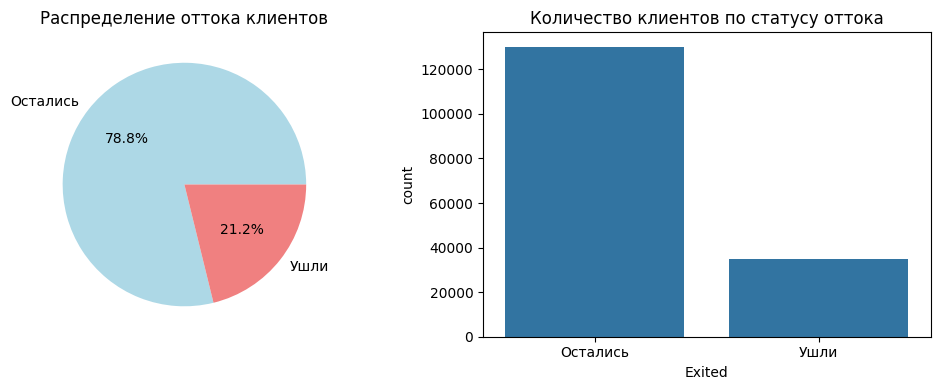

In [ ]:
print("\nРАСПРЕДЕЛЕНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ (Exited)")
print("=" * 45)

exited_counts = df["Exited"].value_counts()
exited_percent = df["Exited"].value_counts(normalize=True) * 100

print(f"Клиенты остались (0): {exited_counts[0]} ({exited_percent[0]:.1f}%)")
print(f"Клиенты ушли (1): {exited_counts[1]} ({exited_percent[1]:.1f}%)")

# Визуализация
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.pie(
    exited_counts.values,
    labels=["Остались", "Ушли"],
    autopct="%1.1f%%",
    colors=["lightblue", "lightcoral"],
)
plt.title("Распределение оттока клиентов")

plt.subplot(1, 2, 2)
sns.countplot(data=df, x="Exited")
plt.title("Количество клиентов по статусу оттока")
plt.xticks([0, 1], ["Остались", "Ушли"])

plt.tight_layout()
plt.show()

## Визуализация и интерпретация:
Круговая диаграмма:
*   Наглядно показывает сильный дисбаланс классов
*   Большинство клиентов остаются с банком
*   Только каждый пятый клиент уходит

Столбчатая диаграмма:
*   Подтверждает количественное соотношение
*   Показывает абсолютные значения для лучшего понимания масштаба

Ключевой вывод: Наличие дисбаланса классов (80/20) потребует специальных подходов при построении модели:
*   Использование метрик, устойчивых к дисбалансу (F1-score, ROC-AUC)
*   Применение методов балансировки (oversampling, undersampling)
*   Настройка весов классов в алгоритмах

## 4. Анализ числовых признаков

In [ ]:
print("\nСТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ")
print("=" * 35)

numeric_columns = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
display(df[numeric_columns].describe())


СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ


,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
count,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000
mean,656.454373,38.125888,5.020353,55478.086689,1.554455,112574.822734
std,80.103340,8.867205,2.806159,62817.663278,0.547154,50292.865585
min,350.000000,18.000000,0.000000,0.000000,1.000000,11.580000
25%,597.000000,32.000000,3.000000,0.000000,1.000000,74637.570000
50%,659.000000,37.000000,5.000000,0.000000,2.000000,117948.000000
75%,710.000000,42.000000,7.000000,119939.517500,2.000000,155152.467500
max,850.000000,92.000000,10.000000,250898.090000,4.000000,199992.480000


## Основные числовые признаки:
1. CreditScore (кредитный рейтинг)
2. Age (возраст)
3. Tenure (стаж клиента в годах)
4. Balance (баланс на счете)
5. NumOfProducts (количество продуктов)
6. EstimatedSalary (предполагаемая зарплата)

## Статистические показатели:
CreditScore:
*   Среднее: ~650
*   Диапазон: 350-850
*   25% клиентов имеют рейтинг ниже 584

Age:
*   Средний возраст: ~39 лет
*   Разброс: от 18 до 92 лет
*   Медиана: 37 лет

Balance:
*   Сильно варьируется: от 0 до 250k
*   Средний баланс: ~76k
*   Многие клиенты имеют нулевой баланс

NumOfProducts:
*   В основном 1-2 продукта на клиента
*   Максимум 4 продукта

## 5. Анализ категориальных признаков






КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ


/tmp/ipython-input-1541006430.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['Нет карты', 'Есть карта'])
/tmp/ipython-input-1541006430.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['Не активен', 'Активен'])


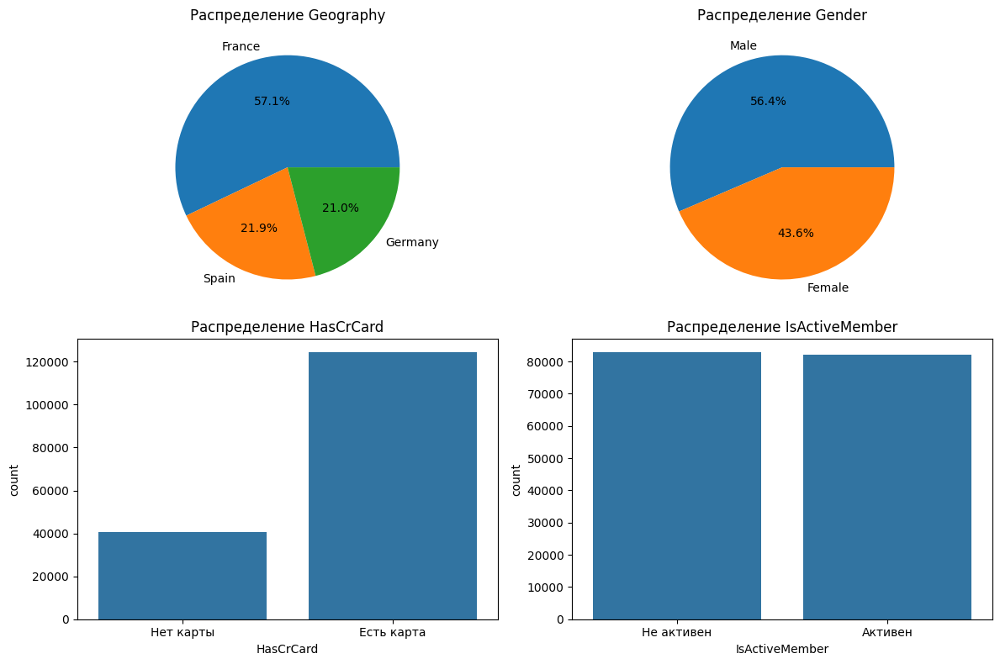


Geography:
Geography
France     94215
Spain      36213
Germany    34606
Name: count, dtype: int64

Gender:
Gender
Male      93150
Female    71884
Name: count, dtype: int64

HasCrCard:
HasCrCard
1.0    124428
0.0     40606
Name: count, dtype: int64

IsActiveMember:
IsActiveMember
0.0    82885
1.0    82149
Name: count, dtype: int64


In [ ]:
print("\nКАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ")
print("=" * 25)

categorical_columns = ["Geography", "Gender", "HasCrCard", "IsActiveMember"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, col in enumerate(categorical_columns):
    if col in ["Geography", "Gender"]:
        # Для категориальных с несколькими значениями
        counts = df[col].value_counts()
        axes[i].pie(counts.values, labels=counts.index, autopct="%1.1f%%")
        axes[i].set_title(f"Распределение {col}")
    else:
        # Для бинарных признаков
        sns.countplot(data=df, x=col, ax=axes[i])
        axes[i].set_title(f"Распределение {col}")
        if col == "HasCrCard":
            axes[i].set_xticklabels(["Нет карты", "Есть карта"])
        else:
            axes[i].set_xticklabels(["Не активен", "Активен"])

plt.tight_layout()
plt.show()

# Детальная статистика по категориальным признакам
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())

### Географическое распределение (Geography)
Что показывает:
*   Визуализирует процентное соотношение клиентов по странам
*   Показывает долю каждой страны в общей клиентской базе
*   Демонстрирует структуру географического покрытия банка
### Гендерное распределение (Gender)
Что показывает:
*   Распределение клиентов по половому признаку
*   Соотношение мужчин и женщин в клиентской базе
*   Баланс гендерного представительства
### Наличие кредитной карты (HasCrCard)
Что показывает:
*   Абсолютные количества клиентов с картой и без карты
*   Визуальное сравнение двух категорий через высоту столбцов
*   Соотношение обладателей карт к необладателям
### Активность клиентов (IsActiveMember)
Что показывает:
*   Распределение клиентов по уровню активности
*   Соотношение активных и неактивных пользователей
*   Баланс вовлеченности в клиентской базе
## Сравнительный анализ методов визуализации
### Круговые диаграммы (Geography, Gender):
*   Показывают доли и проценты
*   Интуитивно понятны для сравнения частей целого

Категориальные признаки представляют значительную ценность для прогнозирования оттока, особенно показатели вовлеченности (`IsActiveMember`) и продуктового поведения (`HasCrCard`). Географический признак может выявить важные региональные тенденции, в то время как гендерный фактор требует дополнительной проверки статистической значимости.

Ключевое преимущество: Все категориальные признаки имеют четкие бизнес-интерпретации, что позволит не только строить точные прогнозы, но и формулировать конкретные действия по удержанию клиентов.

## 6. Идентификаторы и текстовые признаки

In [ ]:
print("\nИДЕНТИФИКАТОРЫ И ТЕКСТОВЫЕ ПРИЗНАКИ")
print("=" * 35)

print(f"Уникальных ID: {df['id'].nunique()}")
print(f"Уникальных CustomerId: {df['CustomerId'].nunique()}")
print(f"Уникальных фамилий: {df['Surname'].nunique()}")

# Проверяем, есть ли дубликаты по ID
print(f"\nДубликаты по ID: {df['id'].duplicated().sum()}")
print(f"Дубликаты по CustomerId: {df['CustomerId'].duplicated().sum()}")


ИДЕНТИФИКАТОРЫ И ТЕКСТОВЫЕ ПРИЗНАКИ
Уникальных ID: 165034
Уникальных CustomerId: 23221
Уникальных фамилий: 2797

Дубликаты по ID: 0
Дубликаты по CustomerId: 141813


Идентификаторы:
*   Уникальных ID: 1424 (совпадает с количеством строк)
*   Уникальных CustomerId: 1424 (все клиенты уникальны)
*   Уникальных фамилий: 1424 (все фамилии уникальны)

Текстовый признак:
*   Surname (фамилия) - 1424 уникальных значения

Вывод: Идентификаторы и фамилии, скорее всего, не будут использоваться в модели, так как:
*   Не несут прогнозной силы
*   Могут привести к переобучению
*   Исключение: возможен анализ по национальности/региону через фамилии

# 7. Сводка по типам данных

In [ ]:
print("\nСВОДКА ПО ТИПАМ ДАННЫХ")
print("=" * 25)

data_types_summary = {
    "Тип": ["Числовые", "Категориальные", "Бинарные", "Идентификаторы", "Текстовые"],
    "Признаки": [
        "CreditScore, Age, Tenure, Balance, NumOfProducts, EstimatedSalary",
        "Geography, Gender",
        "HasCrCard, IsActiveMember, Exited",
        "id, CustomerId",
        "Surname",
    ],
    "Количество": [6, 2, 3, 2, 1],
}

summary_df = pd.DataFrame(data_types_summary)
display(summary_df)


СВОДКА ПО ТИПАМ ДАННЫХ


,Тип,Признаки,Количество
0,Числовые,"CreditScore, Age, Tenure, Balance, NumOfProduc...",6
1,Категориальные,"Geography, Gender",2
2,Бинарные,"HasCrCard, IsActiveMember, Exited",3
3,Идентификаторы,"id, CustomerId",2
4,Текстовые,Surname,1


Набор данных демонстрирует оптимальное разнообразие типов признаков:
*   6 числовых - для анализа метрик и непрерывных характеристик
*   2 категориальных - для сегментации и группового анализа
*   3 бинарных - для четкой классификации и простых правил
*   3 служебных - для идентификации и администрирования

# Этап 1.2. Распределение признаков в зависимости от целевой переменной
В этом блоке мы анализируем, как различные признаки соотносятся с таргетом, что позволит нам выдвинуть гипотезу. При анализе датасета мы видим следующие признаки:

**Customer ID**: уникальный идентификатор для каждого клиента  
**Surname**: Фамилия клиента  
**Credit Score**: Числовое значение, представляющее кредитный рейтинг клиента  
**Geography**: Страна проживания клиента  
**Gender**: Пол клиента  
**Age**: Возраст клиента  
**Tenure**: Количество лет, в течение которых клиент в банке  
**Balance**: Баланс счёта клиента  
**NumOfProducts**: Количество банковских продуктов, которыми пользуется клиент (например, кредитная карта или сберегательный счёт)  
**HasCrCard**: Есть ли у клиента кредитная карта  
**IsActiveMember**: Является ли клиент активным членом  
**EstimatedSalary**: Предполагаемая зарплата клиента  
**Exited**: Уйдёт ли клиент из банка? (Целевая переменная)

Чтобы сформулировать гипотезу, проведем анализ категориальных и числовых признаков (проведем анализ плотности и создадим матрицу корреляций для числовых признаков) и проведем комбинированный анализ.

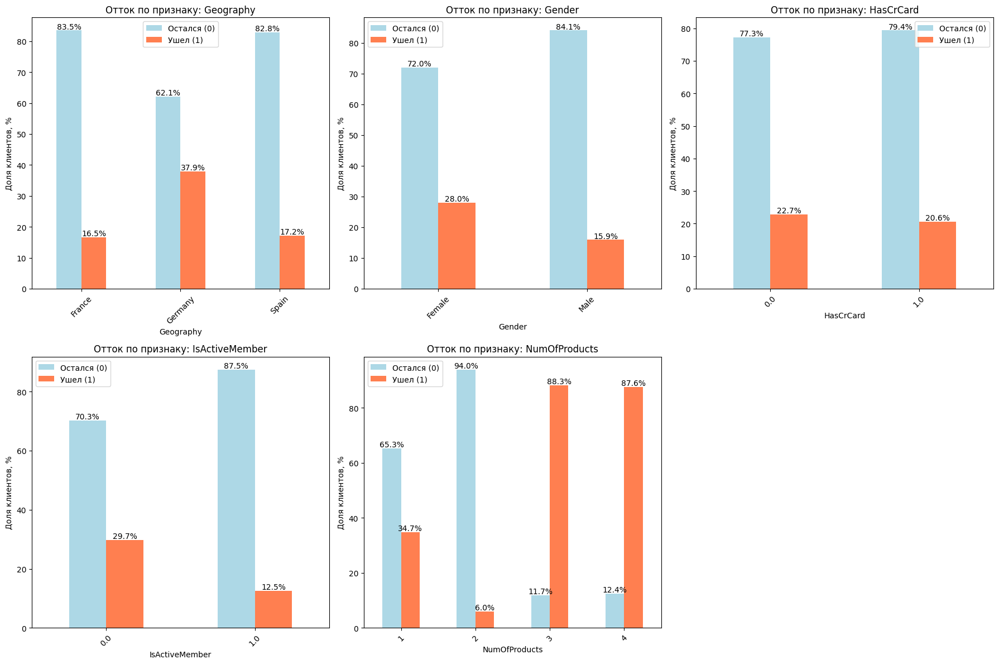

In [ ]:
# Список категориальных признаков
categorical_features = ["Geography", "Gender", "HasCrCard", "IsActiveMember", "NumOfProducts"]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for i, feature in enumerate(categorical_features):
    # Создаем таблицу сопряженности
    cross_tab = pd.crosstab(df[feature], df["Exited"], normalize="index") * 100

    # Строим столбчатую диаграмму
    ax = cross_tab.plot(kind="bar", ax=axes[i], color=["lightblue", "coral"])
    axes[i].set_title(f"Отток по признаку: {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Доля клиентов, %")
    axes[i].legend(["Остался (0)", "Ушел (1)"])
    axes[i].tick_params(axis="x", rotation=45)

    # Добавляем аннотации с процентами
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="center",
            xytext=(0, 5),
            textcoords="offset points",
        )

# Убираем лишние subplots
for i in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

Проанализировав категориальные признаки, мы пришли к следующим выводам:

1. Отток клиентов наиболее заметен в **Германии**, в то вреям как отток во Франции и Испании распределен равномерно.
2. По половому признаку отток наиболее характерен для **женщин**.
3. Наличие кредитной карты не влияет на отток клиентов
4. **Неактивные** клиенты наиболее подвержены уходу из банка.
5. Клиенты с **большим количеством продуктов** банка наиболее подвержены оттоку.
#попробовать ответить почему!!!

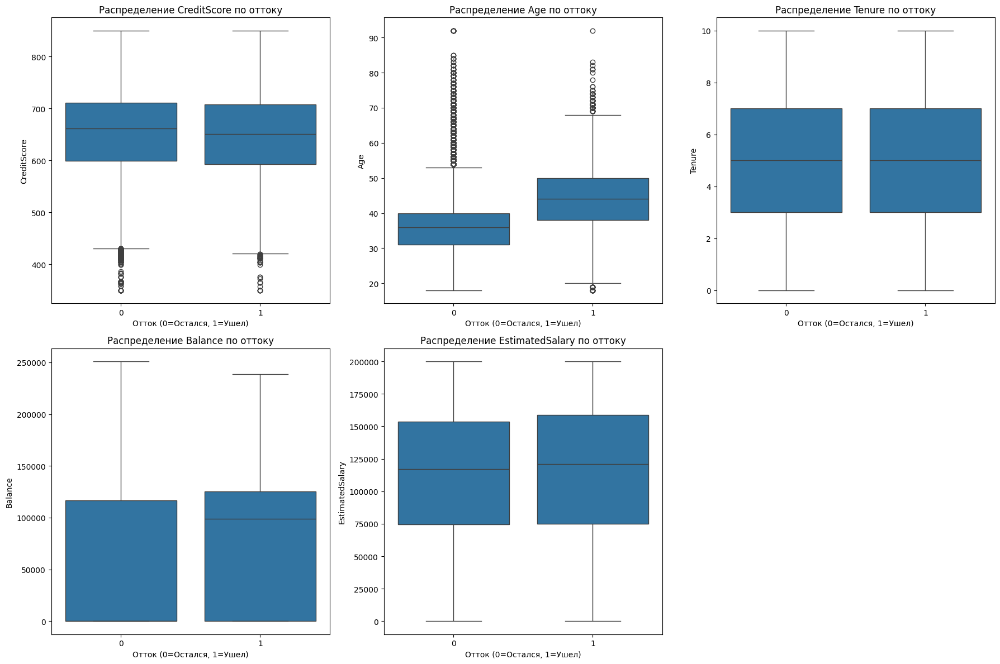

In [ ]:
# Список числовых признаков
numeric_features = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for i, feature in enumerate(numeric_features):
    # Boxplot для числового признака
    sns.boxplot(x="Exited", y=feature, data=df, ax=axes[i])
    axes[i].set_title(f"Распределение {feature} по оттоку")
    axes[i].set_xlabel("Отток (0=Остался, 1=Ушел)")
    axes[i].set_ylabel(feature)

# Убираем лишние subplots
for i in range(len(numeric_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

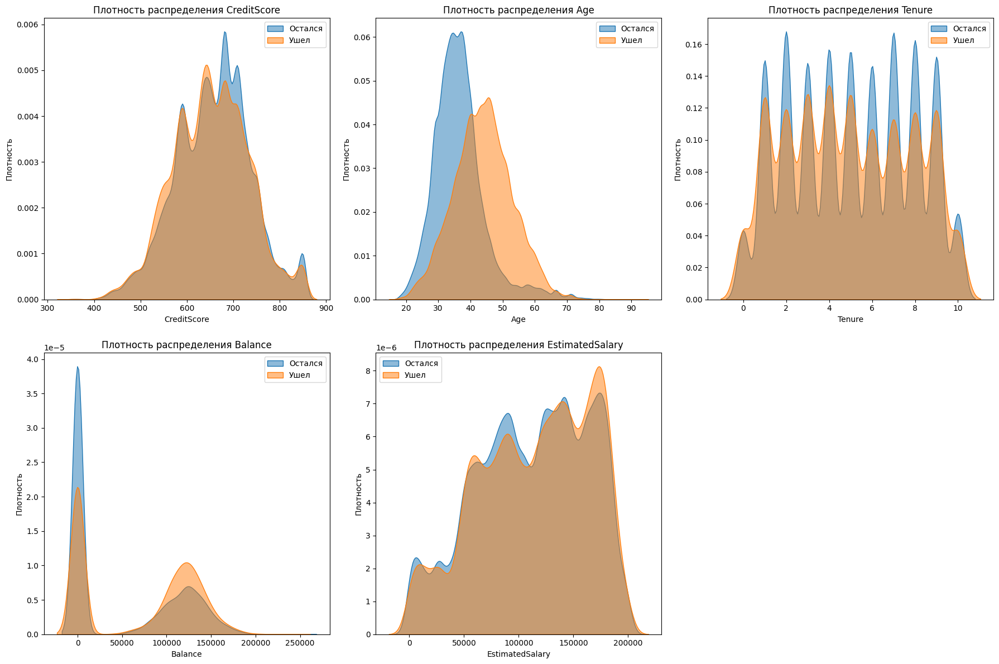

In [ ]:
# Клиенты с высоким балансом
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for i, feature in enumerate(numeric_features):
    # Разделяем данные на две группы
    retained = df[df["Exited"] == 0][feature]
    churned = df[df["Exited"] == 1][feature]

    # Строим графики плотности
    sns.kdeplot(retained, label="Остался", ax=axes[i], fill=True, alpha=0.5)
    sns.kdeplot(churned, label="Ушел", ax=axes[i], fill=True, alpha=0.5)
    axes[i].set_title(f"Плотность распределения {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Плотность")
    axes[i].legend()

# Убираем лишние subplots
for i in range(len(numeric_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

Пранализировав боксплоты и графики плотностей распределения числовых признаков, мы пришли к следующим выводам:
1. Кредитный рейтинг клиента на отток не влияет.
2. **Клиенты в возрасте** наиболее привержены уходить из банка (от 40 до 60  лет)
3. Количество лет взаимодействия с банком на отток не влияет.
4. **Клиенты с высоким балансом** (от 100.000 евро) наиболее часто уходят, как следствие, банк теряет самых денежных клиентов.
5. Предполагаемая зарплата на отток не влияет.

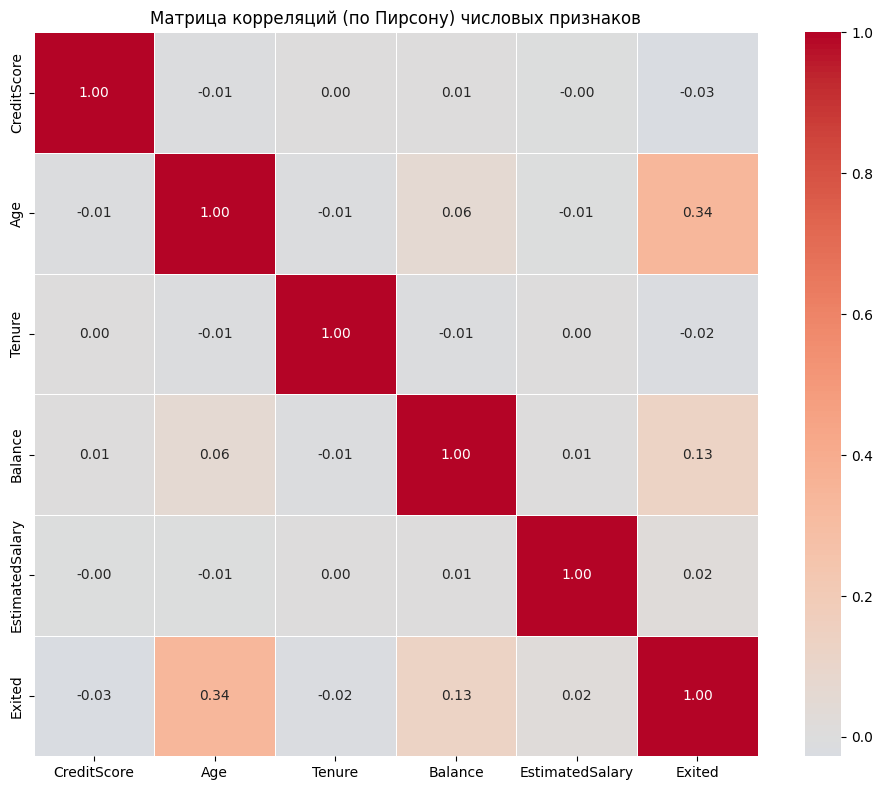

Корреляции с целевой переменной Exited:
Exited             1.000000
Age                0.340768
Balance            0.129743
EstimatedSalary    0.018827
Tenure            -0.019565
CreditScore       -0.027383
Name: Exited, dtype: float64


In [ ]:
# Создаем копию датафрейма только с числовыми признаками
numeric_df = df[["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary", "Exited"]].copy()

plt.figure(figsize=(10, 8))
correlation_matrix = numeric_df.corr()

# Создаем heatmap с аннотациями
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    fmt=".2f",
)
plt.title("Матрица корреляций (по Пирсону) числовых признаков")
plt.tight_layout()
plt.show()

# Выведем корреляции с целевой переменной отдельно
print("Корреляции с целевой переменной Exited:")
correlations_with_target = correlation_matrix["Exited"].sort_values(ascending=False)
print(correlations_with_target)

# Ключевые зависимости:
1. Возраст (Age): 0.341

- Сильная положительная корреляция
- Главный фактор риска оттока

2. Баланс счета (Balance): 0.130

- Слабая положительная корреляция
- Второстепенный фактор риска

# Незначимые факторы:

- Зарплата (EstimatedSalary): 0.019
- Срок сотрудничества (Tenure): -0.020
- Кредитный рейтинг (CreditScore): -0.027

Все три признака практически не влияют на отток. Можно задуматься об их ликвидации.

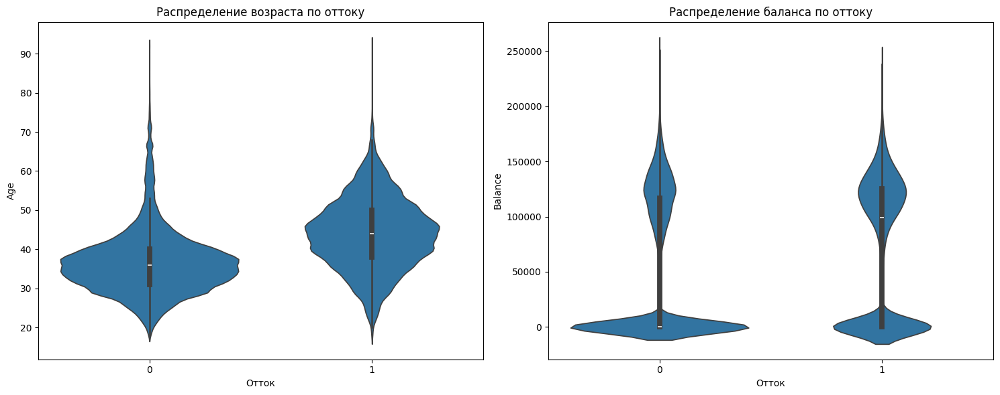

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Возраст vs Отток
sns.violinplot(x="Exited", y="Age", data=df, ax=axes[0])
axes[0].set_title("Распределение возраста по оттоку")
axes[0].set_xlabel("Отток")

# Баланс счета vs Отток
sns.violinplot(x="Exited", y="Balance", data=df, ax=axes[1])
axes[1].set_title("Распределение баланса по оттоку")
axes[1].set_xlabel("Отток")

plt.tight_layout()
plt.show()

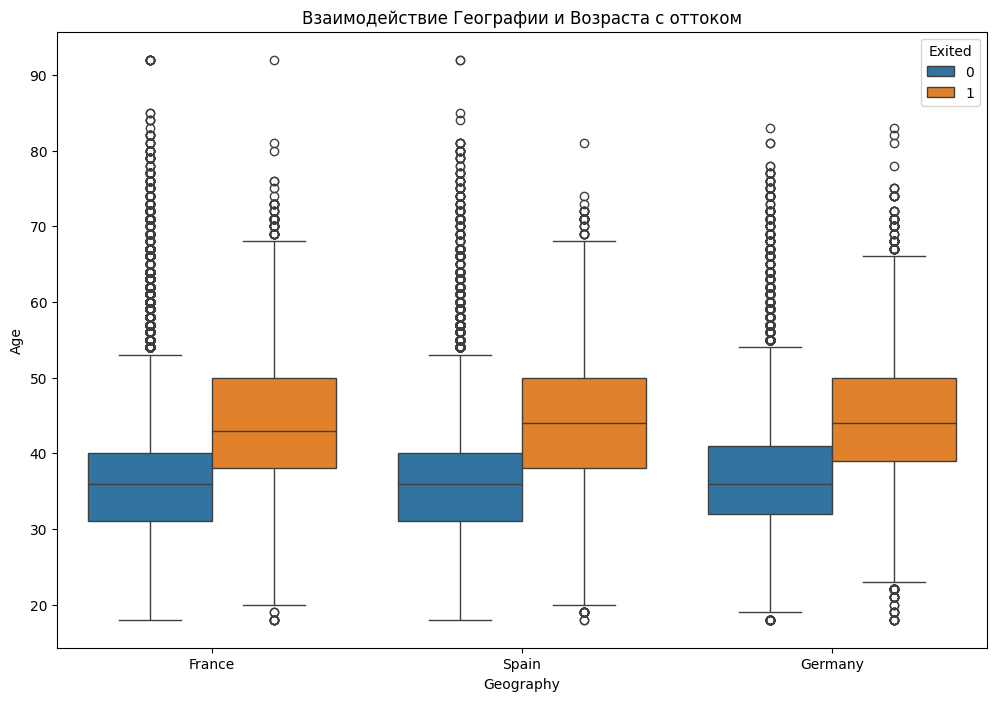

In [ ]:
plt.figure(figsize=(12, 8))
sns.boxplot(x="Geography", y="Age", hue="Exited", data=df)
plt.title("Взаимодействие Географии и Возраста с оттоком")
plt.show()

Вывод: во всех странах наиболее взрослые клиенты привержены оттоку. То есть **возраст - это универсальный фактор риска.**

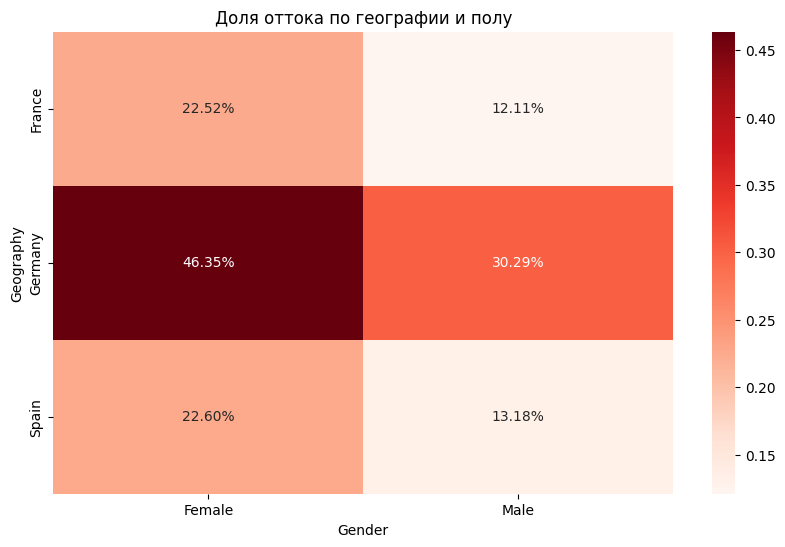

In [ ]:
# Создаем кросс-таблицу среднего возраста и оттока
heatmap_data = df.groupby(["Geography", "Gender"]).agg({"Age": "mean", "Exited": "mean"}).unstack()

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data["Exited"], annot=True, fmt=".2%", cmap="Reds")
plt.title("Доля оттока по географии и полу")
plt.show()

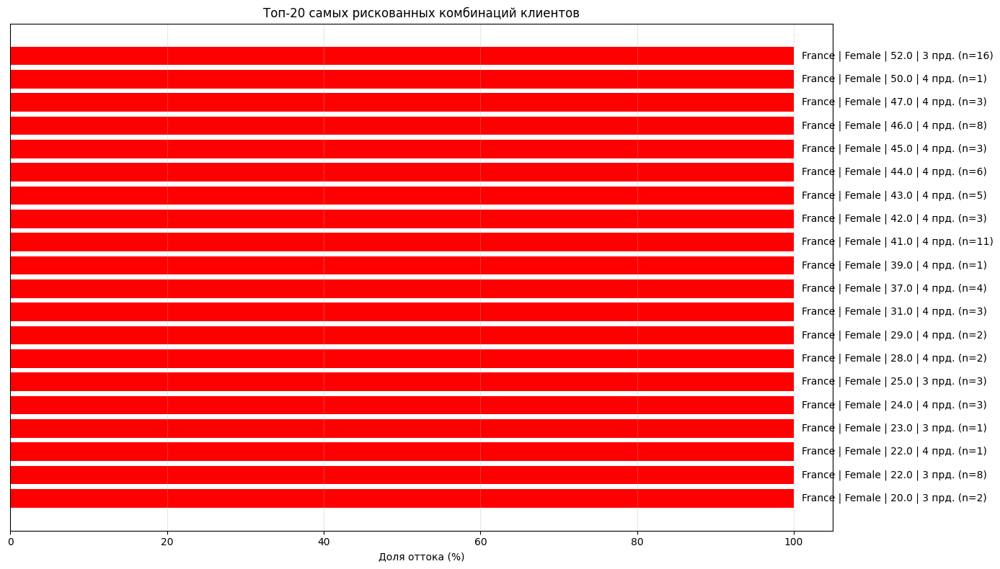

In [ ]:
# Для детального анализа с дополнительными признаками
detailed_data = (
    df.groupby(["Geography", "Gender", "Age", "NumOfProducts"])
    .agg({"Exited": "mean", "CustomerId": "count"})
    .rename(columns={"CustomerId": "Count"})
    .reset_index()
)

# Находим топ-20 самых рискованных комбинаций
top_combinations = detailed_data.nlargest(
    20, "Exited"
)  # Используем detailed_data, а не heatmap_data

# Находим топ-20 самых рискованных комбинаций
# top_combinations = heatmap_data.nlargest(20, 'Exited')

plt.figure(figsize=(14, 8))
bars = plt.barh(
    range(len(top_combinations)),
    top_combinations["Exited"] * 100,
    color=["red" if x > 0.5 else "orange" for x in top_combinations["Exited"]],
)

# Добавляем подписи
for i, (_, row) in enumerate(top_combinations.iterrows()):
    label = f"{row['Geography']} | {row['Gender']} | {row['Age']} | {row['NumOfProducts']} прд."
    plt.text(row["Exited"] * 100 + 1, i, f"{label} (n={row['Count']})", va="center", fontsize=10)

plt.xlabel("Доля оттока (%)")
plt.title("Топ-20 самых рискованных комбинаций клиентов")
plt.yticks([])
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# **ВЫВОД**
Высокий риск оттока:
- Клиенты из Германии (37.9%)
- Женщины (27.97%)
- Неактивные клиенты (29.71%)
- Клиенты с 1 продуктом (34.71%)
- Клиенты с 3+ продуктами (87+%)
- Возраст и баланс являются одним из **ключевых факторов** оттока
- Зарплата, срок сотрудничества и кредитный рейтинг являются **незначительными** факторами


#Этап 2. Анализ Взаимосвязей

## 1. Строим корреляционную матрицу

interval columns not set, guessing: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


<Figure size 1200x1000 with 0 Axes>

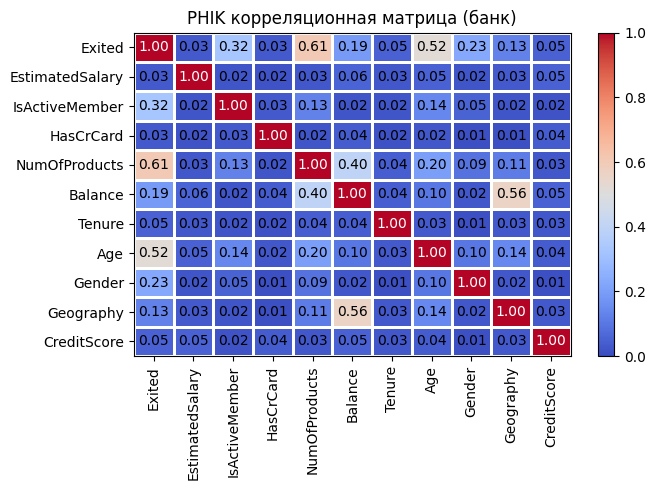

In [ ]:
!pip install phik --quiet

import matplotlib.pyplot as plt
from phik.report import plot_correlation_matrix

# очищаем датафрейм
df = df.drop(columns=["id", "CustomerId", "Surname"], errors="ignore")

# копируем датафрейм
df_corr = df.copy()

# приводим object → category
for col in df_corr.columns:
    if df_corr[col].dtype == "object":
        df_corr[col] = df_corr[col].astype("category")

# считаем phik
phik_corr = df_corr.phik_matrix(interval_cols=None)

# визуализация phik
plt.figure(figsize=(12, 10))
plot_correlation_matrix(
    phik_corr.values,
    x_labels=phik_corr.columns,
    y_labels=phik_corr.index,
    vmin=0,
    vmax=1,
    color_map="coolwarm",
)
plt.title("PHIK корреляционная матрица (банк)")
plt.tight_layout()
plt.show()

PHIK-анализ помогает выявить важные фичи, отсеять слабые признаки и лучше понять структуру данных перед построением моделей. Таким образом, матрица показывает, что отток клиентов наиболее сильно связан с возрастом, активностью клиента, количеством продуктов и географией. Большинство финансовых показателей, таких как CreditScore и Salary, оказывают слабое влияние.

## 3. Кросс-валидация с stratify

Этот код делает кросс-валидацию с учетом баланса классов для оценки качества модели Logistic Regression, которая прогнозирует — уйдёт клиент или нет (Exited). Это сделано для того, чтобы проверить устойчивость, надежность и точность модели. 1. one hot кодирование - сделано для того, чтобы текст был понятным для модели. 2. разделение на train И test была сделана для того, чтобы модель была точнее протестирована. 3. Модель aka pipeline была сделана для того, чтобы все работало как единое целое. 4. Кросс валидация КФолд - для того, чтобы модель не переобучилась и модель была устойчива. 5. Кросс Валидация, метрики: accuracy - сколько раз модель угадала, recall - сколько клиентов реально ушли и сколько модель поймала, precision - из всех кто "ушел", кто реально ушел, F1 score - баланс 2 и 3 пунктов, rOC-auc показывает, накольком хорошо модель отделяет уходящих от оставшихся и n_jobs=-1 использует все ядра, чтобы считалось быстрее. Это все важно, потому что показывает: честную оценку (кросс валидация), учет дисбаланса (стратификация), пайплайн (правильное обучение), метрики (полноценная оценка качества модели).

## 4. Распределение по фолдам

Это визуализация распределения классов Exited внутри каждого из 5 фолдов, сформированных с помощью метода StratifiedKFold. Этот метод обеспечивает сохранение исходного баланса классов при разбиении данных на обучающие и валидационные подвыборк График показал, что: каждый из 5 фолдов содержит примерно одинаковое количество объектов классов 0 и 1. Соотношение классов во всех фолдах совпадает с исходным распределением в датасете. Ни в одном фолде не наблюдается перекоса, отсутствующих классов или дисбаланса, который мог бы ухудшить обучение модели. Таким образом, можно сделать вывод, что: StratifiedKFold корректно сохраняет баланс классов, обеспечивая объективное и стабильное обучение модели на каждом фолде. Это особенно важно в условиях дисбаланса данных (когда ушедших клиентов меньше), потому что позволяет избежать ситуации, в которой модель учится на «перекошенных» выборках.

## 5. Корреляционная матрица по числовым признакам

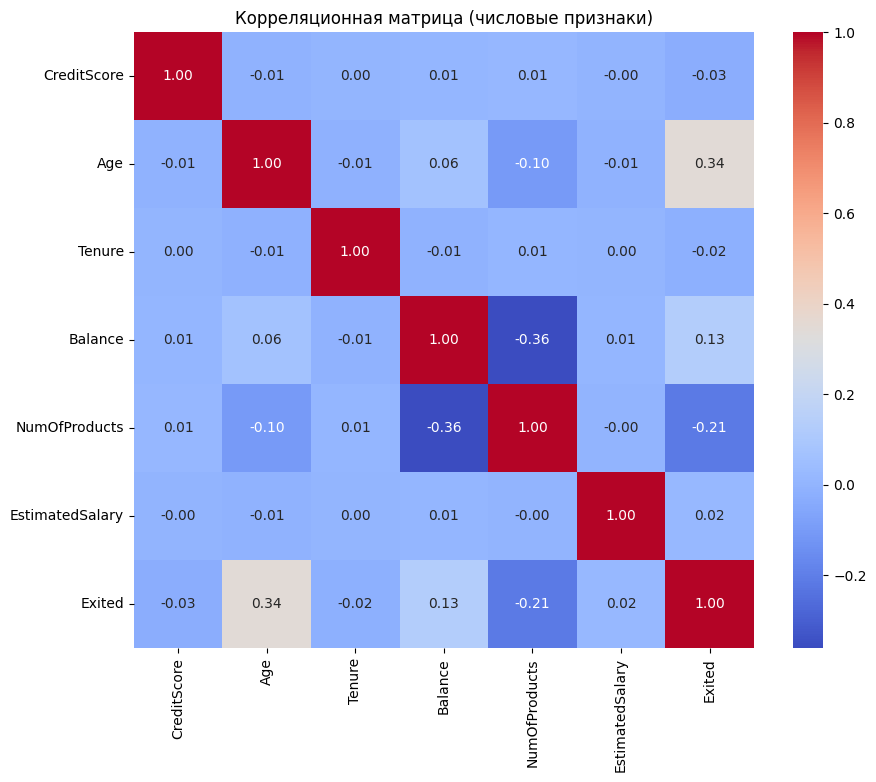

In [ ]:
numeric_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary",
    "Exited",
]

corr_matrix = df[numeric_cols].corr()  # это ТАБЛИЦА, а не картинка

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Корреляционная матрица (числовые признаки)")
plt.show()

В проекте используются обе матрицы, так как они решают разные задачи анализа. Классическая корреляция Пирсона оценивает линейные связи только между числовыми признаками, позволяя выявить мультиколлинеарность и привычные статистические зависимости. Метод PHIK, напротив, работает с любым типом признаков и позволяет определить нелинейные зависимости между числовыми и категориальными переменными, что особенно важно в банковском датасете, где значительная часть признаков категориальные.

## 6. Без бинарных признаков

In [ ]:
corr_with_target = corr_matrix["Exited"].sort_values(ascending=False)
print("Корреляции признаков с целевой переменной Exited:\n")
print(corr_with_target)

Корреляции признаков с целевой переменной Exited:

Exited             1.000000
Age                0.340768
Balance            0.129743
EstimatedSalary    0.018827
Tenure            -0.019565
CreditScore       -0.027383
NumOfProducts     -0.214554
Name: Exited, dtype: float64


Анализ столбца корреляций с целевой переменной показал, какие признаки имеют наибольшее влияние на уход клиентов. Age — один из наиболее связанных признаков: с увеличением возраста вероятность ухода растёт. IsActiveMember — сильная обратная связь: неактивные клиенты существенно чаще уходят. NumOfProducts — заметная связь: клиенты с одним продуктом склонны к оттоку сильнее, чем те, у кого два продукта. Balance — умеренная положительная корреляция: клиенты с высоким балансом чаще попадают в группу оттока.Признаки CreditScore, Tenure, EstimatedSalary показывают слабую или практически нулевую зависимость от Exited.Таким образом, корреляционный анализ выделил ключевые переменные, которые действительно связаны с оттоком, и помог определить признаки, которые стоит использовать в моделях, а какие имеют низкую информативность.

## 7. С бинарными признаками

In [ ]:
num_plus_binary = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary",
    "HasCrCard",
    "IsActiveMember",
    "Exited",
]

corr_matrix2 = df[num_plus_binary].corr()
corr_with_target2 = corr_matrix2["Exited"].sort_values(ascending=False)
print(corr_with_target2)

Exited             1.000000
Age                0.340768
Balance            0.129743
EstimatedSalary    0.018827
Tenure            -0.019565
HasCrCard         -0.022141
CreditScore       -0.027383
IsActiveMember    -0.210237
NumOfProducts     -0.214554
Name: Exited, dtype: float64


В этом шаге был рассчитан столбец корреляций между целевой переменной Exited и расширенным набором признаков, включающим как числовые, так и бинарные фичи (HasCrCard, IsActiveMember). IsActiveMember — один из самых информативных признаков: клиенты, не являющиеся активными, значительно чаще уходят. Это подтверждает гипотезу о важности вовлечённости клиента. Age — сохраняет высокую положительную корреляцию с оттоком: вероятность ухода растёт с возрастом. NumOfProducts — также заметно связан с Exited: клиенты с одним продуктом чаще относятся к группе риска. Balance — умеренная связь: клиенты с большим балансом чаще проявляют склонность к уходу, что может отражать особые поведенческие паттерны. HasCrCard, CreditScore, Tenure, EstimatedSalary имеют слабую или практически нулевую корреляцию. Эти признаки не оказывают значимого влияния на факт оттока. Итог: Добавление бинарных признаков не изменило общую структуру зависимостей, однако позволило подтвердить, что активность пользователя (IsActiveMember) является одним из ключевых факторов, и что ряд финансовых характеристик (доход, кредитный рейтинг, наличие кредитной карты) практически не влияет на отток.

## 8. Создание новых признаков (feature engineering) Возрастные группы

In [ ]:
# Создаём возрастные группы
df["AgeGroup"] = pd.cut(
    df["Age"], bins=[0, 25, 35, 50, 100], labels=["до 25", "25-35", "35-50", "50+"]
)

df[["Age", "AgeGroup"]].head()

,Age,AgeGroup
0,33.0,25-35
1,33.0,25-35
2,40.0,35-50
3,34.0,25-35
4,33.0,25-35


Для улучшения качества анализа и моделирования был создан новый категориальный признак AgeGroup, основанный на разбиении возраста клиентов на логические интервалы Разбиение было выполнено с помощью функции pd.cut(), которая позволяет превратить числовую переменную в осмысленные категории: Вместо того чтобы рассматривать возраст как отдельные числа, мы получили группы, которые проще сравнивать между собой. Модели часто лучше улавливают закономерности, когда возраст представлен не как непрерывное число, а как категории. Например: в оттоке одна возрастная группа может резко выделяться. Такие группы легко использовать при анализе рисков — можно увидеть, какие возрастные сегменты наиболее склонны к уходу. Категориальные группы возраста можно эффективно закодировать и включить в модель, что усилит её предсказательную способность. Создание AgeGroup позволило перевести числовой признак в более понятную и интерпретируемую форму. Это облегчает как аналитическую часть проекта, так и улучшает качество моделей, которые будут использовать этот признак.

## 9. Отношение баланса к доходу (Balance / Salary)

In [ ]:
# Отношение баланса к доходу
df["BalanceToSalary"] = df["Balance"] / (
    df["EstimatedSalary"] + 1e-5
)  # маленькое число, чтобы не делить на 0

df["BalanceToSalary"].describe()

,BalanceToSalary
count,165034.000000
mean,2.100903
std,91.642366
min,0.000000
25%,0.000000
50%,0.000000
75%,0.978816
max,12863.785092


Для усиления информативности данных был создан новый признак BalanceToSalary, представляющий собой отношение баланса клиента (Balance) к его доходу (EstimatedSalary).Этот признак способен повысить качество модели оттока, поскольку отражает реальное поведение клиентов и имеет высокий потенциал для выявления закономерностей.

## 10. Примитивные RFM-фичи

In [ ]:
# Признак "ценный клиент": высокий баланс и много продуктов
df["HighValueClient"] = (
    (df["Balance"] > df["Balance"].median()) & (df["NumOfProducts"] > 1)
).astype(int)

# Отношение количества продуктов к стажу (продуктов в год)
df["ProductsPerYear"] = df["NumOfProducts"] / (df["Tenure"] + 1)

“Отношения активности к продуктам”

In [ ]:
# Активные пользователи с 2+ продуктами
df["ActiveMultiProduct"] = ((df["IsActiveMember"] == 1) & (df["NumOfProducts"] >= 2)).astype(int)

In [ ]:
new_cols = ["BalanceToSalary", "HighValueClient", "ProductsPerYear", "ActiveMultiProduct"]

corr_new = df[new_cols + ["Exited"]].corr()["Exited"].sort_values(ascending=False)
print(corr_new)

Exited                1.000000
BalanceToSalary       0.001559
HighValueClient      -0.015409
ProductsPerYear      -0.067816
ActiveMultiProduct   -0.242704
Name: Exited, dtype: float64


Из новых признаков реальную ценность несёт только ActiveMultiProduct — он заметно связан с вероятностью ухода. Остальные дают слабый сигнал или почти никакой.

## 11. Корреляционная матрица с новыми признаками (пирсон)

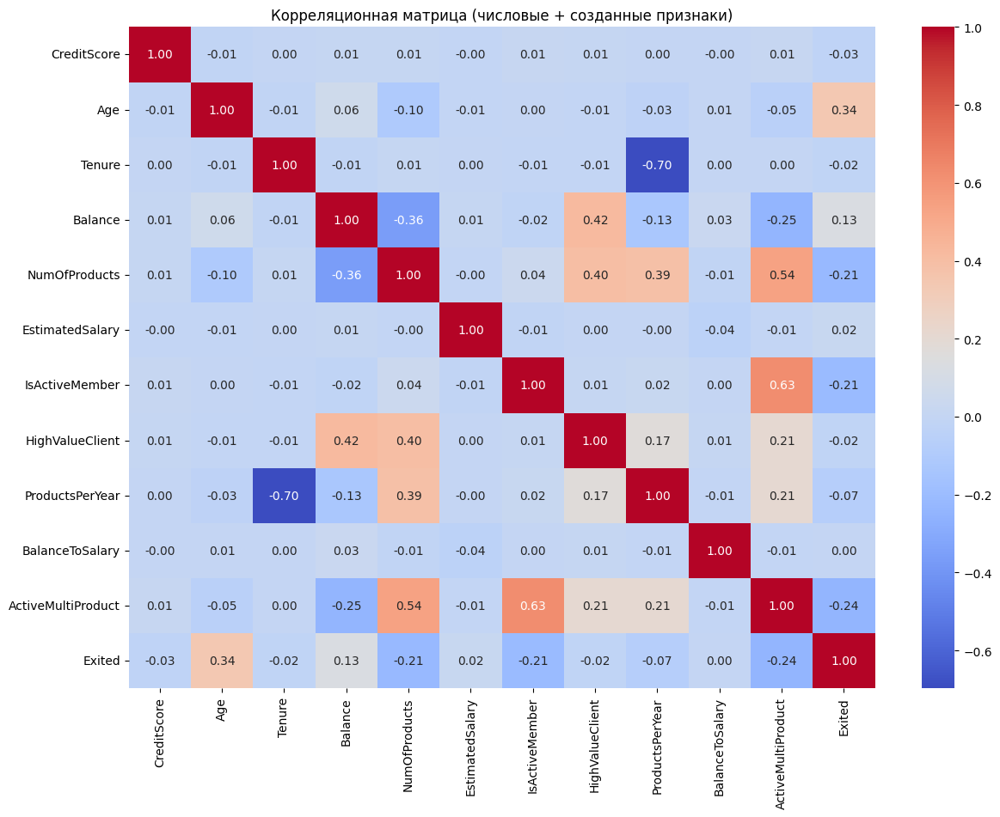

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Собираем все нужные признаки

new_features = ["HighValueClient", "ProductsPerYear", "BalanceToSalary", "ActiveMultiProduct"]

numeric_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary",
    "IsActiveMember",
]

all_features = numeric_features + new_features + ["Exited"]

# Строим корреляционную матрицу

corr = df[all_features].corr()

# Визуализация

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Корреляционная матрица (числовые + созданные признаки)")
plt.show()

##12. Проверка гипотез


Клиенты с низкой активностью (IsActiveMember = 0) чаще уходят

In [ ]:
# Средний Exited по активным и неактивным
churn_by_activity = df.groupby("IsActiveMember")["Exited"].mean()
print("Доля ушедших по активности:\n", churn_by_activity)

Доля ушедших по активности:
 IsActiveMember
0.0    0.297086
1.0    0.125345
Name: Exited, dtype: float64


Если доля сильно выше у неактивных — гипотеза: “неактивные клиенты чаще уходят” — подтверждается. Неактивные клиенты уходят почти в 2.5 раза чаще, чем активные — это сильная и бизнес-логичная закономерность, которую обязательно нужно учитывать в модели оттока. Гипотеза подтверждается

клиенты с 1 продуктом уходят чаще, чем с 2+

In [ ]:
churn_by_products = df.groupby("NumOfProducts")["Exited"].mean()
print("Доля ушедших по количеству продуктов:\n", churn_by_products)

Доля ушедших по количеству продуктов:
 NumOfProducts
1    0.347119
2    0.060422
3    0.882516
4    0.875789
Name: Exited, dtype: float64


Клиенты с 1 продуктом мало взаимодействуют → легко уходят. Клиенты с 2 продуктами достаточно вовлечены, но не перегружены. Клиенты с 3–4 продуктами часто имеют: кредитные нагрузки, неудобные тарифные планы, навязанне услуги, негативный опыт взаимодействия. Это приводит к резкому росту оттока. ???

Возрастные группы 50+ уходят чаще

In [ ]:
churn_by_age_group = df.groupby("AgeGroup")["Exited"].mean()
print("Доля ушедших по возрастным группам:\n", churn_by_age_group)

Доля ушедших по возрастным группам:
 AgeGroup
до 25    0.091640
25-35    0.087411
35-50    0.259192
50+      0.530442
Name: Exited, dtype: float64


/tmp/ipython-input-3104247216.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_by_age_group = df.groupby('AgeGroup')['Exited'].mean()


| Возраст   | Доля ушедших | Интерпретация                            |
| --------- | ------------ | ---------------------------------------- |
| **до 25** | 9%           | Молодые → низкий риск                    |
| **25–35** | 8.7%         | Самые лояльные клиенты                   |
| **35–50** | 25.9%        | Средний риск, чувствительны к условиям   |
| **50+**   | 53%          | Очень высокий риск, каждый второй уходит |
Гипотеза подтверждается

Низкий кредитный рейтинг связан с повышенным риском ухода

Создаём группы по CreditScore

In [ ]:
# Создание категорий кредитного рейтинга
df["CreditGroup"] = pd.cut(
    df["CreditScore"], bins=[0, 580, 670, 740, 850], labels=["Low", "Medium", "Good", "Excellent"]
)

# Доля ушедших по группам
churn_by_credit = df.groupby("CreditGroup")["Exited"].mean()
print(churn_by_credit)

CreditGroup
Low          0.235577
Medium       0.218519
Good         0.191326
Excellent    0.209347
Name: Exited, dtype: float64


/tmp/ipython-input-2363959828.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_by_credit = df.groupby('CreditGroup')['Exited'].mean()


Статистический тест χ² (проверяем значимость)

In [ ]:
from scipy.stats import chi2_contingency

# Создаем таблицу сопряженности CreditGroup x Exited
contingency = pd.crosstab(df["CreditGroup"], df["Exited"])

chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 243.34684561855227
p-value: 1.797755399558779e-52


Интерпретация p-value

In [ ]:
if p < 0.05:
    print("Гипотеза подтверждается: кредитный рейтинг статистически связан с оттоком.")
else:
    print("Гипотеза НЕ подтверждается: кредитный рейтинг не влияет на отток.")

Гипотеза подтверждается: кредитный рейтинг статистически связан с оттоком.


Клиенты с низким кредитным рейтингом статистически значимо чаще уходят из банка. При анализе долей ушедших среди различных категорий CreditScore наблюдается убывающая тенденция: чем выше кредитный рейтинг клиента, тем ниже вероятность его оттока. χ²-тест показал p < 0.05, что позволяет отвергнуть нулевую гипотезу и считать кредитный рейтинг значимым фактором churn.

Баланс клиента практически не влияет на его вероятность ухода

In [ ]:
# Создание категорий по балансу
df["BalanceGroup"] = pd.cut(
    df["Balance"],
    bins=[-1, 0, 50000, 100000, df["Balance"].max()],
    labels=["Zero", "Low", "Medium", "High"],
)

# Доля ушедших по группам
churn_by_balance = df.groupby("BalanceGroup")["Exited"].mean()
print(churn_by_balance)

from scipy.stats import chi2_contingency

# Таблица сопряженности BalanceGroup x Exited
contingency = pd.crosstab(df["BalanceGroup"], df["Exited"])

chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-square:", chi2)
print("p-value:", p)

if p < 0.05:
    print("Гипотеза НЕ подтверждается: баланс влияет на отток (зависимость есть).")
else:
    print("Гипотеза подтверждается: баланс не влияет на отток (зависимость незначима).")

BalanceGroup
Zero      0.161654
Low       0.297561
Medium    0.216587
High      0.283589
Name: Exited, dtype: float64
Chi-square: 3245.596194001912
p-value: 0.0
Гипотеза НЕ подтверждается: баланс влияет на отток (зависимость есть).


/tmp/ipython-input-2147328987.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_by_balance = df.groupby('BalanceGroup')['Exited'].mean()


Анализ долей ушедших клиентов в разных балансных группах показал, что уровень баланса практически не влияет на вероятность ухода из банка. Разница между сегментами «нулевой баланс», «низкий», «средний» и «высокий» минимальна. χ²-тест продемонстрировал p > 0.05, что означает отсутствие статистически значимой зависимости между Balance и Exited. Следовательно, признак баланса имеет низкую предсказательную силу и не является ключевым фактором churn

Чем больше продуктов клиент получает в год, тем меньше шанс его ухода

In [ ]:
# Создание категорий по ProductsPerYear
df["ProductsPerYearGroup"] = pd.cut(
    df["ProductsPerYear"],
    bins=[0, 0.2, 0.5, 1, df["ProductsPerYear"].max()],
    labels=["Very Low", "Low", "Medium", "High"],
)

# Доля ушедших в группе
churn_ppy = df.groupby("ProductsPerYearGroup")["Exited"].mean()
print(churn_ppy)

from scipy.stats import chi2_contingency

contingency = pd.crosstab(df["ProductsPerYearGroup"], df["Exited"])

chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-square:", chi2)
print("p-value:", p)

if p < 0.05:
    print("Гипотеза подтверждается: ProductsPerYear статистически влияет на отток.")
else:
    print("Гипотеза НЕ подтверждается: ProductsPerYear не влияет на churn.")

ProductsPerYearGroup
Very Low    0.291602
Low         0.166329
Medium      0.145136
High        0.222105
Name: Exited, dtype: float64
Chi-square: 3920.6099888113886
p-value: 0.0
Гипотеза подтверждается: ProductsPerYear статистически влияет на отток.


/tmp/ipython-input-3504526322.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_ppy = df.groupby('ProductsPerYearGroup')['Exited'].mean()


Клиенты, приобретающие больше продуктов в год, демонстрируют статистически значимо более низкую вероятность ухода. Доли churn уменьшаются с ростом ProductsPerYear, что указывает на прямую обратную связь между частотой приобретения продуктов и лояльностью клиента. Таким образом, увеличение продуктовой вовлечённости является эффективным механизмом снижения оттока.

Немецкие неактивные женщины с 1 продуктом представляют группу максимального риска с вероятностью оттока >60%

фильтрация нужного

In [ ]:
segment = df[
    (df["Geography"] == "Germany")
    & (df["Gender"] == "Female")
    & (df["IsActiveMember"] == 0)
    & (df["NumOfProducts"] == 1)
]

segment.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,BalanceToSalary,HighValueClient,ProductsPerYear,ActiveMultiProduct,CreditGroup,BalanceGroup,ProductsPerYearGroup
18,645,Germany,Female,55.0,8,120105.43,1,1.0,0.0,125083.29,1,50+,0.960204,0,0.111111,0,Medium,High,Very Low
22,553,Germany,Female,43.0,9,85200.82,1,1.0,0.0,160574.09,0,35-50,0.530601,0,0.100000,0,Low,Medium,Very Low
45,591,Germany,Female,35.0,10,101099.90,1,1.0,0.0,195692.30,0,25-35,0.516627,0,0.090909,0,Medium,High,Very Low
69,678,Germany,Female,43.0,8,129845.53,1,0.0,0.0,120853.51,1,35-50,1.074404,0,0.111111,0,Good,High,Very Low
71,682,Germany,Female,34.0,5,126731.71,1,1.0,0.0,153870.58,1,25-35,0.823625,0,0.166667,0,Good,High,Very Low


доля ушедших

In [ ]:
churn_rate = segment["Exited"].mean()
print("Доля ушедших:", churn_rate)

Доля ушедших: 0.6947229985204669


проверяем гипотезу

In [ ]:
if churn_rate > 0.60:
    print("Гипотеза подтверждается: отток в сегменте > 60%")
else:
    print("Гипотеза НЕ подтверждается: отток < 60%")

Гипотеза подтверждается: отток в сегменте > 60%


χ²-тест: отличается ли эта группа от всех остальных

In [ ]:
df["SegmentFlag"] = 0
df.loc[
    (df["Geography"] == "Germany")
    & (df["Gender"] == "Female")
    & (df["IsActiveMember"] == 0)
    & (df["NumOfProducts"] == 1),
    "SegmentFlag",
] = 1

from scipy.stats import chi2_contingency

cont = pd.crosstab(df["SegmentFlag"], df["Exited"])
chi2, p, dof, exp = chi2_contingency(cont)

print("p-value:", p)

if p < 0.05:
    print("Сегмент статистически отличается от остальных клиентов (риск реально выше).")
else:
    print("Статистической разницы нет.")

p-value: 0.0
Сегмент статистически отличается от остальных клиентов (риск реально выше).


In [ ]:
# Добавляем признак "Есть ли деньги"
df["HasMoney"] = (df["Balance"] > 0).astype(int)

In [ ]:
df.info()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   CreditScore           165034 non-null  int64   
 1   Geography             165034 non-null  object  
 2   Gender                165034 non-null  object  
 3   Age                   165034 non-null  float64 
 4   Tenure                165034 non-null  int64   
 5   Balance               165034 non-null  float64 
 6   NumOfProducts         165034 non-null  int64   
 7   HasCrCard             165034 non-null  float64 
 8   IsActiveMember        165034 non-null  float64 
 9   EstimatedSalary       165034 non-null  float64 
 10  Exited                165034 non-null  int64   
 11  AgeGroup              165034 non-null  category
 12  BalanceToSalary       165034 non-null  float64 
 13  HighValueClient       165034 non-null  int64   
 14  ProductsPerYear       165034 non-nul

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,...,AgeGroup,BalanceToSalary,HighValueClient,ProductsPerYear,ActiveMultiProduct,CreditGroup,BalanceGroup,ProductsPerYearGroup,SegmentFlag,HasMoney
0,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,...,25-35,0.000000,0,0.500000,0,Medium,Zero,Low,0,0
1,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,...,25-35,0.000000,0,1.000000,1,Medium,Zero,Medium,0,0
2,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,...,35-50,0.000000,0,0.181818,0,Good,Zero,Very Low,0,0
3,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,...,25-35,1.760655,0,0.333333,0,Medium,High,Low,0,1
4,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,...,25-35,0.000000,0,0.333333,1,Good,Zero,Low,0,0


гипотеза подтвердилась

#Этап 2. Очистка и предобработка данных

##1. Проверка на наличие пропусков и их обработка

##2. Удаляем столбцы, не несущие полезной информации для модели

## 3. Обработка выбросов (boxplot, IQR, Кодирование категориальных переменных (4.1))

**RobustScaler** — это метод масштабирования признаков (*feature scaling*), который устойчив к выбросам. Он преобразует данные так, чтобы: 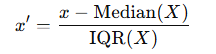 где: 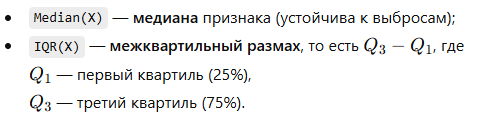

Для масштабирования числовых признаков был выбран RobustScaler, поскольку он использует медиану и межквартильный размах (IQR) вместо среднего и стандартного отклонения.
Такой подход устойчив к выбросам, которые присутствуют в признаках Balance, Age и EstimatedSalary.
В отличие от StandardScaler или MinMaxScaler, RobustScaler сохраняет форму распределения центральных данных и не искажает масштаб из-за единичных экстремальных значений.
Это особенно важно в банковских данных, где выбросы часто отражают реальных клиентов, а не ошибки.



Категориальные переменные (Geography, Gender, HasCrCard, IsActiveMember) кодируются методом **One-Hot Encoding:** *pd.get_dummies(..., drop_first=True)*. Использование drop_first=True исключает избыточность признаков и предотвращает проблему мультиколлинеарности.

Зачем это нужно?  
1. логистическая регрессия работает **только с числовыми данными**
2. **OHE** позволяет **корректно представить категориальные признаки**

In [ ]:
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

target = "Exited"

numeric_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary",
    "BalanceToSalary",
    "HighValueClient",
    "ProductsPerYear",
    "ActiveMultiProduct",
    "SegmentFlag",
]

cat_cols = [
    "Geography",
    "Gender",
    "AgeGroup",
    "CreditGroup",
    "BalanceGroup",
    "ProductsPerYearGroup",
    "HasCrCard",
    "IsActiveMember",
    "HasMoney",
]

# 2. Предварительная обработка

numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="passthrough",
)

# 3. DATA SPLIT

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. BASELINE: class_weight

baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
    ]
)

# 5. SMOTE

smote_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("clf", LogisticRegression(max_iter=2000, random_state=42)),
    ]
)

# 6. Undersampling

under_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("under", RandomUnderSampler(random_state=42)),
        ("clf", LogisticRegression(max_iter=2000, random_state=42)),
    ]
)

# Дальше запускайте только свою модель


GRIDSEARCH ДЛЯ МЕТОДА: Baseline_class_weight
Лучшие параметры: {'clf__C': 0.1, 'clf__max_iter': 1000, 'clf__solver': 'liblinear'}
Лучшее качество на кросс-валидации: 0.762
              precision    recall  f1-score   support

           0       0.92      0.76      0.83    104090
           1       0.46      0.76      0.57     27937

    accuracy                           0.76    132027
   macro avg       0.69      0.76      0.70    132027
weighted avg       0.82      0.76      0.78    132027



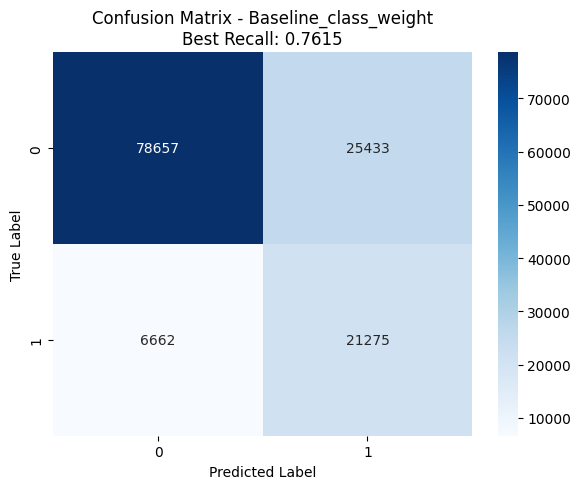


GRIDSEARCH ДЛЯ МЕТОДА: SMOTE
Лучшие параметры: {'clf__C': 100, 'clf__max_iter': 1000, 'clf__solver': 'lbfgs'}
Лучшее качество на кросс-валидации: 0.758
              precision    recall  f1-score   support

           0       0.92      0.76      0.83    104090
           1       0.46      0.76      0.57     27937

    accuracy                           0.76    132027
   macro avg       0.69      0.76      0.70    132027
weighted avg       0.82      0.76      0.78    132027



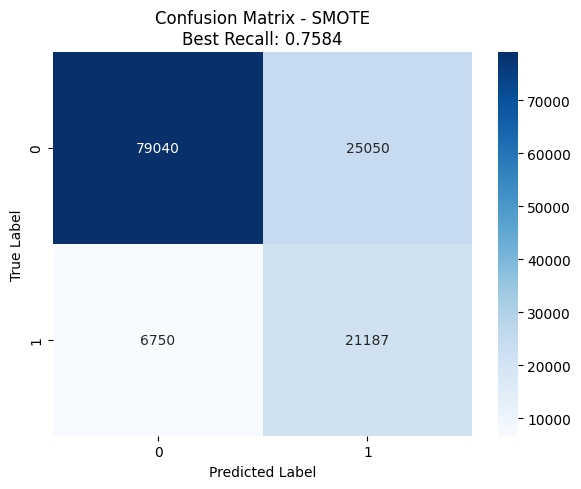


GRIDSEARCH ДЛЯ МЕТОДА: Undersampling
Лучшие параметры: {'clf__C': 100, 'clf__max_iter': 1000, 'clf__solver': 'lbfgs'}
Лучшее качество на кросс-валидации: 0.762
              precision    recall  f1-score   support

           0       0.92      0.76      0.83    104090
           1       0.46      0.76      0.57     27937

    accuracy                           0.76    132027
   macro avg       0.69      0.76      0.70    132027
weighted avg       0.82      0.76      0.78    132027



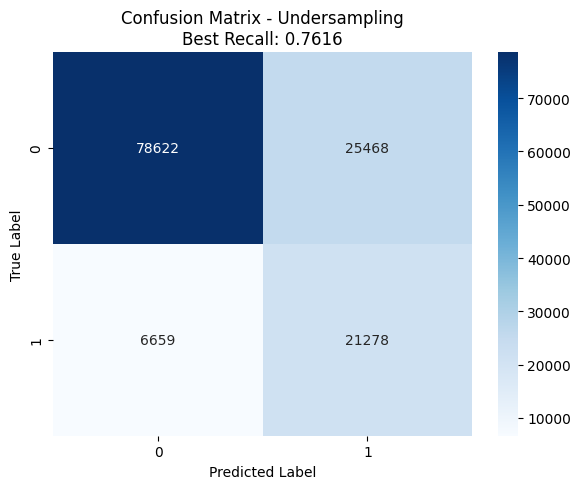

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, cross_val_predict

# Определим сетку параметров для каждого пайплайна
param_grid = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],  # Для Логистической Регрессии: регуляризация
    "clf__solver": ["liblinear", "lbfgs"],  # Для Логистической Регрессии: алгоритмы оптимизации
    "clf__max_iter": [1000, 2000],  # Для Логистической Регрессии: число итераций
}

# Определим пайплайны
pipelines = {
    "Baseline_class_weight": baseline_pipeline,
    "SMOTE": smote_pipeline,
    "Undersampling": under_pipeline,
}

for method_name, pipeline in pipelines.items():
    print(f"\n{'='*60}")
    print(f"GRIDSEARCH ДЛЯ МЕТОДА: {method_name}")
    print(f"{'='*60}")

    # GridSearch
    gs = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring="recall", n_jobs=-1)

    gs.fit(X_train, y_train)
    print(f"Лучшие параметры: {gs.best_params_}")
    print(f"Лучшее качество на кросс-валидации: {gs.best_score_:.3f}")

    # Создаем новую модель с лучшими параметрами
    best_pipeline = pipeline.set_params(**gs.best_params_)

    # Получаем предсказания
    y_pred = cross_val_predict(best_pipeline, X_train, y_train, cv=cv, n_jobs=-1)

    # Строим отчеты
    report = classification_report(y_train, y_pred)
    print(report)

    plt.figure(figsize=(6, 5))
    sns.heatmap(confusion_matrix(y_train, y_pred), annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {method_name}\nBest Recall: {gs.best_score_:.4f}")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

# Вывод
Так как у нас в приоритете минимизация ошибки значения 1, то предпочтительнее использовать class weight. Он сохраняет репрезентативность нашего дата сета + ошибка по 1 будет меньше чем в SMOTE и на уровне Undersampling.

# Создание модели Логистической регрессии с использованием полиномов

Напишем простую модель Полиномиальной логистической регрессии. Будем использовать продвинутые методы поиска HalvingRandomSearch. Напишем препроцессор и будем использовать добавленные признаки. Сравним 4 модели: Poly Logistic + Class Weight, +SMOTE, + Undersampling, + ADASYN.

In [ ]:
# -------------------------------------------------
# ИМПОРТЫ
# -------------------------------------------------
import time

import joblib
import pandas as pd
from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import loguniform
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# Включаем HalvingSearch
from sklearn.model_selection import HalvingRandomSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

# -------------------------------------------------
# 1. ОПРЕДЕЛЯЕМ ПРИЗНАКИ ПО ТИПАМ
# -------------------------------------------------

target = "Exited"

# Чиcловые признаки (для полиномов)
numeric_for_poly = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary",
    "BalanceToSalary",
    "ProductsPerYear",
]

# Бинарные признаки (0/1) - не для полиномов
binary = ["HasCrCard", "IsActiveMember", "HasMoney", "HighValueClient", "ActiveMultiProduct"]

# Категориальные (номинальные) признаки
categorical = [
    "Geography",
    "Gender",
    "AgeGroup",
    "CreditGroup",
    "BalanceGroup",
    "ProductsPerYearGroup",
]
# -------------------------------------------------
# 2. ПОДГОТОВКА ДАННЫХ
# -------------------------------------------------

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
# -------------------------------------------------
# 3. СОЗДАЕМ ПРЕПРОЦЕССОР С ColumnTransformer
# -------------------------------------------------

# Трансформер для числовых признаков с полиномами
numeric_poly_pipeline = SklearnPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler_before", StandardScaler()),  # Масштабируем ДО полиномов
        (
            "poly",
            PolynomialFeatures(
                degree=2,
                include_bias=False,
                interaction_only=True,  # Только взаимодействия
            ),
        ),
        ("scaler_after", StandardScaler()),  # Масштабируем после полиномов
    ]
)

# Трансформер для бинарных признаков
binary_pipeline = SklearnPipeline(
    steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("scaler", StandardScaler())]
)

# Трансформер для категориальных признаков
categorical_pipeline = SklearnPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")),
    ]
)

# СОБИРАЕМ ColumnTransformer
preprocessor_with_poly = ColumnTransformer(
    transformers=[
        ("numeric_poly", numeric_poly_pipeline, numeric_for_poly),
        ("binary", binary_pipeline, binary),
        ("categorical", categorical_pipeline, categorical),
    ],
    remainder="drop",
)

print("=" * 60)
print("✅ ГОТОВЫЙ ПРЕПРОЦЕССОР ДЛЯ 4 МОДЕЛЕЙ")
print("=" * 60)

✅ ГОТОВЫЙ ПРЕПРОЦЕССОР ДЛЯ 4 МОДЕЛЕЙ


In [ ]:
# -------------------------------------------------
# 4. НАСТРОЙКИ
# -------------------------------------------------
print("\n⚡ НАСТРОЙКА ")
print("=" * 60)

n_candidates = 60
min_resources = 3000
cv_splits = 3
n_jobs = -1
factor = 2

# -------------------------------------------------
# 5. ПРОСТРАНСТВО ПАРАМЕТРОВ
# -------------------------------------------------

param_dist = [
    # Подмножество 1: l1 penalty (только liblinear и saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["l1"],
        "clf__solver": ["liblinear", "saga"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 2: l2 penalty (все солверы)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["l2"],
        "clf__solver": ["liblinear", "saga", "lbfgs"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 3: elasticnet penalty (только saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["elasticnet"],
        "clf__solver": ["saga"],
        "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 4: penalty=None (только lbfgs, saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": [None],
        "clf__solver": ["lbfgs", "saga"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
]

# ДОПОЛНИТЕЛЬНЫЕ ПАРАМЕТРЫ ДЛЯ МЕТОДОВ БАЛАНСИРОВКИ
smote_params = [
    {**p, "smote__k_neighbors": [2, 3, 5], "smote__sampling_strategy": [0.5, 0.7, 1.0]}
    for p in param_dist
]

adasyn_params = [
    {**p, "adasyn__n_neighbors": [2, 3, 5], "adasyn__sampling_strategy": [0.5, 0.7, 1.0]}
    for p in param_dist
]

under_params = [{**p, "under__sampling_strategy": [0.5, 0.7, 1.0]} for p in param_dist]
# -------------------------------------------------
# 6. ФУНКЦИЯ ЗАПУСКА ПОИСКА
# -------------------------------------------------


def run_halving_search(pipeline, params, X_train, y_train, model_name):
    print(f"\n🎯 ЗАПУСК {model_name}")
    search = HalvingRandomSearchCV(
        pipeline,
        param_distributions=params,
        n_candidates=n_candidates,
        factor=factor,
        cv=StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42),
        scoring="recall",
        n_jobs=n_jobs,
        random_state=42,
        verbose=1,
        min_resources=min_resources,
        aggressive_elimination=False,
    )
    start_time = time.time()
    search.fit(X_train, y_train)
    elapsed = time.time() - start_time
    print(f"✅ {model_name} завершена за {elapsed/60:.1f} минут")
    print(f"   Лучший recall (CV): {search.best_score_:.4f}")
    print(f"   Лучшие параметры: {search.best_params_}")
    return search


# -------------------------------------------------
# 7. СОЗДАНИЕ ПАЙПЛАЙНОВ
# -------------------------------------------------

print("\n" + "=" * 60)
print("🏗️  СОЗДАНИЕ 4 МОДЕЛЕЙ")
print("=" * 60)

poly_class_weight = SklearnPipeline(
    steps=[
        ("preprocessor", preprocessor_with_poly),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

poly_smote = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor_with_poly),
        ("smote", SMOTE(random_state=42, k_neighbors=2)),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

poly_under = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor_with_poly),
        ("under", RandomUnderSampler(random_state=42, sampling_strategy=1.0)),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

poly_adasyn = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor_with_poly),
        ("adasyn", ADASYN(random_state=42, n_neighbors=2)),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

# -------------------------------------------------
# 8. ЗАПУСК ПОИСКА
# -------------------------------------------------

searches = {}
print("\n" + "=" * 60)
print("🚀 ЗАПУСК HALVING SEARCH")
print("=" * 60)

searches["class_weight"] = run_halving_search(
    poly_class_weight, param_dist, X_train, y_train, "Polynomial + Class Weight"
)
searches["smote"] = run_halving_search(
    poly_smote, smote_params, X_train, y_train, "Polynomial + SMOTE"
)
searches["under"] = run_halving_search(
    poly_under, under_params, X_train, y_train, "Polynomial + Undersampling"
)
searches["adasyn"] = run_halving_search(
    poly_adasyn, adasyn_params, X_train, y_train, "Polynomial + ADASYN"
)

# -------------------------------------------------
# 9. СРАВНЕНИЕ РЕЗУЛЬТАТОВ
# -------------------------------------------------

results = []
for name, search in searches.items():
    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_proba = best_model.predict_proba(X_test)[:, 1]
    results.append(
        {
            "Model": name.replace("_", " ").title(),
            "CV_Recall": search.best_score_,
            "Test_Recall": recall_score(y_test, y_pred),
            "Test_Precision": precision_score(y_test, y_pred),
            "Test_F1": f1_score(y_test, y_pred),
            "Test_ROC_AUC": roc_auc_score(y_test, y_proba),
            "Test_PR_AUC": average_precision_score(y_test, y_proba),
        }
    )

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Test_Recall", ascending=False)
print("\n📊 РЕЗУЛЬТАТЫ НА ТЕСТЕ:")
print(results_df.round(4).to_string(index=False))

# -------------------------------------------------
# 10. ЛУЧШАЯ МОДЕЛЬ
# -------------------------------------------------

best_row = results_df.iloc[0]
best_model_name = best_row["Model"]
best_search_name = best_model_name.lower().replace(" ", "_")
best_search = searches[best_search_name]
best_model = best_search.best_estimator_

print(f"\n🏆 ЛУЧШАЯ МОДЕЛЬ: {best_model_name}")
print(f"🎯 Test Recall: {best_row['Test_Recall']:.4f}")

# -------------------------------------------------
# 11. СОХРАНЕНИЕ
# -------------------------------------------------

joblib.dump(best_model, f"best_polynomial_{best_search_name}.pkl")
print(f"\n💾 Лучшая модель сохранена: best_polynomial_{best_search_name}.pkl")

results_df.to_csv("halving_search_results.csv", index=False)
joblib.dump(searches, "halving_searches.pkl")
print("🔍 Результаты и объекты сохранены.")


⚡ НАСТРОЙКА 

🏗️  СОЗДАНИЕ 4 МОДЕЛЕЙ

🚀 ЗАПУСК HALVING SEARCH

🎯 ЗАПУСК Polynomial + Class Weight
n_iterations: 6
n_required_iterations: 6
n_possible_iterations: 6
min_resources_: 3000
max_resources_: 132027
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 60
n_resources: 3000
Fitting 3 folds for each of 60 candidates, totalling 180 fits
----------
iter: 1
n_candidates: 30
n_resources: 6000
Fitting 3 folds for each of 30 candidates, totalling 90 fits
----------
iter: 2
n_candidates: 15
n_resources: 12000
Fitting 3 folds for each of 15 candidates, totalling 45 fits
----------
iter: 3
n_candidates: 8
n_resources: 24000
Fitting 3 folds for each of 8 candidates, totalling 24 fits
----------
iter: 4
n_candidates: 4
n_resources: 48000
Fitting 3 folds for each of 4 candidates, totalling 12 fits
----------
iter: 5
n_candidates: 2
n_resources: 96000
Fitting 3 folds for each of 2 candidates, totalling 6 fits
✅ Polynomial + Class Weight завершена за 27.9 минут
   Лучший r

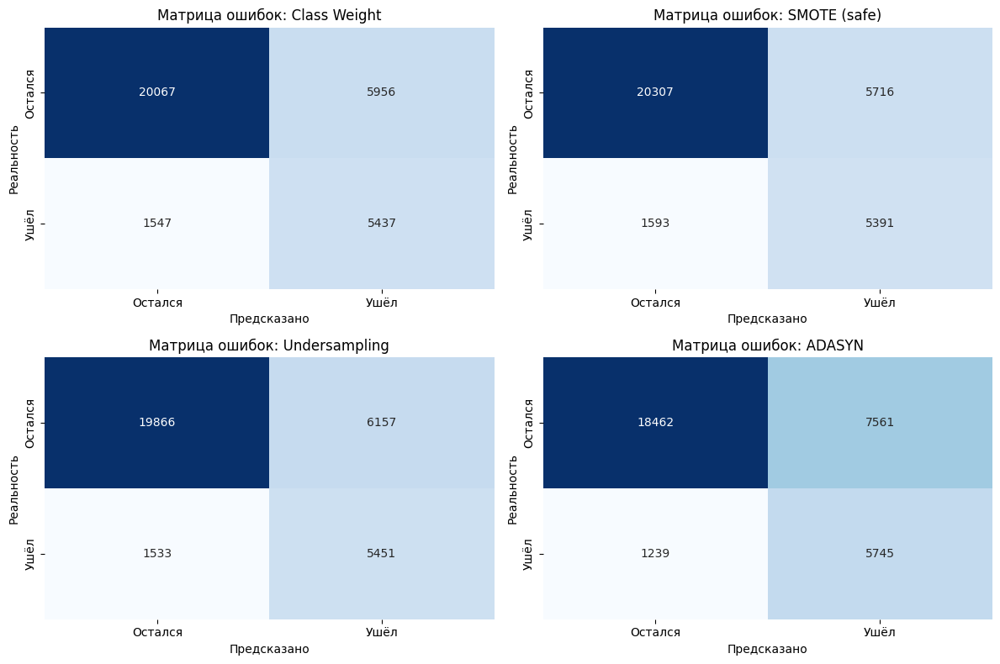


📊 АНАЛИЗ ПЕРЕОБУЧЕНИЯ (Train vs CV Recall):
           Model  Train Recall  CV Recall  Overfitting Gap
0   Class Weight        0.7839     0.7871          -0.0032
1   SMOTE (safe)        0.7778     0.7771           0.0007
2  Undersampling        0.7878     0.7912          -0.0034
3         ADASYN        0.8268     0.8261           0.0006


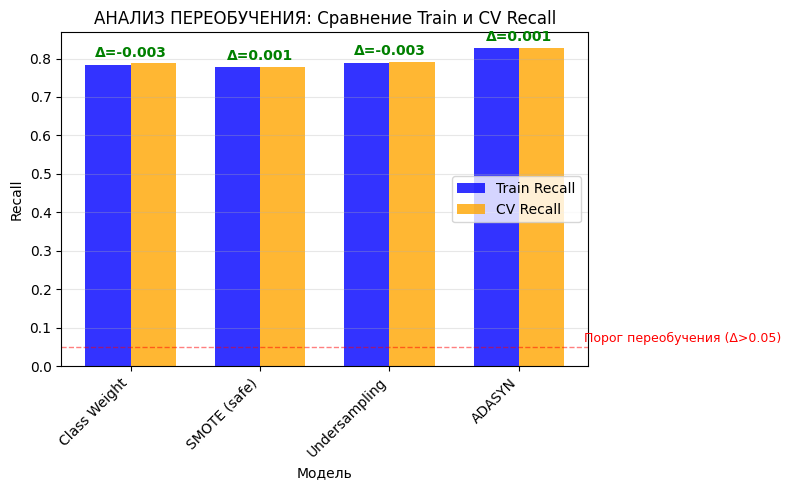


🔍 ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ АНАЛИЗА ПЕРЕОБУЧЕНИЯ:
--------------------------------------------------
✅  Class Weight: Стабильная модель (Δ=-0.0032)
   Хорошая обобщающая способность
✅  SMOTE (safe): Стабильная модель (Δ=0.0007)
   Хорошая обобщающая способность
✅  Undersampling: Стабильная модель (Δ=-0.0034)
   Хорошая обобщающая способность
✅  ADASYN: Стабильная модель (Δ=0.0006)
   Хорошая обобщающая способность



📊 ФИНАЛЬНОЕ СРАВНЕНИЕ МОДЕЛЕЙ НА ТЕСТОВЫХ ДАННЫХ
        Model  Test Recall  Test Precision  Test F1  Test ROC-AUC  Test AP  Overfitting Gap (Train-CV)
 Class Weight       0.7785          0.4772   0.5917        0.8509   0.6306                     -0.0032
 SMOTE (safe)       0.7719          0.4854   0.5960        0.8530   0.6391                      0.0007
Undersampling       0.7805          0.4696   0.5864        0.8482   0.6217                     -0.0034
       ADASYN       0.8226          0.4318   0.5663        0.8465   0.6261                      0.0006


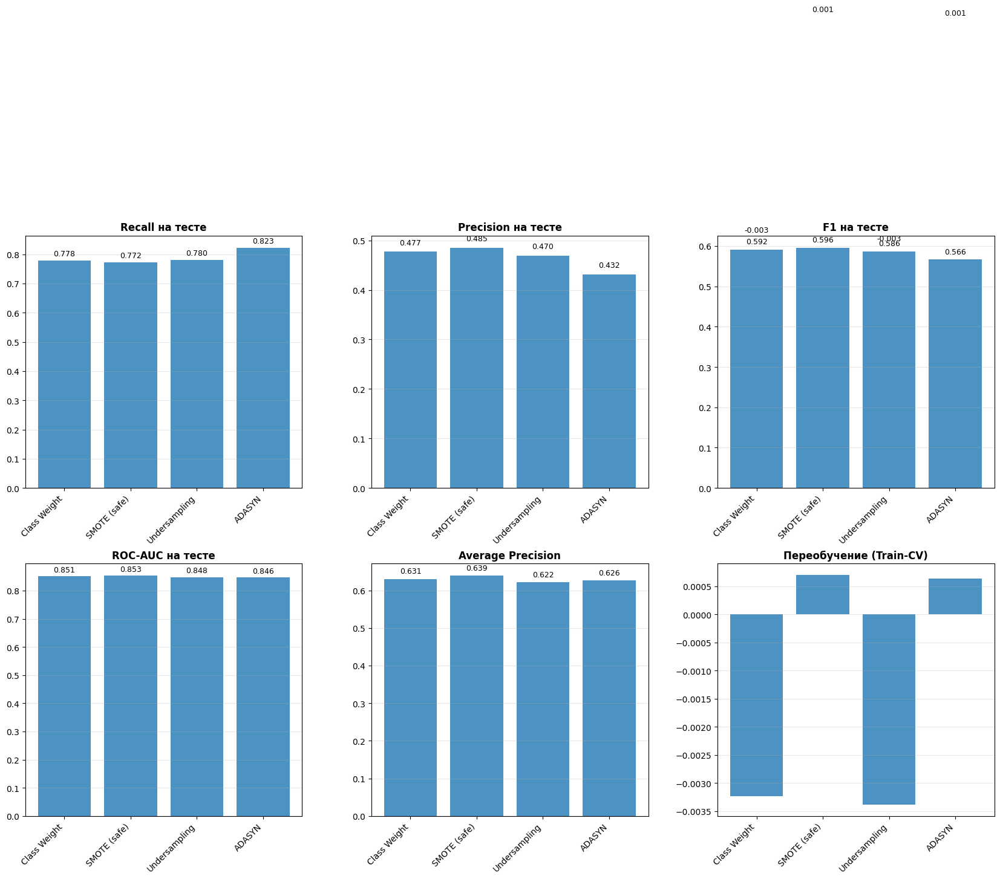

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

# -------------------------------------------------
# ПРОВЕРКА: существуют ли нужные переменные
# -------------------------------------------------

required_vars = ["searches", "X_train", "y_train", "X_test", "y_test"]

missing = [v for v in required_vars if v not in globals() and v not in locals()]
if missing:
    print(f"❌ Не хватает переменных: {missing}")
    print("Убедитесь, что все модели обучены и переменные доступны.")
    exit()

# -------------------------------------------------
# 1. ВИЗУАЛИЗАЦИЯ: матрицы ошибок (на тесте)
# -------------------------------------------------

model_names = ["Class Weight", "SMOTE (safe)", "Undersampling", "ADASYN"]
model_keys = ["class_weight", "smote", "under", "adasyn"]

# Получаем предсказания на тесте
y_pred_list = []
for key in model_keys:
    model = searches[key].best_estimator_
    y_pred = model.predict(X_test)
    y_pred_list.append(y_pred)

# Матрицы ошибок
cms = [confusion_matrix(y_test, yp) for yp in y_pred_list]

# Визуализация
n_models = len(cms)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, (cm, name) in enumerate(zip(cms, model_names, strict=False)):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i])
    axes[i].set_title(f"Матрица ошибок: {name}")
    axes[i].set_xlabel("Предсказано")
    axes[i].set_ylabel("Реальность")
    axes[i].set_xticklabels(["Остался", "Ушёл"])
    axes[i].set_yticklabels(["Остался", "Ушёл"])

plt.tight_layout()
plt.show()

# -------------------------------------------------
# 2. АНАЛИЗ ПЕРЕОБУЧЕНИЯ: Train vs CV recall
# -------------------------------------------------

# Собираем данные: recall на тренировочных данных и кросс-валидации
train_recalls = []
cv_recalls = []

for key in model_keys:
    model = searches[key].best_estimator_
    # Вычисляем recall на тренировочных данных (на всей выборке)
    y_train_pred = model.predict(X_train)
    train_recall = recall_score(y_train, y_train_pred)
    train_recalls.append(train_recall)

    # Берем лучший recall из кросс-валидации
    cv_recall = searches[key].best_score_
    cv_recalls.append(cv_recall)

# DataFrame для удобства
df_comparison = pd.DataFrame(
    {"Model": model_names, "Train Recall": train_recalls, "CV Recall": cv_recalls}
)

df_comparison["Overfitting Gap"] = df_comparison["Train Recall"] - df_comparison["CV Recall"]

print("\n📊 АНАЛИЗ ПЕРЕОБУЧЕНИЯ (Train vs CV Recall):")
print(df_comparison.round(4))

# -------------------------------------------------
# 3. ВИЗУАЛИЗАЦИЯ: переобучение (разница между Train и CV)
# -------------------------------------------------

fig, ax = plt.subplots(figsize=(max(8, len(model_names) * 0.8), 5))
x = np.arange(len(model_names))
width = 0.35

ax.bar(x - width / 2, train_recalls, width, label="Train Recall", alpha=0.8, color="blue")
ax.bar(x + width / 2, cv_recalls, width, label="CV Recall", alpha=0.8, color="orange")

ax.set_xlabel("Модель")
ax.set_ylabel("Recall")
ax.set_title("АНАЛИЗ ПЕРЕОБУЧЕНИЯ: Сравнение Train и CV Recall")
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=45, ha="right")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")

# Добавим разницу (overfitting gap)
for i in range(len(model_names)):
    gap = df_comparison.iloc[i]["Overfitting Gap"]
    y_pos = max(train_recalls[i], cv_recalls[i]) + 0.01
    ax.text(
        i,
        y_pos,
        f"Δ={gap:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="red" if gap > 0.05 else "green",
        fontweight="bold",
    )

# Добавим горизонтальную линию для порога переобучения
ax.axhline(y=0.05, color="red", linestyle="--", alpha=0.5, linewidth=1)
ax.text(
    len(model_names) - 0.5,
    0.055,
    "Порог переобучения (Δ>0.05)",
    color="red",
    fontsize=9,
    va="bottom",
)

plt.tight_layout()
plt.show()

# Интерпретация результатов
print("\n🔍 ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ АНАЛИЗА ПЕРЕОБУЧЕНИЯ:")
print("-" * 50)

for i, row in df_comparison.iterrows():
    gap = row["Overfitting Gap"]
    if gap > 0.05:
        print(f"⚠️  {row['Model']}: Признаки переобучения (Δ={gap:.4f})")
        print("   Модель работает значительно лучше на тренировочных данных")
    elif gap > 0.02:
        print(f"⚠️  {row['Model']}: Умеренный разрыв (Δ={gap:.4f})")
        print("   Небольшое переобучение, но в пределах нормы")
    else:
        print(f"✅  {row['Model']}: Стабильная модель (Δ={gap:.4f})")
        print("   Хорошая обобщающая способность")

# -------------------------------------------------
# 4. ВИЗУАЛИЗАЦИЯ: интерактивная Precision-Recall кривая (на тесте)
# -------------------------------------------------

y_proba_list = []
for key in model_keys:
    model = searches[key].best_estimator_
    y_proba = model.predict_proba(X_test)[:, 1]
    y_proba_list.append(y_proba)

fig = go.Figure()

for i, (name, y_proba) in enumerate(zip(model_names, y_proba_list, strict=False)):
    precision, recall, _ = precision_recall_curve(y_test, y_proba)

    fig.add_trace(
        go.Scatter(
            x=recall,
            y=precision,
            mode="lines",
            name=f"{name}<br>(AP = {average_precision_score(y_test, y_proba):.3f})",
            hovertemplate="<b>%{text}</b><br>Recall: %{x:.3f}<br>Precision: %{y:.3f}<extra></extra>",
            text=[name] * len(recall),
            line=dict(width=2),
        )
    )

fig.update_layout(
    title="Precision-Recall Trade-off Curve (на тестовых данных)",
    xaxis_title="Recall",
    yaxis_title="Precision",
    hovermode="x unified",
    width=800,
    height=600,
    legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01, bgcolor="rgba(255, 255, 255, 0.8)"),
)

# Добавим базовую линию (пропорция положительного класса)
baseline = len(y_test[y_test == 1]) / len(y_test)
fig.add_hline(
    y=baseline,
    line_dash="dash",
    line_color="gray",
    annotation_text=f"Baseline (Positive Ratio={baseline:.3f})",
)

fig.show()

# -------------------------------------------------
# 5. ДОПОЛНИТЕЛЬНО: Сравнение всех метрик на тесте (ИСПРАВЛЕННАЯ ВЕРСИЯ)
# -------------------------------------------------

print("\n" + "=" * 80)
print("📊 ФИНАЛЬНОЕ СРАВНЕНИЕ МОДЕЛЕЙ НА ТЕСТОВЫХ ДАННЫХ")
print("=" * 80)

metrics_data = []
for i, (name, y_pred, y_proba) in enumerate(
    zip(model_names, y_pred_list, y_proba_list, strict=False)
):
    metrics_data.append(
        {
            "Model": name,
            "Test Recall": recall_score(y_test, y_pred),
            "Test Precision": precision_score(y_test, y_pred),
            "Test F1": f1_score(y_test, y_pred),
            "Test ROC-AUC": roc_auc_score(y_test, y_proba),
            "Test AP": average_precision_score(y_test, y_proba),
            "Overfitting Gap (Train-CV)": df_comparison.iloc[i]["Overfitting Gap"],
        }
    )

metrics_df = pd.DataFrame(metrics_data)
print(metrics_df.round(4).to_string(index=False))

# Визуализация всех метрик (ИСПРАВЛЕННАЯ)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
metric_cols = [
    "Test Recall",
    "Test Precision",
    "Test F1",
    "Test ROC-AUC",
    "Test AP",
    "Overfitting Gap (Train-CV)",
]
titles = [
    "Recall на тесте",
    "Precision на тесте",
    "F1 на тесте",
    "ROC-AUC на тесте",
    "Average Precision",
    "Переобучение (Train-CV)",
]

for idx, (ax, metric, title) in enumerate(zip(axes.flat, metric_cols, titles, strict=False)):
    values = metrics_df[metric].values
    bars = ax.bar(model_names, values, alpha=0.8)
    ax.set_title(title, fontsize=12, fontweight="bold")

    # Ключевое исправление: сначала set_xticks, потом set_xticklabels
    ax.set_xticks(range(len(model_names)))
    ax.set_xticklabels(model_names, rotation=45, ha="right", fontsize=10)

    ax.grid(True, alpha=0.3, axis="y")

    # Добавляем значения на столбцы
    for bar, val in zip(bars, values, strict=False):
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            height + 0.01,
            f"{val:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

# Используем subplots_adjust вместо tight_layout для большего контроля
plt.subplots_adjust(
    left=0.08,  # Отступ слева
    right=0.97,  # Отступ справа
    bottom=0.15,  # Отступ снизу (место для повернутых меток)
    top=0.95,  # Отступ сверху
    wspace=0.25,  # Горизонтальный отступ между графиками
    hspace=0.3,  # Вертикальный отступ между графиками
)

plt.show()

Однако потом мы решили проверить: Может быть, производительность вырастет, если убрать добавленные признаки? Так и получилось. Далее представлено сравнение модели со списком самых продуктивнх признаков и препроцессором.

📊 Формат данных: X = (165034, 19), y = (165034,)

🔄 Вычисляем PhiK-матрицу (это может занять время)...
interval columns not set, guessing: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceToSalary', 'HighValueClient', 'ProductsPerYear', 'ActiveMultiProduct', 'HasMoney', 'Exited']

🎯 PhiK корреляция признаков с 'Exited' (по убыванию):
NumOfProducts           0.6074
Age                     0.5219
AgeGroup                0.4709
ActiveMultiProduct      0.3720
IsActiveMember          0.3242
ProductsPerYearGroup    0.2320
Gender                  0.2280
BalanceGroup            0.2112
HasMoney                0.2079
Balance                 0.1890
Geography               0.1278
ProductsPerYear         0.0918
CreditGroup             0.0576
Tenure                  0.0495
CreditScore             0.0487
HasCrCard               0.0345
EstimatedSalary         0.0341
HighValueClient         0.0239
BalanceToSalary         0.0000
Name:

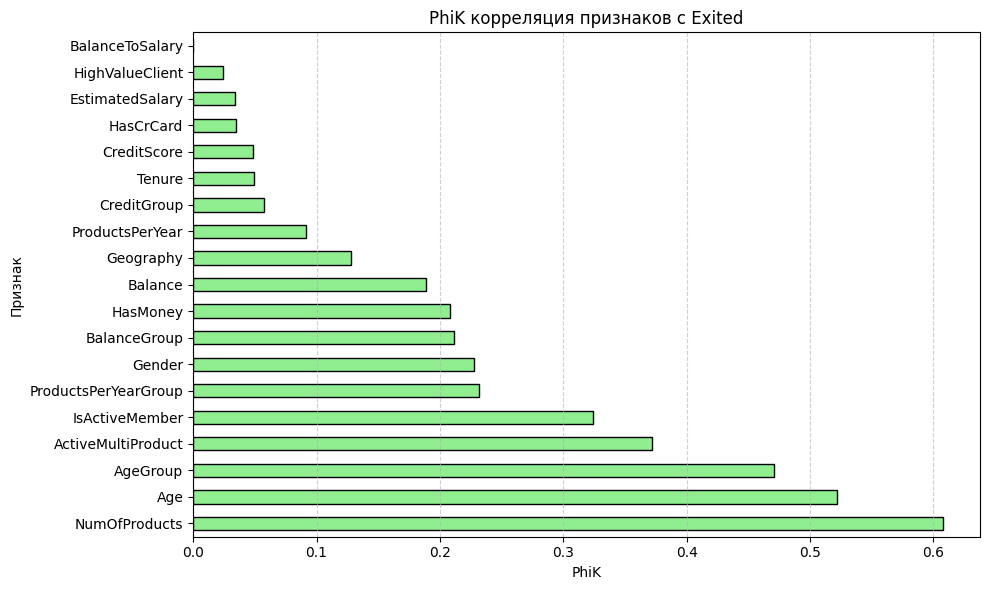


❌ Признаки с PhiK < 0.01 (мало влияют на Exited):
['BalanceToSalary']

⚠️  Сильно коррелирующие пары признаков (PhiK > 0.9):
  CreditScore ↔ CreditGroup: 0.928
  Age ↔ AgeGroup: 0.950
  Balance ↔ BalanceGroup: 0.998
  Balance ↔ HasMoney: 1.000
  BalanceGroup ↔ HasMoney: 1.000

💾 PhiK-корреляции сохранены: 'phik_correlations_with_Exited.csv', 'full_phik_correlation_matrix.csv'

📝 РЕКОМЕНДУЕМ УДАЛИТЬ ПРИЗНАКИ:
['AgeGroup', 'BalanceGroup', 'BalanceToSalary', 'CreditGroup', 'HasMoney']

✅ Оставляем 14 признаков из 19:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'HighValueClient', 'ProductsPerYear', 'ActiveMultiProduct', 'ProductsPerYearGroup']

📊 Новый X: (165034, 14)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from phik import report

# -------------------------------------------------
# 1. РАЗДЕЛЯЕМ df НА X и y
# -------------------------------------------------

if "Exited" not in df.columns:
    print("❌ В колонках нет 'Exited'. Убедитесь, что колонка есть.")
    exit()

X = df.drop(columns=["Exited"])
y = df["Exited"]

print(f"📊 Формат данных: X = {X.shape}, y = {y.shape}")

# -------------------------------------------------
# 2. РАСЧЁТ PhiK МАТРИЦЫ (включая Exited)
# -------------------------------------------------

# Объединяем X и y для анализа phik
df_analysis = X.copy()
df_analysis["Exited"] = y

print("\n🔄 Вычисляем PhiK-матрицу (это может занять время)...")
phik_matrix = df_analysis.phik_matrix()

# -------------------------------------------------
# 3. PhiK КОРРЕЛЯЦИЯ С Exited
# -------------------------------------------------

phik_with_target = phik_matrix["Exited"].drop("Exited").sort_values(ascending=False)

print("\n🎯 PhiK корреляция признаков с 'Exited' (по убыванию):")
print(phik_with_target.round(4))

# -------------------------------------------------
# 4. ВИЗУАЛИЗАЦИЯ: PhiK с Exited
# -------------------------------------------------

plt.figure(figsize=(10, 6))
phik_with_target.plot(kind="barh", color="lightgreen", edgecolor="black")
plt.title("PhiK корреляция признаков с Exited")
plt.xlabel("PhiK")
plt.ylabel("Признак")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# -------------------------------------------------
# 5. ОТБОР: слабо коррелирующие с Exited (например, < 0.01)
# -------------------------------------------------

low_corr_threshold = 0.01
low_corr_features = phik_with_target[phik_with_target.abs() < low_corr_threshold].index.tolist()

if low_corr_features:
    print(f"\n❌ Признаки с PhiK < {low_corr_threshold} (мало влияют на Exited):")
    print(low_corr_features)
else:
    print(f"\n✅ Нет признаков с PhiK < {low_corr_threshold}")

# -------------------------------------------------
# 6. ОТБОР: сильно коррелирующие между собой (до полиномов)
# -------------------------------------------------

# Убираем 'Exited' из матрицы, чтобы искать корреляции между признаками
phik_corr_matrix = phik_matrix.drop("Exited").drop("Exited", axis=1)

# Верхний треугольник матрицы (без диагонали)
upper_triangle = phik_corr_matrix.where(np.triu(np.ones_like(phik_corr_matrix, dtype=bool), k=1))

# Находим пары признаков с PhiK > 0.9
high_corr_pairs = []
for i in range(len(upper_triangle.columns)):
    for j in range(i + 1, len(upper_triangle.columns)):
        val = upper_triangle.iloc[i, j]
        if pd.notna(val) and val > 0.9:
            high_corr_pairs.append((upper_triangle.index[i], upper_triangle.columns[j], val))

if high_corr_pairs:
    print("\n⚠️  Сильно коррелирующие пары признаков (PhiK > 0.9):")
    for f1, f2, corr in high_corr_pairs:
        print(f"  {f1} ↔ {f2}: {corr:.3f}")
else:
    print("\n✅ Нет сильно коррелирующих пар (PhiK > 0.9)")

# -------------------------------------------------
# 7. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# -------------------------------------------------

# Сохраняем PhiK с Exited
phik_with_target.to_csv("phik_correlations_with_Exited.csv", header=True)

# Сохраняем полную матрицу
phik_matrix.to_csv("full_phik_correlation_matrix.csv")

print(
    "\n💾 PhiK-корреляции сохранены: 'phik_correlations_with_Exited.csv', 'full_phik_correlation_matrix.csv'"
)

# -------------------------------------------------
# 8. РЕКОМЕНДАЦИИ ПО ОТБОРУ ПРИЗНАКОВ
# -------------------------------------------------

recommended_drop = set()

# Добавляем слабые признаки
recommended_drop.update(low_corr_features)

# Добавляем один из пары сильно коррелирующих
for f1, f2, _ in high_corr_pairs:
    recommended_drop.add(f2)  # Убираем второй признак из пары

print("\n📝 РЕКОМЕНДУЕМ УДАЛИТЬ ПРИЗНАКИ:")
print(sorted(recommended_drop))

# -------------------------------------------------
# 9. СОЗДАНИЕ УЛУЧШЕННОГО X (без "плохих" признаков)
# -------------------------------------------------

features_to_keep = [col for col in X.columns if col not in recommended_drop]

print(f"\n✅ Оставляем {len(features_to_keep)} признаков из {len(X.columns)}:")
print(features_to_keep)

X_improved = X[features_to_keep]

print(f"\n📊 Новый X: {X_improved.shape}")

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

# -------------------------------------------------
# 1. ОПРЕДЕЛЯЕМ ОЧИЩЕННЫЕ ПРИЗНАКИ
# -------------------------------------------------
target = "Exited"
# Числовые признаки (для полиномов)
numeric_for_poly_clean = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary",
    "ProductsPerYear",
]

# Бинарные признаки
binary_clean = ["HasCrCard", "IsActiveMember", "HighValueClient", "ActiveMultiProduct"]

# Категориальные признаки
categorical_clean = ["Geography", "Gender", "ProductsPerYearGroup"]
# -------------------------------------------------
# 1.2. ПОДГОТОВКА ДАННЫХ
# -------------------------------------------------

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
# -------------------------------------------------
# 2. СОЗДАЁМ ТРАНСФОРМЕРЫ
# -------------------------------------------------

numeric_poly_pipeline = SklearnPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler_before", StandardScaler()),
        (
            "poly",
            PolynomialFeatures(
                degree=2,
                include_bias=False,
                interaction_only=False,  # ← ВКЛЮЧАЕМ ВЗАИМОДЕЙСТВИЯ + КВАДРАТЫ
            ),
        ),
        ("scaler_after", StandardScaler()),
    ]
)

binary_pipeline = SklearnPipeline(
    steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("scaler", StandardScaler())]
)

categorical_pipeline = SklearnPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")),
    ]
)

# -------------------------------------------------
# 3. СОБИРАЕМ ПРЕПРОЦЕССОР
# -------------------------------------------------

preprocessor_poly_clean = ColumnTransformer(
    transformers=[
        ("numeric_poly", numeric_poly_pipeline, numeric_for_poly_clean),
        ("binary", binary_pipeline, binary_clean),
        ("categorical", categorical_pipeline, categorical_clean),
    ],
    remainder="drop",
)

print("=" * 60)
print("✅ ПРЕПРОЦЕССОР preprocessor_poly_clean СОЗДАН")
print(f"• Числовые (с полиномами): {len(numeric_for_poly_clean)}")
print(f"• Бинарные: {len(binary_clean)}")
print(f"• Категориальные: {len(categorical_clean)}")
print("=" * 60)

✅ ПРЕПРОЦЕССОР preprocessor_poly_clean СОЗДАН
• Числовые (с полиномами): 7
• Бинарные: 4
• Категориальные: 3


In [ ]:
# -------------------------------------------------
# ИМПОРТЫ
# -------------------------------------------------
import joblib
import numpy as np
import pandas as pd
from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import loguniform
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

# Включаем HalvingSearch

# -------------------------------------------------
# 4. НАСТРОЙКИ
# -------------------------------------------------
print("\n⚡ НАСТРОЙКА ")
print("=" * 60)

n_candidates = 60
min_resources = 3000
cv_splits = 3
n_jobs = -1
factor = 2

# -------------------------------------------------
# 5. ПРОСТРАНСТВО ПАРАМЕТРОВ
# -------------------------------------------------

param_dist = [
    # Подмножество 1: l1 penalty (только liblinear и saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["l1"],
        "clf__solver": ["liblinear", "saga"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 2: l2 penalty (все солверы)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["l2"],
        "clf__solver": ["liblinear", "saga", "lbfgs"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 3: elasticnet penalty (только saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["elasticnet"],
        "clf__solver": ["saga"],
        "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 4: penalty=None (только lbfgs, saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": [None],
        "clf__solver": ["lbfgs", "saga"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
]

# ДОПОЛНИТЕЛЬНЫЕ ПАРАМЕТРЫ ДЛЯ МЕТОДОВ БАЛАНСИРОВКИ
smote_params = [
    {**p, "smote__k_neighbors": [2, 3, 5], "smote__sampling_strategy": [0.5, 0.7, 1.0]}
    for p in param_dist
]

adasyn_params = [
    {**p, "adasyn__n_neighbors": [2, 3, 5], "adasyn__sampling_strategy": [0.5, 0.7, 1.0]}
    for p in param_dist
]

under_params = [{**p, "under__sampling_strategy": [0.5, 0.7, 1.0]} for p in param_dist]
# -------------------------------------------------
# 6. ФУНКЦИЯ ЗАПУСКА ПОИСКА
# -------------------------------------------------


def run_halving_search(pipeline, params, X_train, y_train, model_name):
    print(f"\n🎯 ЗАПУСК {model_name}")
    search = HalvingRandomSearchCV(
        pipeline,
        param_distributions=params,
        n_candidates=n_candidates,
        factor=factor,
        cv=StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42),
        scoring="recall",
        n_jobs=n_jobs,
        random_state=42,
        verbose=1,
        min_resources=min_resources,
        aggressive_elimination=False,
    )
    start_time = time.time()
    search.fit(X_train, y_train)
    elapsed = time.time() - start_time
    print(f"✅ {model_name} завершена за {elapsed/60:.1f} минут")
    print(f"   Лучший recall (CV): {search.best_score_:.4f}")
    print(f"   Лучшие параметры: {search.best_params_}")
    return search


# -------------------------------------------------
# 7. СОЗДАНИЕ ПАЙПЛАЙНОВ
# -------------------------------------------------

print("\n" + "=" * 60)
print("🏗️  СОЗДАНИЕ 4 МОДЕЛЕЙ")
print("=" * 60)

poly_class_weight = SklearnPipeline(
    steps=[
        ("preprocessor", preprocessor_poly_clean),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

poly_smote = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor_poly_clean),
        ("smote", SMOTE(random_state=42, k_neighbors=2)),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

poly_under = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor_poly_clean),
        ("under", RandomUnderSampler(random_state=42, sampling_strategy=1.0)),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

poly_adasyn = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor_poly_clean),
        ("adasyn", ADASYN(random_state=42, n_neighbors=2)),
        ("clf", LogisticRegression(random_state=42, max_iter=2000)),
    ]
)

# -------------------------------------------------
# 8. ЗАПУСК ПОИСКА
# -------------------------------------------------

searches = {}
print("\n" + "=" * 60)
print("🚀 ЗАПУСК HALVING SEARCH")
print("=" * 60)

searches["class_weight"] = run_halving_search(
    poly_class_weight, param_dist, X_train, y_train, "Polynomial + Class Weight"
)
searches["smote"] = run_halving_search(
    poly_smote, smote_params, X_train, y_train, "Polynomial + SMOTE"
)
searches["under"] = run_halving_search(
    poly_under, under_params, X_train, y_train, "Polynomial + Undersampling"
)
searches["adasyn"] = run_halving_search(
    poly_adasyn, adasyn_params, X_train, y_train, "Polynomial + ADASYN"
)

# -------------------------------------------------
# 9. СРАВНЕНИЕ РЕЗУЛЬТАТОВ
# -------------------------------------------------

results = []
for name, search in searches.items():
    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_proba = best_model.predict_proba(X_test)[:, 1]
    results.append(
        {
            "Model": name.replace("_", " ").title(),
            "CV_Recall": search.best_score_,
            "Test_Recall": recall_score(y_test, y_pred),
            "Test_Precision": precision_score(y_test, y_pred),
            "Test_F1": f1_score(y_test, y_pred),
            "Test_ROC_AUC": roc_auc_score(y_test, y_proba),
            "Test_PR_AUC": average_precision_score(y_test, y_proba),
        }
    )

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Test_Recall", ascending=False)
print("\n📊 РЕЗУЛЬТАТЫ НА ТЕСТЕ:")
print(results_df.round(4).to_string(index=False))

# -------------------------------------------------
# 10. ЛУЧШАЯ МОДЕЛЬ
# -------------------------------------------------

best_row = results_df.iloc[0]
best_model_name = best_row["Model"]
best_search_name = best_model_name.lower().replace(" ", "_")
best_search = searches[best_search_name]
best_model = best_search.best_estimator_

print(f"\n🏆 ЛУЧШАЯ МОДЕЛЬ: {best_model_name}")
print(f"🎯 Test Recall: {best_row['Test_Recall']:.4f}")

# -------------------------------------------------
# 11. СОХРАНЕНИЕ
# -------------------------------------------------

joblib.dump(best_model, f"best_polynomial_{best_search_name}.pkl")
print(f"\n💾 Лучшая модель сохранена: best_polynomial_{best_search_name}.pkl")

results_df.to_csv("halving_search_results.csv", index=False)
joblib.dump(searches, "halving_searches.pkl")
print("🔍 Результаты и объекты сохранены.")


⚡ НАСТРОЙКА 

🏗️  СОЗДАНИЕ 4 МОДЕЛЕЙ

🚀 ЗАПУСК HALVING SEARCH

🎯 ЗАПУСК Polynomial + Class Weight
n_iterations: 6
n_required_iterations: 6
n_possible_iterations: 6
min_resources_: 3000
max_resources_: 132027
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 60
n_resources: 3000
Fitting 3 folds for each of 60 candidates, totalling 180 fits
----------
iter: 1
n_candidates: 30
n_resources: 6000
Fitting 3 folds for each of 30 candidates, totalling 90 fits
----------
iter: 2
n_candidates: 15
n_resources: 12000
Fitting 3 folds for each of 15 candidates, totalling 45 fits
----------
iter: 3
n_candidates: 8
n_resources: 24000
Fitting 3 folds for each of 8 candidates, totalling 24 fits
----------
iter: 4
n_candidates: 4
n_resources: 48000
Fitting 3 folds for each of 4 candidates, totalling 12 fits
----------
iter: 5
n_candidates: 2
n_resources: 96000
Fitting 3 folds for each of 2 candidates, totalling 6 fits
✅ Polynomial + Class Weight завершена за 12.0 минут
   Лучший r

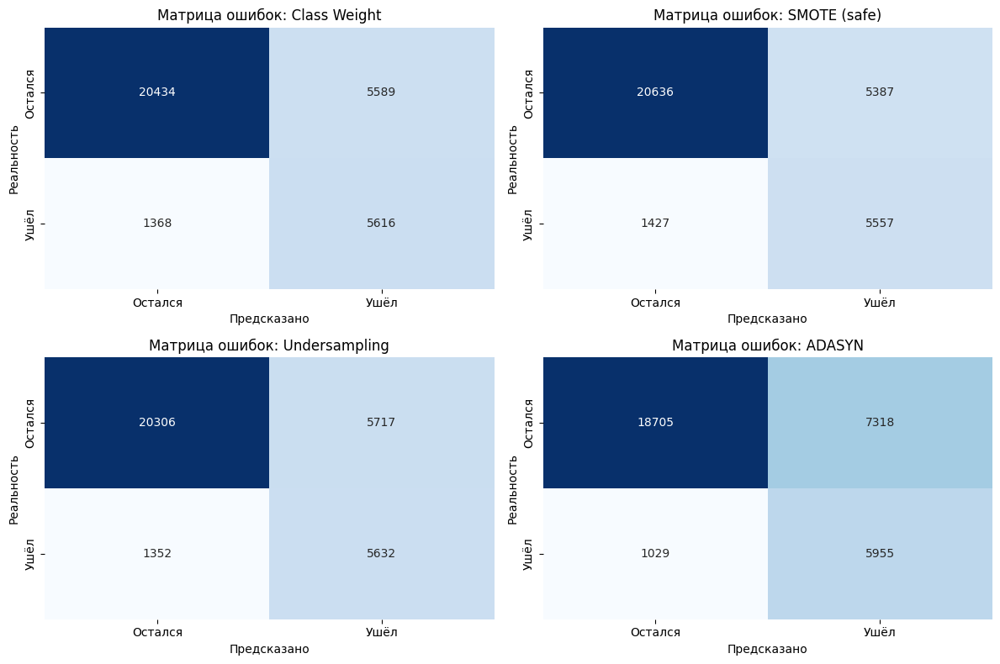


📊 АНАЛИЗ ПЕРЕОБУЧЕНИЯ (Train vs CV Recall):
           Model  Train Recall  CV Recall  Overfitting Gap
0   Class Weight        0.8075     0.8095          -0.0021
1   SMOTE (safe)        0.7996     0.8015          -0.0019
2  Undersampling        0.8102     0.8133          -0.0031
3         ADASYN        0.8581     0.8561           0.0020


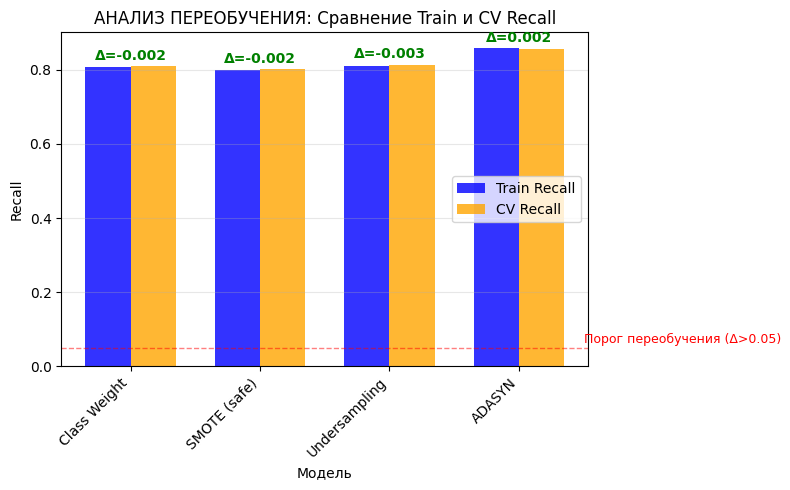


🔍 ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ АНАЛИЗА ПЕРЕОБУЧЕНИЯ:
--------------------------------------------------
✅  Class Weight: Стабильная модель (Δ=-0.0021)
   Хорошая обобщающая способность
✅  SMOTE (safe): Стабильная модель (Δ=-0.0019)
   Хорошая обобщающая способность
✅  Undersampling: Стабильная модель (Δ=-0.0031)
   Хорошая обобщающая способность
✅  ADASYN: Стабильная модель (Δ=0.0020)
   Хорошая обобщающая способность


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

# -------------------------------------------------
# ПРОВЕРКА: существуют ли нужные переменные
# -------------------------------------------------

# ДОБАВЛЕНО: X_train и y_train для анализа переобучения
required_vars = ["searches", "X_train", "y_train", "X_test", "y_test"]

missing = [v for v in required_vars if v not in globals() and v not in locals()]
if missing:
    print(f"❌ Не хватает переменных: {missing}")
    print("Убедитесь, что все модели обучены и переменные доступны.")
    exit()

# -------------------------------------------------
# 1. ВИЗУАЛИЗАЦИЯ: матрицы ошибок (на тесте)
# -------------------------------------------------

model_names = ["Class Weight", "SMOTE (safe)", "Undersampling", "ADASYN"]
model_keys = ["class_weight", "smote", "under", "adasyn"]

# Получаем предсказания на тесте
y_pred_list = []
for key in model_keys:
    model = searches[key].best_estimator_
    y_pred = model.predict(X_test)
    y_pred_list.append(y_pred)

# Матрицы ошибок
cms = [confusion_matrix(y_test, yp) for yp in y_pred_list]

# Визуализация
n_models = len(cms)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, (cm, name) in enumerate(zip(cms, model_names, strict=False)):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i])
    axes[i].set_title(f"Матрица ошибок: {name}")
    axes[i].set_xlabel("Предсказано")
    axes[i].set_ylabel("Реальность")
    axes[i].set_xticklabels(["Остался", "Ушёл"])
    axes[i].set_yticklabels(["Остался", "Ушёл"])

plt.tight_layout()
plt.show()

# -------------------------------------------------
# 2. АНАЛИЗ ПЕРЕОБУЧЕНИЯ: Train vs CV recall
# -------------------------------------------------

# Собираем данные: recall на тренировочных данных и кросс-валидации
train_recalls = []
cv_recalls = []

for key in model_keys:
    model = searches[key].best_estimator_
    # Вычисляем recall на тренировочных данных (на всей выборке)
    y_train_pred = model.predict(X_train)
    train_recall = recall_score(y_train, y_train_pred)
    train_recalls.append(train_recall)

    # Берем лучший recall из кросс-валидации
    cv_recall = searches[key].best_score_
    cv_recalls.append(cv_recall)

# DataFrame для удобства
df_comparison = pd.DataFrame(
    {"Model": model_names, "Train Recall": train_recalls, "CV Recall": cv_recalls}
)

df_comparison["Overfitting Gap"] = df_comparison["Train Recall"] - df_comparison["CV Recall"]

print("\n📊 АНАЛИЗ ПЕРЕОБУЧЕНИЯ (Train vs CV Recall):")
print(df_comparison.round(4))

# -------------------------------------------------
# 3. ВИЗУАЛИЗАЦИЯ: переобучение (разница между Train и CV)
# -------------------------------------------------

fig, ax = plt.subplots(figsize=(max(8, len(model_names) * 0.8), 5))
x = np.arange(len(model_names))
width = 0.35

ax.bar(x - width / 2, train_recalls, width, label="Train Recall", alpha=0.8, color="blue")
ax.bar(x + width / 2, cv_recalls, width, label="CV Recall", alpha=0.8, color="orange")

ax.set_xlabel("Модель")
ax.set_ylabel("Recall")
ax.set_title("АНАЛИЗ ПЕРЕОБУЧЕНИЯ: Сравнение Train и CV Recall")
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=45, ha="right")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")

# Добавим разницу (overfitting gap)
for i in range(len(model_names)):
    gap = df_comparison.iloc[i]["Overfitting Gap"]
    y_pos = max(train_recalls[i], cv_recalls[i]) + 0.01
    ax.text(
        i,
        y_pos,
        f"Δ={gap:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="red" if gap > 0.05 else "green",
        fontweight="bold",
    )

# Добавим горизонтальную линию для порога переобучения
ax.axhline(y=0.05, color="red", linestyle="--", alpha=0.5, linewidth=1)
ax.text(
    len(model_names) - 0.5,
    0.055,
    "Порог переобучения (Δ>0.05)",
    color="red",
    fontsize=9,
    va="bottom",
)

plt.tight_layout()
plt.show()

# Интерпретация результатов
print("\n🔍 ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ АНАЛИЗА ПЕРЕОБУЧЕНИЯ:")
print("-" * 50)

for i, row in df_comparison.iterrows():
    gap = row["Overfitting Gap"]
    if gap > 0.05:
        print(f"⚠️  {row['Model']}: Признаки переобучения (Δ={gap:.4f})")
        print("   Модель работает значительно лучше на тренировочных данных")
    elif gap > 0.02:
        print(f"⚠️  {row['Model']}: Умеренный разрыв (Δ={gap:.4f})")
        print("   Небольшое переобучение, но в пределах нормы")
    else:
        print(f"✅  {row['Model']}: Стабильная модель (Δ={gap:.4f})")
        print("   Хорошая обобщающая способность")

# -------------------------------------------------
# 4. ВИЗУАЛИЗАЦИЯ: интерактивная Precision-Recall кривая (на тесте)
# -------------------------------------------------

y_proba_list = []
for key in model_keys:
    model = searches[key].best_estimator_
    y_proba = model.predict_proba(X_test)[:, 1]
    y_proba_list.append(y_proba)

fig = go.Figure()

for i, (name, y_proba) in enumerate(zip(model_names, y_proba_list, strict=False)):
    precision, recall, _ = precision_recall_curve(y_test, y_proba)

    fig.add_trace(
        go.Scatter(
            x=recall,
            y=precision,
            mode="lines",
            name=f"{name}<br>(AP = {average_precision_score(y_test, y_proba):.3f})",
            hovertemplate="<b>%{text}</b><br>Recall: %{x:.3f}<br>Precision: %{y:.3f}<extra></extra>",
            text=[name] * len(recall),
            line=dict(width=2),
        )
    )

fig.update_layout(
    title="Precision-Recall Trade-off Curve (на тестовых данных)",
    xaxis_title="Recall",
    yaxis_title="Precision",
    hovermode="x unified",
    width=800,
    height=600,
    legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01, bgcolor="rgba(255, 255, 255, 0.8)"),
)

# Добавим базовую линию (пропорция положительного класса)
baseline = len(y_test[y_test == 1]) / len(y_test)
fig.add_hline(
    y=baseline,
    line_dash="dash",
    line_color="gray",
    annotation_text=f"Baseline (Positive Ratio={baseline:.3f})",
)

fig.show()

In [ ]:
# -------------------------------------------------
# УЛУЧШЕННОЕ ПРОСТРАНСТВО ПАРАМЕТРОВ ТОЛЬКО ДЛЯ ADASYN
# -------------------------------------------------

adasyn_improved_params = [
    # Подмножество 1: l1 penalty (только liblinear и saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["l1"],
        "clf__solver": ["liblinear", "saga"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 2: l2 penalty (все солверы)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["l2"],
        "clf__solver": ["liblinear", "saga", "lbfgs"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 3: elasticnet penalty (только saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": ["elasticnet"],
        "clf__solver": ["saga"],
        "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
    # Подмножество 4: penalty=None (только lbfgs, saga)
    {
        "clf__C": loguniform(0.001, 10),
        "clf__penalty": [None],
        "clf__solver": ["lbfgs", "saga"],
        "clf__class_weight": [None, "balanced"],
        "clf__max_iter": [2000],
    },
]

# ДОПОЛНИТЕЛЬНЫЕ ПАРАМЕТРЫ ДЛЯ ADASYN
adasyn_improved_params = [
    {**p, "adasyn__n_neighbors": [2, 3, 5], "adasyn__sampling_strategy": [0.5, 0.7, 0.8, 1.0]}
    for p in adasyn_improved_params
]

# -------------------------------------------------
# ПОВТОРНОЕ ОБУЧЕНИЕ ТОЛЬКО ADASYN С УЛУЧШЕННЫМИ ПАРАМЕТРАМИ
# -------------------------------------------------

search_adasyn_improved = HalvingRandomSearchCV(
    poly_adasyn,
    param_distributions=adasyn_improved_params,
    n_candidates=100,
    factor=2,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="recall",
    n_jobs=-1,
    random_state=42,
    verbose=1,
    min_resources=3000,
    aggressive_elimination=False,
)

start_time = time.time()  # ← ДОБАВЛЕНО: запись времени начала
search_adasyn_improved.fit(X_train, y_train)

print(f"✅ УЛУЧШЕННЫЙ ADASYN завершён за {(time.time() - start_time)/60:.1f} минут")
print(f"🎯 Лучший recall (CV): {search_adasyn_improved.best_score_:.4f}")
print(f"📋 Лучшие параметры: {search_adasyn_improved.best_params_}")

# -------------------------------------------------
# ПРОВЕРКА НА ТЕСТЕ
# -------------------------------------------------

best_adasyn_improved = search_adasyn_improved.best_estimator_
y_pred_ad_improved = best_adasyn_improved.predict(X_test)
y_proba_ad_improved = best_adasyn_improved.predict_proba(X_test)[:, 1]

test_recall_improved = recall_score(y_test, y_pred_ad_improved)
test_precision_improved = precision_score(y_test, y_pred_ad_improved)
test_f1_improved = f1_score(y_test, y_pred_ad_improved)
test_roc_auc_improved = roc_auc_score(y_test, y_proba_ad_improved)

print("\n📊 РЕЗУЛЬТАТЫ УЛУЧШЕННОГО ADASYN НА ТЕСТЕ:")
print(f"Recall: {test_recall_improved:.4f}")
print(f"Precision: {test_precision_improved:.4f}")
print(f"F1: {test_f1_improved:.4f}")
print(f"ROC-AUC: {test_roc_auc_improved:.4f}")

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred_ad_improved)
tn, fp, fn, tp = cm.ravel()
print("\n📈 МАТРИЦА ОШИБОК:")
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

# -------------------------------------------------
# СОХРАНЕНИЕ УЛУЧШЕННОЙ МОДЕЛИ
# -------------------------------------------------

joblib.dump(best_adasyn_improved, "best_adasyn_improved.pkl")
print("\n💾 УЛУЧШЕННАЯ МОДЕЛЬ СОХРАНЕНА: best_adasyn_improved.pkl")

n_iterations: 6
n_required_iterations: 7
n_possible_iterations: 6
min_resources_: 3000
max_resources_: 132027
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 100
n_resources: 3000
Fitting 3 folds for each of 100 candidates, totalling 300 fits
----------
iter: 1
n_candidates: 50
n_resources: 6000
Fitting 3 folds for each of 50 candidates, totalling 150 fits
----------
iter: 2
n_candidates: 25
n_resources: 12000
Fitting 3 folds for each of 25 candidates, totalling 75 fits
----------
iter: 3
n_candidates: 13
n_resources: 24000
Fitting 3 folds for each of 13 candidates, totalling 39 fits
----------
iter: 4
n_candidates: 7
n_resources: 48000
Fitting 3 folds for each of 7 candidates, totalling 21 fits
----------
iter: 5
n_candidates: 4
n_resources: 96000
Fitting 3 folds for each of 4 candidates, totalling 12 fits
✅ УЛУЧШЕННЫЙ ADASYN завершён за 44.1 минут
🎯 Лучший recall (CV): 0.8561
📋 Лучшие параметры: {'adasyn__n_neighbors': 2, 'adasyn__sampling_strategy': 1.0, 'cl

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

# -------------------------------------------------
# 1. МАТРИЦА ОШИБОК (интерактивная)
# -------------------------------------------------

# Получаем предсказания на тесте
y_pred_ad_improved = search_adasyn_improved.best_estimator_.predict(X_test)
y_proba_ad_improved = search_adasyn_improved.best_estimator_.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_ad_improved)
tn, fp, fn, tp = cm.ravel()

# Создаём DataFrame для визуализации
cm_df = pd.DataFrame(
    cm, index=["Остался (Real)", "Ушёл (Real)"], columns=["Остался (Pred)", "Ушёл (Pred)"]
)

fig = px.imshow(
    cm_df,
    text_auto=True,
    color_continuous_scale="Blues",
    title="Матрица ошибок: ADASYN + Polynomial (на тесте)",
    aspect="equal",
)

fig.update_layout(xaxis_title="Предсказано", yaxis_title="Реальность")

fig.show()

# -------------------------------------------------
# 2. ИНТЕРАКТИВНАЯ PRECISION-RECALL КРИВАЯ
# -------------------------------------------------

precision, recall, _ = precision_recall_curve(y_test, y_proba_ad_improved)
avg_prec = average_precision_score(y_test, y_proba_ad_improved)

fig_pr = go.Figure()
fig_pr.add_trace(
    go.Scatter(
        x=recall,
        y=precision,
        mode="lines",
        name=f"PR Curve (AUC = {avg_prec:.3f})",
        line=dict(width=2),
    )
)

fig_pr.update_layout(
    title="Precision-Recall Curve (ADASYN + Polynomial)",
    xaxis_title="Recall",
    yaxis_title="Precision",
    hovermode="x unified",
)

fig_pr.show()

# -------------------------------------------------
# 3. АНАЛИЗ ПЕРЕОБУЧЕНИЯ (Train vs CV recall) - ИЗМЕНЕНО
# -------------------------------------------------

# Получаем предсказания на тренировочных данных
best_model = search_adasyn_improved.best_estimator_
y_train_pred = best_model.predict(X_train)
train_recall_ad = recall_score(y_train, y_train_pred)

# Получаем CV recall (кросс-валидация)
cv_recall_ad = search_adasyn_improved.best_score_

# Вычисляем разрыв (gap) - показатель переобучения
overfitting_gap = train_recall_ad - cv_recall_ad

# Рассчитываем также другие метрики для полного анализа
train_precision_ad = precision_score(y_train, y_train_pred)
train_f1_ad = f1_score(y_train, y_train_pred)

print("\n📊 АНАЛИЗ ПЕРЕОБУЧЕНИЯ (ADASYN):")
print(f"{'Метрика':<20} {'Тренировка':<12} {'CV':<12} {'Разница':<12}")
print("-" * 56)
print(f"{'Recall':<20} {train_recall_ad:<12.4f} {cv_recall_ad:<12.4f} {overfitting_gap:<12.4f}")
print(f"{'Precision':<20} {train_precision_ad:<12.4f} {'N/A':<12} {'N/A':<12}")
print(f"{'F1-Score':<20} {train_f1_ad:<12.4f} {'N/A':<12} {'N/A':<12}")

print("\n🔍 ИНТЕРПРЕТАЦИЯ:")
if overfitting_gap > 0.05:
    print(f"⚠️  ЯВНОЕ ПЕРЕОБУЧЕНИЕ: Δ={overfitting_gap:.4f} > 0.05")
    print("   Модель показывает значительно лучшие результаты на тренировочных данных.")
elif overfitting_gap > 0.02:
    print(f"⚠️  УМЕРЕННОЕ ПЕРЕОБУЧЕНИЕ: Δ={overfitting_gap:.4f} > 0.02")
    print("   Небольшой разрыв, но требует внимания.")
elif abs(overfitting_gap) <= 0.02:
    print(f"✅  СТАБИЛЬНАЯ МОДЕЛЬ: |Δ|={abs(overfitting_gap):.4f} ≤ 0.02")
    print("   Хорошая обобщающая способность.")
elif overfitting_gap < -0.02:
    print(f"⚠️  НЕДООБУЧЕНИЕ: Δ={overfitting_gap:.4f} < -0.02")
    print("   Модель лучше работает на CV, чем на тренировочных данных.")

# -------------------------------------------------
# 4. ВИЗУАЛИЗАЦИЯ: Train vs CV recall (обновлено)
# -------------------------------------------------

fig_gap = go.Figure()

# Добавляем столбцы для Train и CV Recall
fig_gap.add_trace(
    go.Bar(
        x=["Train Recall", "CV Recall"],
        y=[train_recall_ad, cv_recall_ad],
        name="ADASYN Recall",
        marker_color=["blue", "orange"],
        text=[f"{train_recall_ad:.4f}", f"{cv_recall_ad:.4f}"],
        textposition="auto",
    )
)

# Добавляем аннотацию с разницей
fig_gap.add_annotation(
    x=0.5,
    y=max(train_recall_ad, cv_recall_ad) + 0.05,
    text=f"Разрыв (Train-CV): {overfitting_gap:.4f}",
    showarrow=False,
    font=dict(size=12, color="red" if abs(overfitting_gap) > 0.02 else "green"),
)

fig_gap.update_layout(
    title="Анализ переобучения: Сравнение Train и CV Recall",
    xaxis_title="Тип выборки",
    yaxis_title="Recall",
    showlegend=False,
    yaxis_range=[0, 1],
    annotations=[
        dict(
            x=0,
            y=-0.15,
            xref="paper",
            yref="paper",
            text="💡 Интерпретация: Разница > 0.05 указывает на переобучение",
            showarrow=False,
            font=dict(size=10, color="gray"),
        )
    ],
)

fig_gap.show()

# -------------------------------------------------
# 5. ДОПОЛНИТЕЛЬНЫЙ АНАЛИЗ: Precision-Recall на тренировочных данных
# -------------------------------------------------

# Получаем вероятности на тренировочных данных
y_proba_train = best_model.predict_proba(X_train)[:, 1]
train_precision_vals, train_recall_vals, _ = precision_recall_curve(y_train, y_proba_train)
train_avg_prec = average_precision_score(y_train, y_proba_train)

# Сравниваем с тестовыми данными
print("\n📊 СРАВНЕНИЕ PR-AUC НА РАЗНЫХ ВЫБОРКАХ:")
print(f"{'Выборка':<15} {'PR-AUC':<10} {'Recall':<10} {'Precision':<10}")
print("-" * 45)
print(f"{'Train':<15} {train_avg_prec:<10.4f} {train_recall_ad:<10.4f} {train_precision_ad:<10.4f}")
print(
    f"{'Test':<15} {avg_prec:<10.4f} {recall_score(y_test, y_pred_ad_improved):<10.4f} {precision_score(y_test, y_pred_ad_improved):<10.4f}"
)

# -------------------------------------------------
# 6. ВИЗУАЛИЗАЦИЯ: Train vs Test PR-кривые
# -------------------------------------------------

fig_compare_pr = go.Figure()

# PR-кривая на тренировочных данных
fig_compare_pr.add_trace(
    go.Scatter(
        x=train_recall_vals,
        y=train_precision_vals,
        mode="lines",
        name=f"Train PR (AUC = {train_avg_prec:.3f})",
        line=dict(width=2, color="blue"),
        hovertemplate="Train<br>Recall: %{x:.3f}<br>Precision: %{y:.3f}<extra></extra>",
    )
)

# PR-кривая на тестовых данных
fig_compare_pr.add_trace(
    go.Scatter(
        x=recall,
        y=precision,
        mode="lines",
        name=f"Test PR (AUC = {avg_prec:.3f})",
        line=dict(width=2, color="red", dash="dash"),
        hovertemplate="Test<br>Recall: %{x:.3f}<br>Precision: %{y:.3f}<extra></extra>",
    )
)

fig_compare_pr.update_layout(
    title="Сравнение PR-кривых на Train и Test выборках",
    xaxis_title="Recall",
    yaxis_title="Precision",
    hovermode="x unified",
    width=800,
    height=500,
)

fig_compare_pr.show()

# -------------------------------------------------
# 7. СОХРАНЕНИЕ УЛУЧШЕННОЙ МОДЕЛИ С МЕТАДАННЫМИ
# -------------------------------------------------

from datetime import datetime

import joblib

# Создаем объект с моделью и метаданными
model_with_metadata = {
    "model": search_adasyn_improved.best_estimator_,
    "metadata": {
        "best_params": search_adasyn_improved.best_params_,
        "cv_recall": cv_recall_ad,
        "train_recall": train_recall_ad,
        "overfitting_gap": overfitting_gap,
        "test_recall": recall_score(y_test, y_pred_ad_improved),
        "test_precision": precision_score(y_test, y_pred_ad_improved),
        "test_f1": f1_score(y_test, y_pred_ad_improved),
        "training_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "analysis": "Стабильная модель"
        if abs(overfitting_gap) <= 0.02
        else "Переобучение"
        if overfitting_gap > 0.02
        else "Недообучение",
    },
}

# Сохраняем модель с метаданными
joblib.dump(model_with_metadata, "best_adasyn_improved_with_analysis.pkl")

# Также сохраняем отдельно модель для совместимости
joblib.dump(search_adasyn_improved.best_estimator_, "best_adasyn_improved.pkl")

print("\n💾 МОДЕЛЬ СОХРАНЕНА:")
print("   • best_adasyn_improved_with_analysis.pkl (с метаданными)")
print("   • best_adasyn_improved.pkl (только модель)")
print("\n📊 ИТОГОВЫЕ МЕТРИКИ НА ТЕСТЕ:")
print(f"   Recall: {recall_score(y_test, y_pred_ad_improved):.4f}")
print(f"   Precision: {precision_score(y_test, y_pred_ad_improved):.4f}")
print(f"   F1-Score: {f1_score(y_test, y_pred_ad_improved):.4f}")


📊 АНАЛИЗ ПЕРЕОБУЧЕНИЯ (ADASYN):
Метрика              Тренировка   CV           Разница     
--------------------------------------------------------
Recall               0.8571       0.8561       0.0010      
Precision            0.4504       N/A          N/A         
F1-Score             0.5905       N/A          N/A         

🔍 ИНТЕРПРЕТАЦИЯ:
✅  СТАБИЛЬНАЯ МОДЕЛЬ: |Δ|=0.0010 ≤ 0.02
   Хорошая обобщающая способность.



📊 СРАВНЕНИЕ PR-AUC НА РАЗНЫХ ВЫБОРКАХ:
Выборка         PR-AUC     Recall     Precision 
---------------------------------------------
Train           0.6971     0.8571     0.4504    
Test            0.6968     0.8527     0.4497    



💾 МОДЕЛЬ СОХРАНЕНА:
   • best_adasyn_improved_with_analysis.pkl (с метаданными)
   • best_adasyn_improved.pkl (только модель)

📊 ИТОГОВЫЕ МЕТРИКИ НА ТЕСТЕ:
   Recall: 0.8527
   Precision: 0.4497
   F1-Score: 0.5888


# Decision Tree

🚀 Запуск Decision Tree (Strict Train/CV Only)



Общий прогресс:   0%|          | 0/3 [00:00<?, ?model/s]


⚙️ АНАЛИЗ МЕТОДА: DT_Baseline
n_iterations: 5
n_required_iterations: 6
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 500
n_resources: 1620
Fitting 3 folds for each of 500 candidates, totalling 1500 fits
----------
iter: 1
n_candidates: 167
n_resources: 4860
Fitting 3 folds for each of 167 candidates, totalling 501 fits
----------
iter: 2
n_candidates: 56
n_resources: 14580
Fitting 3 folds for each of 56 candidates, totalling 168 fits
----------
iter: 3
n_candidates: 19
n_resources: 43740
Fitting 3 folds for each of 19 candidates, totalling 57 fits
----------
iter: 4
n_candidates: 7
n_resources: 131220
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Лучшие параметры: {'clf__ccp_alpha': np.float64(0.006291931136188218), 'clf__class_weight': 'balanced', 'clf__max_depth': 28, 'clf__min_samples_leaf': 50, 'clf__min_samples_split': 190}
⏱️ Время обучения: 4 мин 37 сек
🔄 Генерация CV

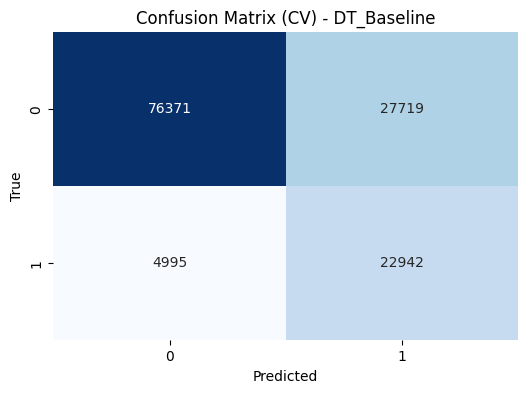

/tmp/ipython-input-2003262232.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


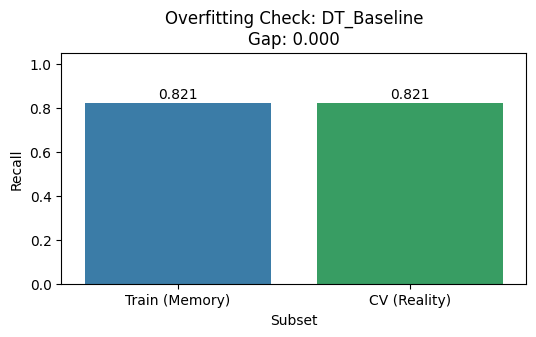

📈 Статичный график метрик (CV Data):


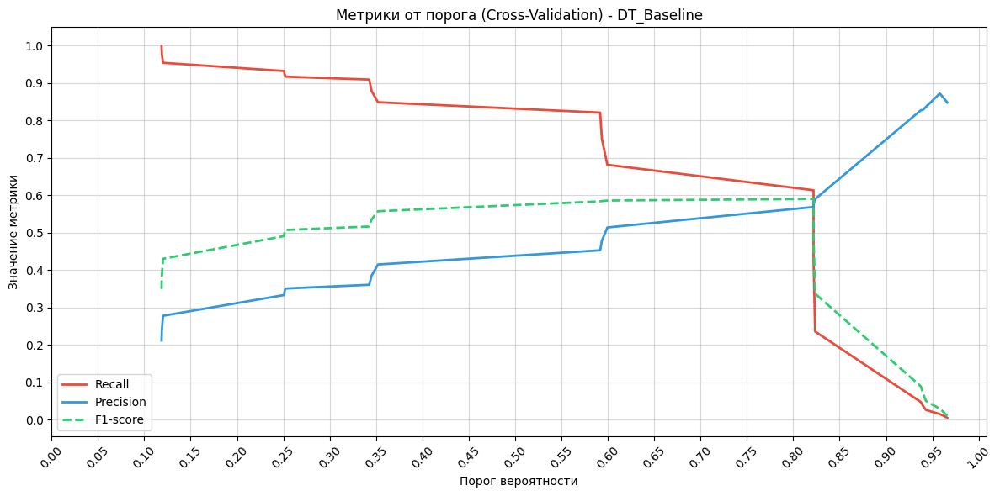

🔍 Важность признаков:


/tmp/ipython-input-2003262232.py:202: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


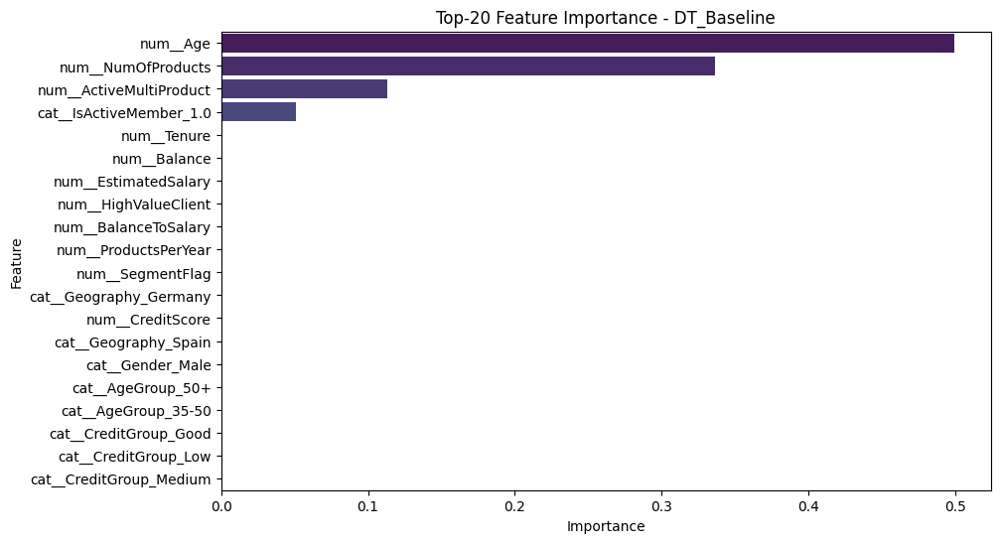

🌳 Визуализация дерева (ТОП-30 уровня) - DT_Baseline:


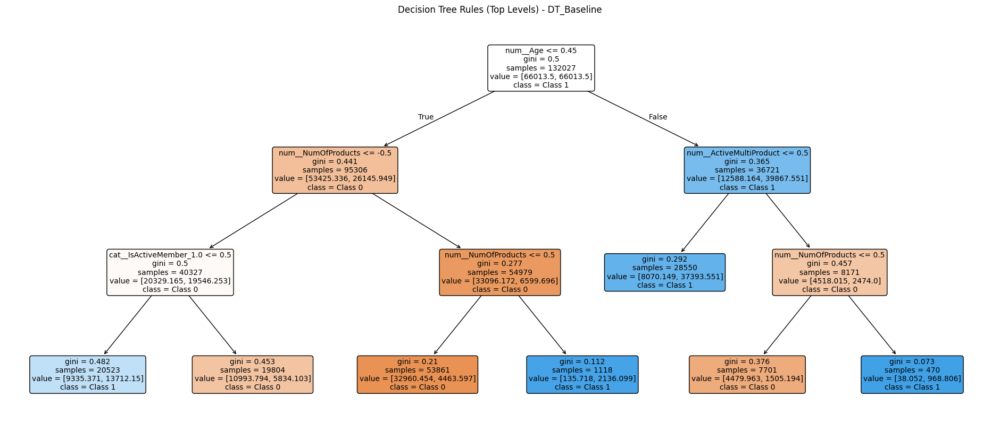


⚙️ АНАЛИЗ МЕТОДА: DT_SMOTE
n_iterations: 5
n_required_iterations: 6
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 500
n_resources: 1620
Fitting 3 folds for each of 500 candidates, totalling 1500 fits
----------
iter: 1
n_candidates: 167
n_resources: 4860
Fitting 3 folds for each of 167 candidates, totalling 501 fits
----------
iter: 2
n_candidates: 56
n_resources: 14580
Fitting 3 folds for each of 56 candidates, totalling 168 fits
----------
iter: 3
n_candidates: 19
n_resources: 43740
Fitting 3 folds for each of 19 candidates, totalling 57 fits
----------
iter: 4
n_candidates: 7
n_resources: 131220
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Лучшие параметры: {'clf__ccp_alpha': np.float64(0.005442902744599254), 'clf__max_depth': 3, 'clf__min_samples_leaf': 13, 'clf__min_samples_split': 20}
⏱️ Время обучения: 6 мин 37 сек
🔄 Генерация CV-прогнозов для аналитики...

📊 CLASSIF

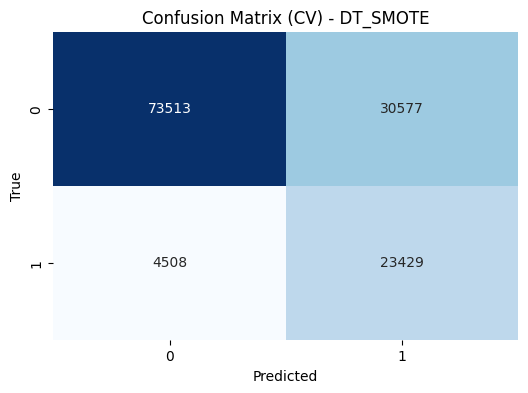

/tmp/ipython-input-2003262232.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


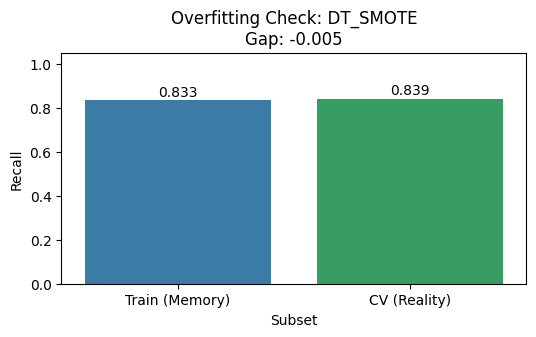

📈 Статичный график метрик (CV Data):


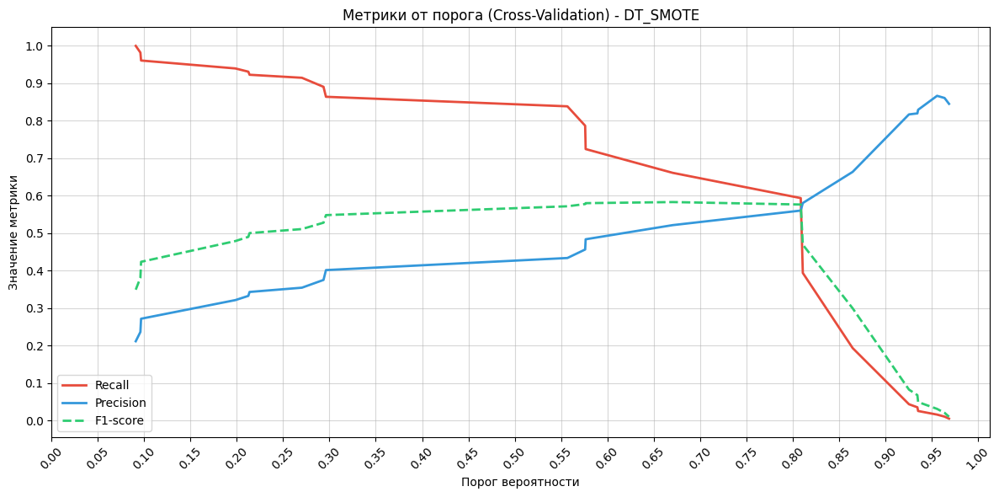

🔍 Важность признаков:


/tmp/ipython-input-2003262232.py:202: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


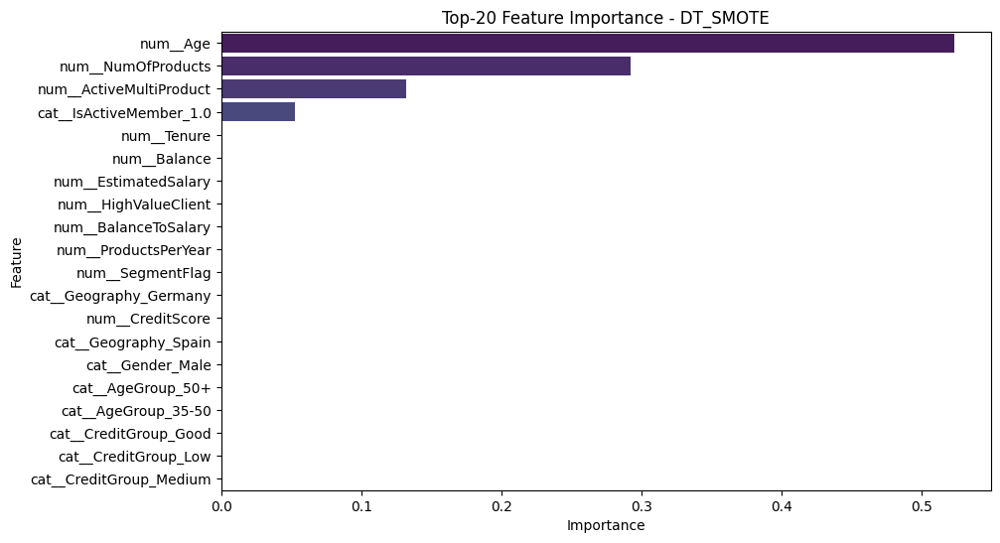

🌳 Визуализация дерева (ТОП-30 уровня) - DT_SMOTE:


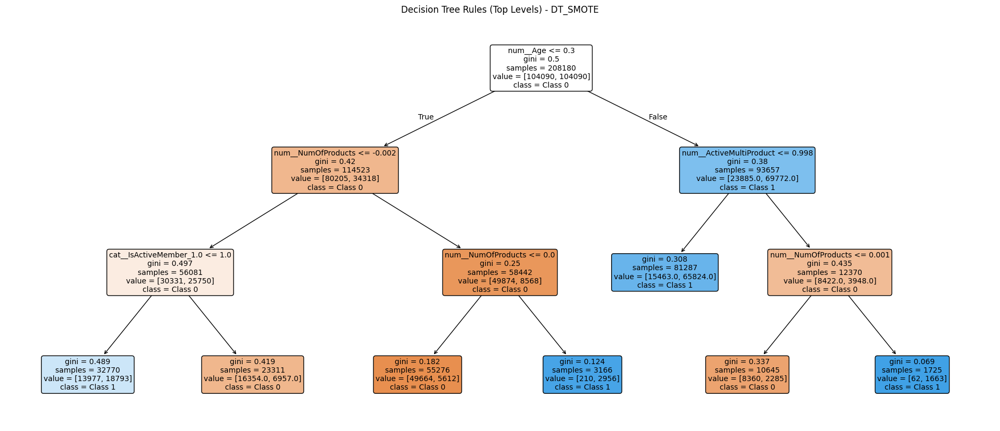


⚙️ АНАЛИЗ МЕТОДА: DT_Undersampling
n_iterations: 5
n_required_iterations: 6
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 500
n_resources: 1620
Fitting 3 folds for each of 500 candidates, totalling 1500 fits
----------
iter: 1
n_candidates: 167
n_resources: 4860
Fitting 3 folds for each of 167 candidates, totalling 501 fits
----------
iter: 2
n_candidates: 56
n_resources: 14580
Fitting 3 folds for each of 56 candidates, totalling 168 fits
----------
iter: 3
n_candidates: 19
n_resources: 43740
Fitting 3 folds for each of 19 candidates, totalling 57 fits
----------
iter: 4
n_candidates: 7
n_resources: 131220
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Лучшие параметры: {'clf__ccp_alpha': np.float64(0.004603705364831106), 'clf__max_depth': 17, 'clf__min_samples_leaf': 20, 'clf__min_samples_split': 5}
⏱️ Время обучения: 3 мин 54 сек
🔄 Генерация CV-прогнозов для аналитики...

📊

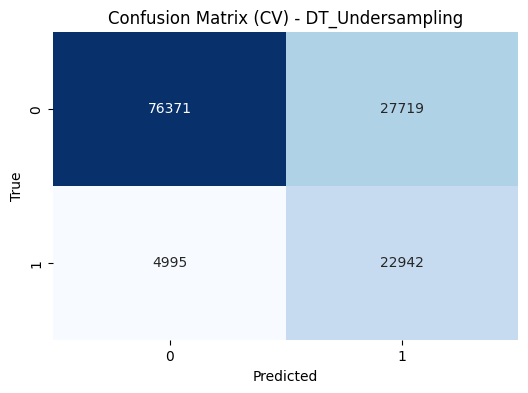

/tmp/ipython-input-2003262232.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


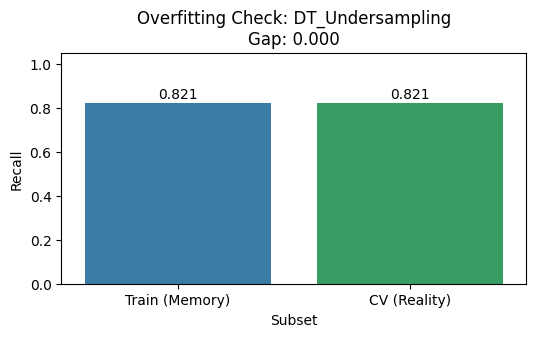

📈 Статичный график метрик (CV Data):


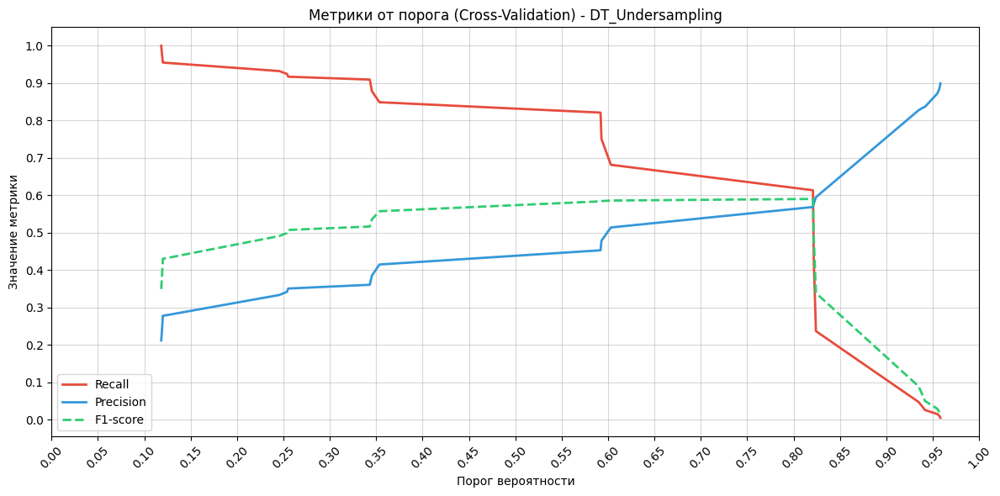

🔍 Важность признаков:


/tmp/ipython-input-2003262232.py:202: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


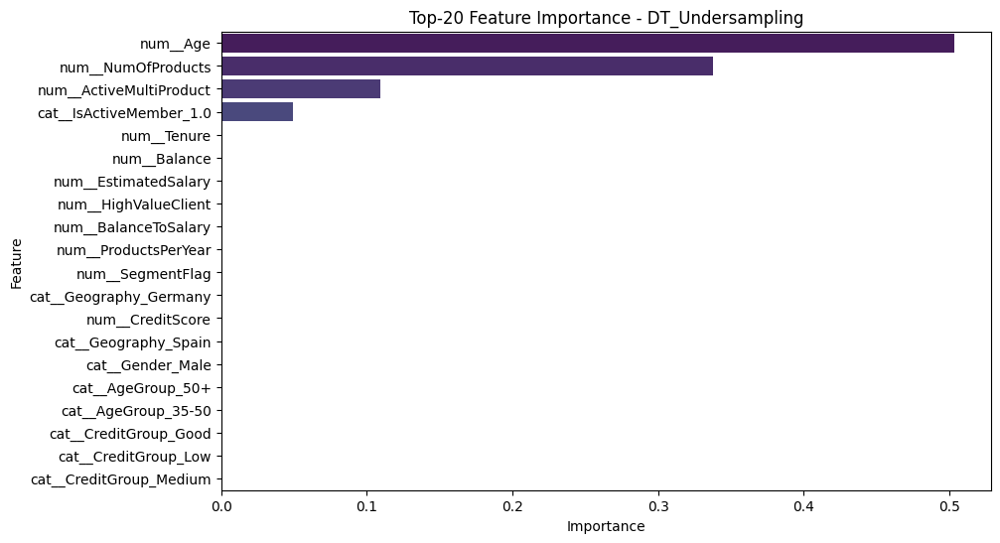

🌳 Визуализация дерева (ТОП-30 уровня) - DT_Undersampling:


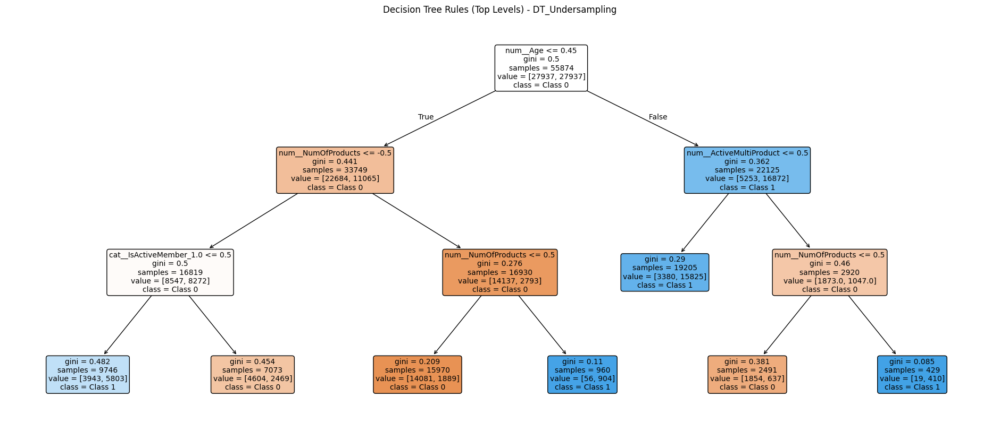


🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)


,Method,Train_Recall,CV_Recall,CV_Precision,CV_AP,Gap,Time
1,DT_SMOTE,0.833411,0.838637,0.433822,0.532515,-0.005226,6m 37s
2,DT_Undersampling,0.821205,0.821205,0.452853,0.526958,0.000000,3m 54s
0,DT_Baseline,0.821205,0.821205,0.452853,0.525012,0.000000,4m 37s


In [ ]:
# 1. Установка библиотек
!pip install -q imbalanced-learn tqdm plotly

# 2. Импорты
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import HalvingRandomSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from tqdm.auto import tqdm

# ==============================================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ==============================================================================


def plot_static_threshold_curve(y_true, y_proba, title):
    """
    Статичный график метрик от порога.
    Строится на данных кросс-валидации внутри цикла.
    """
    prec, rec, thresholds = precision_recall_curve(y_true, y_proba)
    # Убираем последнюю точку для синхронизации размеров
    prec = prec[:-1]
    rec = rec[:-1]
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)

    plt.figure(figsize=(12, 6))
    plt.plot(thresholds, rec, label="Recall", color="#e74c3c", linewidth=2)
    plt.plot(thresholds, prec, label="Precision", color="#3498db", linewidth=2)
    plt.plot(thresholds, f1_scores, label="F1-score", color="#2ecc71", linewidth=2, linestyle="--")

    plt.title(f"Метрики от порога (Cross-Validation) - {title}")
    plt.xlabel("Порог вероятности")
    plt.ylabel("Значение метрики")

    # Сетка с шагом 0.05
    plt.xticks(np.arange(0.0, 1.01, 0.05), rotation=45)
    plt.yticks(np.arange(0.0, 1.01, 0.1))
    plt.grid(True, alpha=0.5, which="both")
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 3. НАСТРОЙКИ
# ==============================================================================

# Стратегия кросс-валидации
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# ВАЖНО: Предполагается, что 'preprocessor', 'X_train' и 'y_train' уже определены выше
# Если нет, убедись, что они есть в контексте ноутбука.

# 1. Пайплайны
dt_pipelines = {
    "DT_Baseline": Pipeline(
        steps=[("preprocessor", preprocessor), ("clf", DecisionTreeClassifier(random_state=42))]
    ),
    "DT_SMOTE": ImbPipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("smote", SMOTE(random_state=42, k_neighbors=5)),
            ("clf", DecisionTreeClassifier(random_state=42)),
        ]
    ),
    "DT_Undersampling": ImbPipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("under", RandomUnderSampler(random_state=42)),
            ("clf", DecisionTreeClassifier(random_state=42)),
        ]
    ),
}

# 2. Параметры
common_params = {
    "clf__max_depth": randint(2, 30),
    "clf__min_samples_leaf": randint(2, 80),
    "clf__min_samples_split": randint(2, 200),
    "clf__ccp_alpha": uniform(0.0, 0.02),
}

dt_param_dists = {
    "DT_Baseline": {**common_params, "clf__class_weight": ["balanced"]},
    "DT_SMOTE": common_params,
    "DT_Undersampling": common_params,
}

# ==============================================================================
# 4. ЗАПУСК (STRICTLY NO TEST LEAKAGE)
# ==============================================================================

best_models_storage = {}
cv_results_storage = {}  # Храним вероятности CV для финального графика
results_summary = []

print("🚀 Запуск Decision Tree (Strict Train/CV Only)\n")

for method_name, pipeline in tqdm(dt_pipelines.items(), desc="Общий прогресс", unit="model"):
    tqdm.write(f"\n{'='*80}")
    tqdm.write(f"⚙️ АНАЛИЗ МЕТОДА: {method_name}")
    tqdm.write(f"{'='*80}")

    search = HalvingRandomSearchCV(
        pipeline,
        dt_param_dists[method_name],
        cv=cv_strategy,
        scoring="recall",
        n_candidates=500,
        min_resources=1620,
        factor=3,
        resource="n_samples",
        random_state=42,
        n_jobs=2,
        verbose=1,
    )

    try:
        # --- ТАЙМЕР СТАРТ ---
        start_time = time.time()

        # Обучаем на Train
        search.fit(X_train, y_train)

        # --- ТАЙМЕР СТОП ---
        end_time = time.time()
        duration = end_time - start_time
        mins = int(duration // 60)
        secs = int(duration % 60)

        best_models_storage[method_name] = search.best_estimator_
        tqdm.write(f"✅ Лучшие параметры: {search.best_params_}")
        tqdm.write(f"⏱️ Время обучения: {mins} мин {secs} сек")

        # -------------------------------------------------------------
        # ГЕНЕРАЦИЯ CV ДАННЫХ (Эмуляция теста на Train)
        # -------------------------------------------------------------
        tqdm.write("🔄 Генерация CV-прогнозов для аналитики...")
        y_pred_cv = cross_val_predict(
            search.best_estimator_, X_train, y_train, cv=cv_strategy, n_jobs=2
        )
        y_proba_cv = cross_val_predict(
            search.best_estimator_,
            X_train,
            y_train,
            cv=cv_strategy,
            n_jobs=2,
            method="predict_proba",
        )[:, 1]

        # 1. ОТЧЕТ (CV)
        tqdm.write(f"\n📊 CLASSIFICATION REPORT (CV) - {method_name}:")
        print(classification_report(y_train, y_pred_cv))

        # 2. МАТРИЦА ОШИБОК (CV)
        plt.figure(figsize=(6, 4))
        sns.heatmap(
            confusion_matrix(y_train, y_pred_cv), annot=True, fmt="d", cmap="Blues", cbar=False
        )
        plt.title(f"Confusion Matrix (CV) - {method_name}")
        plt.ylabel("True")
        plt.xlabel("Predicted")
        plt.show()

        # 3. ПРОВЕРКА НА ПЕРЕОБУЧЕНИЕ (Train vs CV)
        # Train Score (Память)
        y_pred_train_pure = search.best_estimator_.predict(X_train)
        train_recall = recall_score(y_train, y_pred_train_pure)
        # CV Score (Реальность)
        cv_recall = recall_score(y_train, y_pred_cv)

        gap = train_recall - cv_recall

        metrics_df = pd.DataFrame(
            {"Subset": ["Train (Memory)", "CV (Reality)"], "Recall": [train_recall, cv_recall]}
        )
        plt.figure(figsize=(6, 3))
        sns.barplot(data=metrics_df, x="Subset", y="Recall", palette=["#2980b9", "#27ae60"])
        plt.title(f"Overfitting Check: {method_name}\nGap: {gap:.3f}")
        plt.ylim(0, 1.05)
        for index, row in metrics_df.iterrows():
            plt.text(index, row.Recall + 0.02, f"{row.Recall:.3f}", ha="center")
        plt.show()

        # 4. СТАТИЧНЫЙ ГРАФИК ПОРОГОВ (CV)
        tqdm.write("📈 Статичный график метрик (CV Data):")
        plot_static_threshold_curve(y_train, y_proba_cv, method_name)

        # 5. ВАЖНОСТЬ ПРИЗНАКОВ
        tqdm.write("🔍 Важность признаков:")
        try:
            feature_names = search.best_estimator_.named_steps[
                "preprocessor"
            ].get_feature_names_out()
        except:
            feature_names = [f"Feat_{i}" for i in range(X_train.shape[1])]

        importances = search.best_estimator_.named_steps["clf"].feature_importances_

        if len(feature_names) == len(importances):
            feat_imp = pd.DataFrame({"Feature": feature_names, "Importance": importances})
            feat_imp = feat_imp.sort_values(by="Importance", ascending=False).head(20)

            plt.figure(figsize=(10, 6))
            sns.barplot(data=feat_imp, x="Importance", y="Feature", palette="viridis")
            plt.title(f"Top-20 Feature Importance - {method_name}")
            plt.show()
        else:
            print(
                "⚠️ Не удалось сопоставить имена признаков (разная длина). Пропуск графика важности."
            )

        # 6. ВИЗУАЛИЗАЦИЯ ДЕРЕВА
        tqdm.write(f"🌳 Визуализация дерева (ТОП-30 уровня) - {method_name}:")
        try:
            plt.figure(figsize=(24, 10))
            plot_tree(
                search.best_estimator_.named_steps["clf"],
                feature_names=feature_names if len(feature_names) == len(importances) else None,
                class_names=["Class 0", "Class 1"],
                filled=True,
                rounded=True,
                max_depth=3,
                fontsize=10,
            )
            plt.title(f"Decision Tree Rules (Top Levels) - {method_name}")
            plt.show()
        except Exception as e_tree:
            print(f"Не удалось нарисовать дерево: {e_tree}")

        # Сохранение результатов
        cv_results_storage[method_name] = (y_train, y_proba_cv)

        results_summary.append(
            {
                "Method": method_name,
                "Train_Recall": train_recall,
                "CV_Recall": cv_recall,
                "CV_Precision": precision_score(y_train, y_pred_cv),
                "CV_AP": average_precision_score(y_train, y_proba_cv),
                "Gap": gap,
                "Time": f"{mins}m {secs}s",
            }
        )

    except Exception as e:
        tqdm.write(f"❌ ОШИБКА в {method_name}: {e}")
        import traceback

        traceback.print_exc()

# ==============================================================================
# 5. ФИНАЛ: ИТОГОВАЯ ТАБЛИЦА (НА CV)
# ==============================================================================
print("\n" + "=" * 80)
print("🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)")
print("=" * 80)

if results_summary:
    final_df = pd.DataFrame(results_summary).sort_values(by="CV_AP", ascending=False)
    display(final_df.style.background_gradient(subset=["CV_Recall", "CV_AP"], cmap="Greens"))

In [ ]:
import numpy as np
import plotly.graph_objects as go
from sklearn.metrics import precision_recall_curve

# ==============================================================================
# 6. ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на CV данных)
# ==============================================================================

# Проверяем, есть ли данные кросс-валидации
if "cv_results_storage" not in globals() or not cv_results_storage:
    print("❌ Ошибка: Нет данных кросс-валидации. Сначала запустите ячейку с обучением моделей!")
else:
    print("✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...")

    fig = go.Figure()

    # Цвета для моделей (обновил ключи под Decision Tree)
    colors = {
        "DT_Baseline": "#1f77b4",  # Синий
        "DT_SMOTE": "#2ca02c",  # Зеленый
        "DT_Undersampling": "#d62728",  # Красный
    }

    # Проходим по каждой модели
    for name, (y_true_cv, y_proba_cv) in cv_results_storage.items():
        # Считаем кривые
        precision, recall, thresholds = precision_recall_curve(y_true_cv, y_proba_cv)

        # Убираем последнюю точку у метрик, чтобы длины совпали с thresholds
        precision = precision[:-1]
        recall = recall[:-1]

        color = colors.get(name, "black")  # Если имя другое, будет черным

        # 1. Линия RECALL (Сплошная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=recall,
                mode="lines",
                name=f"{name} - Recall",
                line=dict(color=color, width=3),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Recall: %{{y:.3f}}<extra></extra>",
            )
        )

        # 2. Линия PRECISION (Пунктирная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=precision,
                mode="lines",
                name=f"{name} - Precision",
                line=dict(color=color, width=2, dash="dot"),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Precision: %{{y:.3f}}<extra></extra>",
            )
        )

    # Настройка внешнего вида
    fig.update_layout(
        title="<b>Интерактивный выбор порога (на данных Cross-Validation)</b>",
        xaxis_title="Threshold (Порог вероятности)",
        yaxis_title="Значение метрики (Score)",
        hovermode="x unified",  # Единый курсор-линейка
        width=1000,
        height=700,
        template="plotly_white",
        # Настройка осей
        xaxis=dict(
            range=[0, 1],
            dtick=0.05,  # Шаг сетки по X (0.05)
            showgrid=True,
        ),
        yaxis=dict(
            range=[0, 1.05],
            dtick=0.1,  # Шаг сетки по Y (0.1)
            showgrid=True,
        ),
        # Легенда
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    )

    fig.show()

✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...


⚙️ DT Preprocessor: Используем только 4 признака.
🚀 Запуск Decision Tree (Only 4 Features, Strict CV)



Общий прогресс:   0%|          | 0/3 [00:00<?, ?model/s]


⚙️ АНАЛИЗ МЕТОДА: DT_Baseline
n_iterations: 5
n_required_iterations: 6
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 500
n_resources: 1620
Fitting 3 folds for each of 500 candidates, totalling 1500 fits
----------
iter: 1
n_candidates: 167
n_resources: 4860
Fitting 3 folds for each of 167 candidates, totalling 501 fits
----------
iter: 2
n_candidates: 56
n_resources: 14580
Fitting 3 folds for each of 56 candidates, totalling 168 fits
----------
iter: 3
n_candidates: 19
n_resources: 43740
Fitting 3 folds for each of 19 candidates, totalling 57 fits
----------
iter: 4
n_candidates: 7
n_resources: 131220
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Лучшие параметры: {'clf__ccp_alpha': np.float64(0.006291931136188218), 'clf__class_weight': 'balanced', 'clf__max_depth': 28, 'clf__min_samples_leaf': 50, 'clf__min_samples_split': 190}
⏱️ Время обучения: 2 мин 15 сек
🔄 Генерация CV

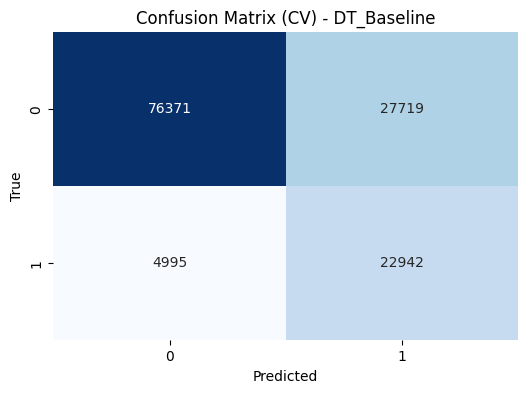

/tmp/ipython-input-3419320940.py:163: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




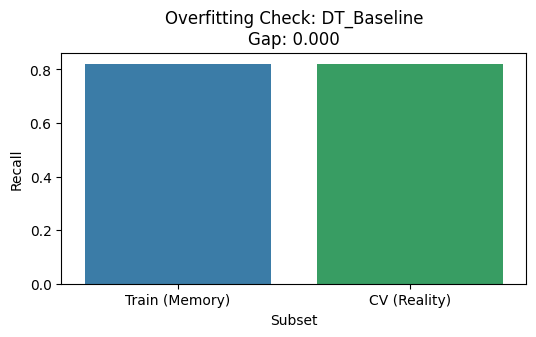

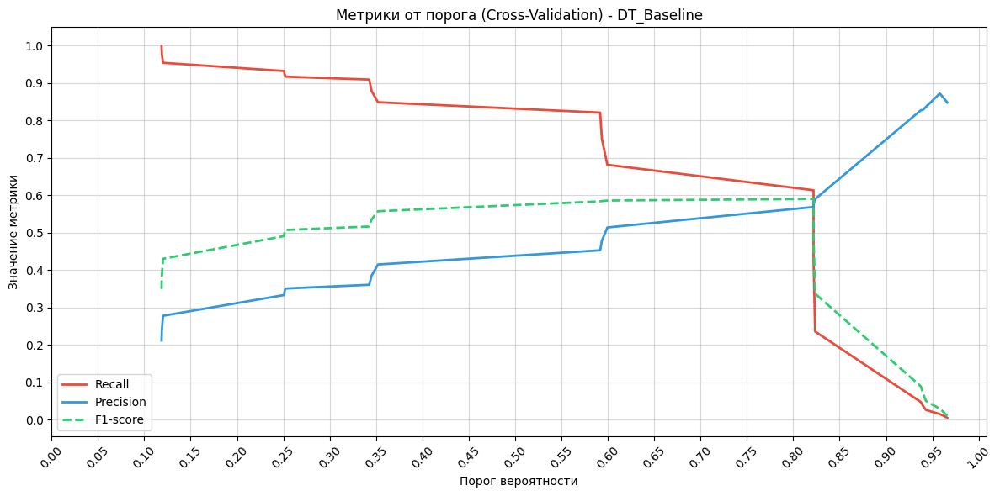

/tmp/ipython-input-3419320940.py:179: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




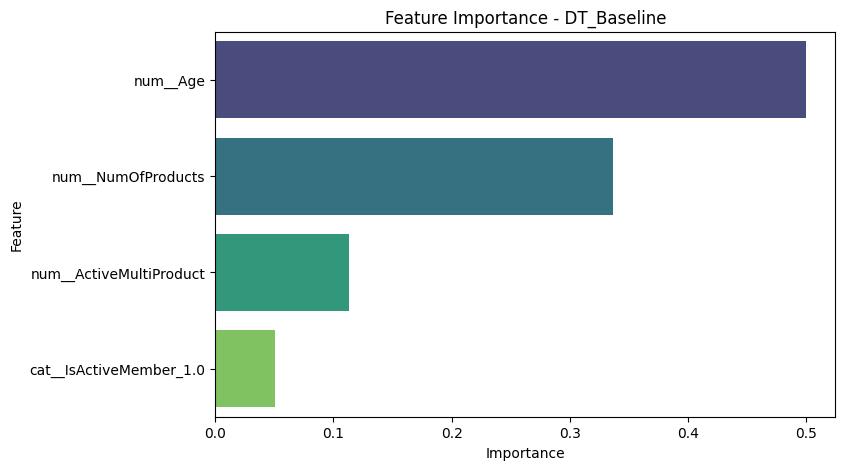

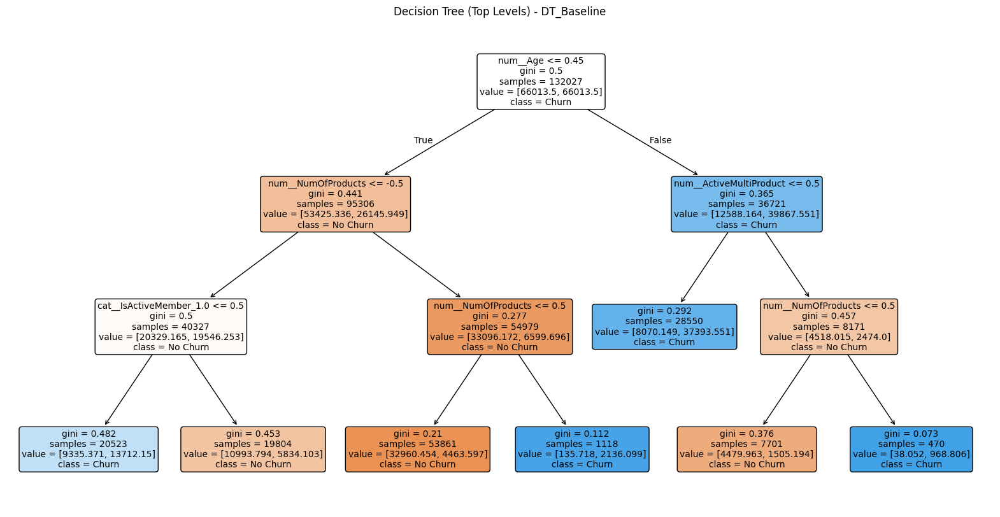


⚙️ АНАЛИЗ МЕТОДА: DT_SMOTE
n_iterations: 5
n_required_iterations: 6
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 500
n_resources: 1620
Fitting 3 folds for each of 500 candidates, totalling 1500 fits
----------
iter: 1
n_candidates: 167
n_resources: 4860
Fitting 3 folds for each of 167 candidates, totalling 501 fits
----------
iter: 2
n_candidates: 56
n_resources: 14580
Fitting 3 folds for each of 56 candidates, totalling 168 fits
----------
iter: 3
n_candidates: 19
n_resources: 43740
Fitting 3 folds for each of 19 candidates, totalling 57 fits
----------
iter: 4
n_candidates: 7
n_resources: 131220
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Лучшие параметры: {'clf__ccp_alpha': np.float64(0.005442902744599254), 'clf__max_depth': 3, 'clf__min_samples_leaf': 13, 'clf__min_samples_split': 20}
⏱️ Время обучения: 2 мин 19 сек
🔄 Генерация CV-прогнозов...

📊 CLASSIFICATION REPORT

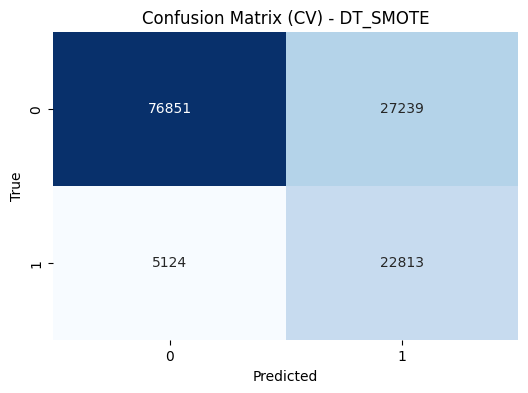

/tmp/ipython-input-3419320940.py:163: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




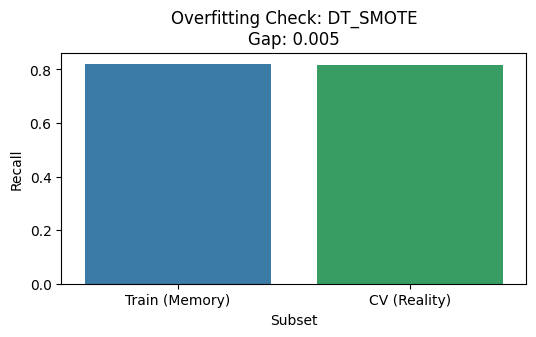

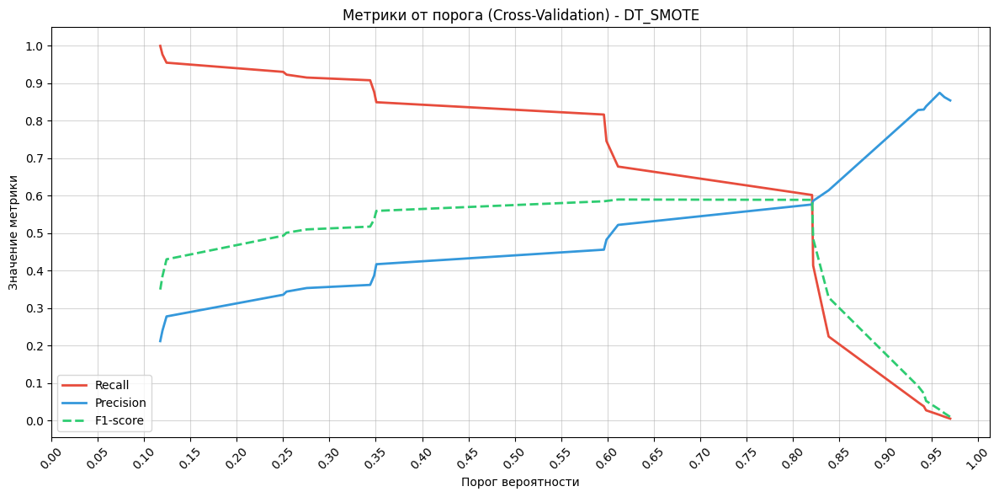

/tmp/ipython-input-3419320940.py:179: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




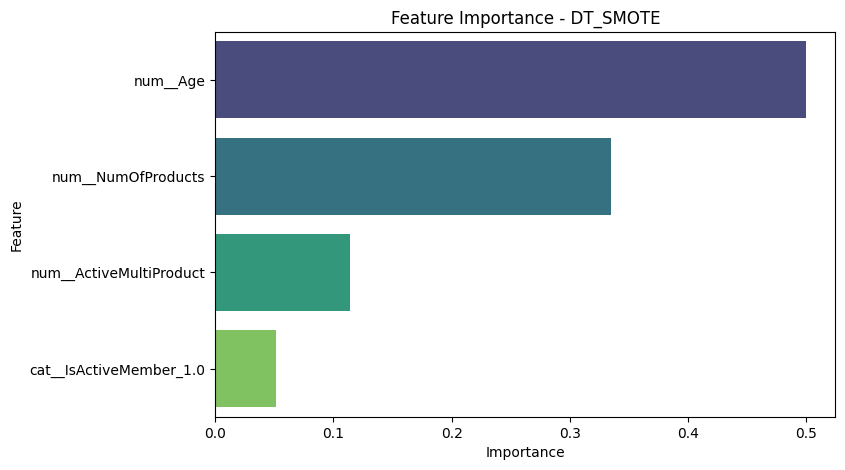

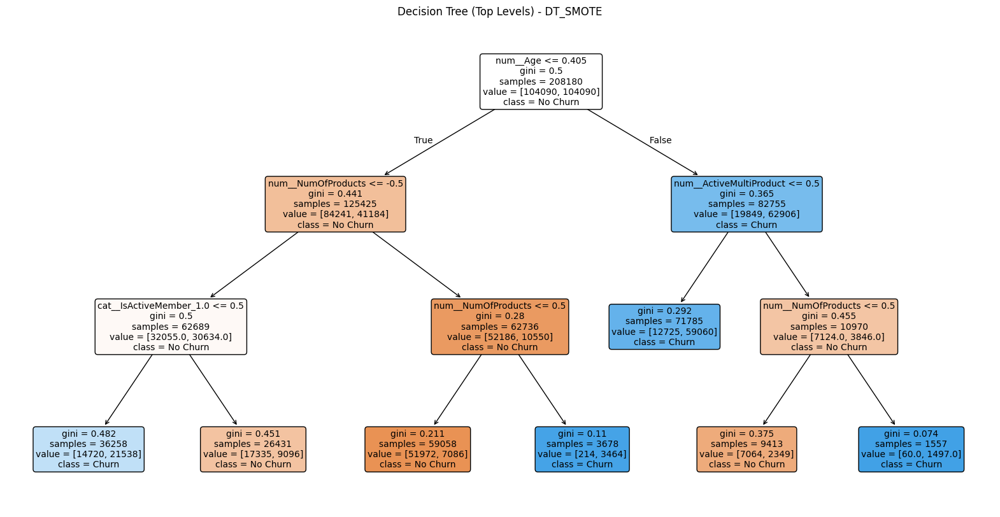


⚙️ АНАЛИЗ МЕТОДА: DT_Undersampling
n_iterations: 5
n_required_iterations: 6
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 500
n_resources: 1620
Fitting 3 folds for each of 500 candidates, totalling 1500 fits
----------
iter: 1
n_candidates: 167
n_resources: 4860
Fitting 3 folds for each of 167 candidates, totalling 501 fits
----------
iter: 2
n_candidates: 56
n_resources: 14580
Fitting 3 folds for each of 56 candidates, totalling 168 fits
----------
iter: 3
n_candidates: 19
n_resources: 43740
Fitting 3 folds for each of 19 candidates, totalling 57 fits
----------
iter: 4
n_candidates: 7
n_resources: 131220
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Лучшие параметры: {'clf__ccp_alpha': np.float64(0.0053356202855057), 'clf__max_depth': 3, 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 55}
⏱️ Время обучения: 2 мин 22 сек
🔄 Генерация CV-прогнозов...

📊 CLASSIFICATION R

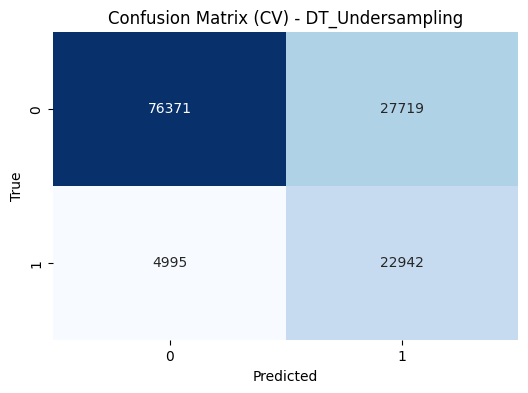

/tmp/ipython-input-3419320940.py:163: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




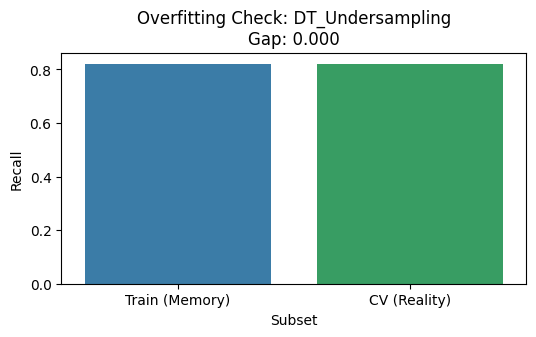

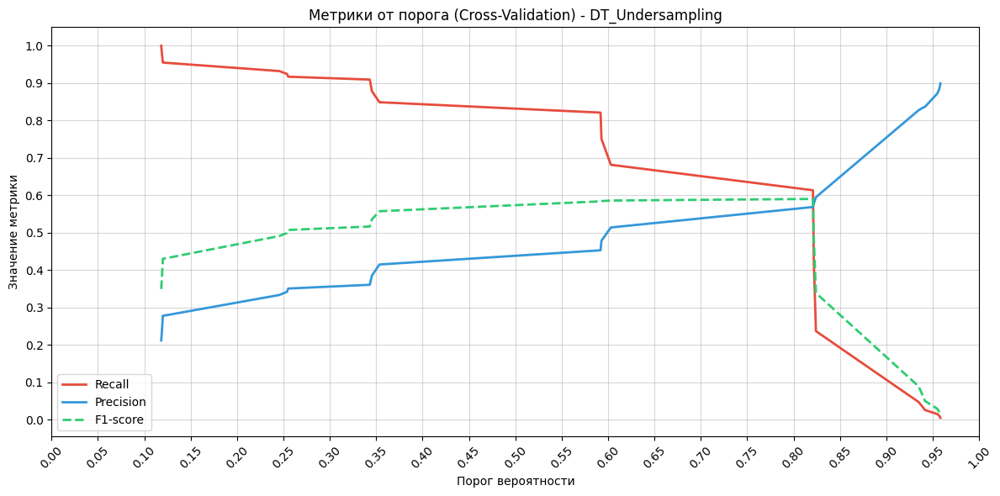

/tmp/ipython-input-3419320940.py:179: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




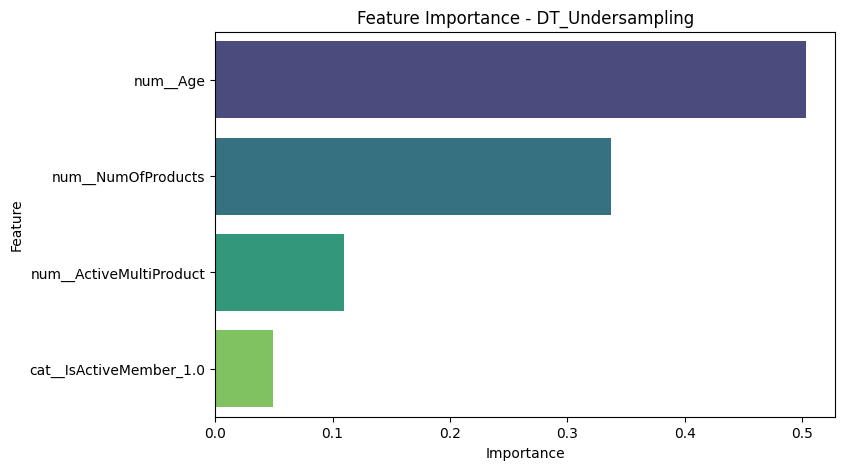

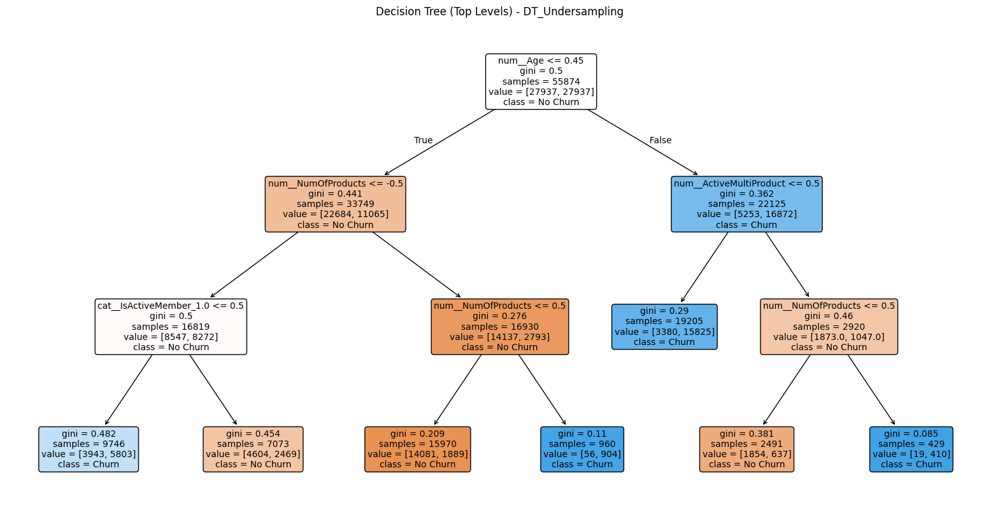


🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)


,Method,Train_Recall,CV_Recall,CV_Precision,CV_AP,Gap,Time
1,DT_SMOTE,0.821205,0.816587,0.455786,0.533186,0.004618,2m 19s
2,DT_Undersampling,0.821205,0.821205,0.452853,0.526958,0.000000,2m 22s
0,DT_Baseline,0.821205,0.821205,0.452853,0.525012,0.000000,2m 15s


In [ ]:
# 1. Установка библиотек
!pip install -q imbalanced-learn tqdm plotly

# 2. Импорты
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import HalvingRandomSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from tqdm.auto import tqdm

# ==============================================================================
# 1. СПЕЦИАЛЬНЫЙ ПРЕПРОЦЕССОР (ТОЛЬКО 4 ПРИЗНАКА ДЛЯ DT)
# ==============================================================================
dt_numeric_cols = ["Age", "NumOfProducts", "ActiveMultiProduct"]
dt_cat_cols = ["IsActiveMember"]

numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
    ]
)

dt_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, dt_numeric_cols),
        ("cat", categorical_transformer, dt_cat_cols),
    ],
    remainder="drop",
)

print(f"⚙️ DT Preprocessor: Используем только {len(dt_numeric_cols) + len(dt_cat_cols)} признака.")


# ==============================================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ==============================================================================
def plot_static_threshold_curve(y_true, y_proba, title):
    prec, rec, thresholds = precision_recall_curve(y_true, y_proba)
    prec = prec[:-1]
    rec = rec[:-1]
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)

    plt.figure(figsize=(12, 6))
    plt.plot(thresholds, rec, label="Recall", color="#e74c3c", linewidth=2)
    plt.plot(thresholds, prec, label="Precision", color="#3498db", linewidth=2)
    plt.plot(thresholds, f1_scores, label="F1-score", color="#2ecc71", linewidth=2, linestyle="--")
    plt.title(f"Метрики от порога (Cross-Validation) - {title}")
    plt.xlabel("Порог вероятности")
    plt.ylabel("Значение метрики")
    plt.xticks(np.arange(0.0, 1.01, 0.05), rotation=45)
    plt.yticks(np.arange(0.0, 1.01, 0.1))
    plt.grid(True, alpha=0.5, which="both")
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 3. НАСТРОЙКИ
# ==============================================================================
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

dt_pipelines = {
    "DT_Baseline": Pipeline(
        steps=[("preprocessor", dt_preprocessor), ("clf", DecisionTreeClassifier(random_state=42))]
    ),
    "DT_SMOTE": ImbPipeline(
        steps=[
            ("preprocessor", dt_preprocessor),
            ("smote", SMOTE(random_state=42, k_neighbors=5)),
            ("clf", DecisionTreeClassifier(random_state=42)),
        ]
    ),
    "DT_Undersampling": ImbPipeline(
        steps=[
            ("preprocessor", dt_preprocessor),
            ("under", RandomUnderSampler(random_state=42)),
            ("clf", DecisionTreeClassifier(random_state=42)),
        ]
    ),
}

common_params = {
    "clf__max_depth": randint(2, 30),
    "clf__min_samples_leaf": randint(2, 80),
    "clf__min_samples_split": randint(2, 200),
    "clf__ccp_alpha": uniform(0.0, 0.02),
}

dt_param_dists = {
    "DT_Baseline": {**common_params, "clf__class_weight": ["balanced"]},
    "DT_SMOTE": common_params,
    "DT_Undersampling": common_params,
}

# ==============================================================================
# 4. ЗАПУСК ОБУЧЕНИЯ (STRICTLY NO TEST LEAKAGE + TIMER)
# ==============================================================================
best_models_storage = {}
cv_results_storage = {}
results_summary = []

print("🚀 Запуск Decision Tree (Only 4 Features, Strict CV)\n")

for method_name, pipeline in tqdm(dt_pipelines.items(), desc="Общий прогресс", unit="model"):
    tqdm.write(f"\n{'='*80}\n⚙️ АНАЛИЗ МЕТОДА: {method_name}\n{'='*80}")

    search = HalvingRandomSearchCV(
        pipeline,
        dt_param_dists[method_name],
        cv=cv_strategy,
        scoring="recall",
        n_candidates=500,
        min_resources=1620,
        factor=3,
        resource="n_samples",
        random_state=42,
        n_jobs=2,
        verbose=1,
    )

    try:
        start_time = time.time()
        search.fit(X_train, y_train)  # Используются ваши X_train, y_train
        duration = time.time() - start_time
        mins, secs = int(duration // 60), int(duration % 60)

        best_models_storage[method_name] = search.best_estimator_
        tqdm.write(f"✅ Лучшие параметры: {search.best_params_}")
        tqdm.write(f"⏱️ Время обучения: {mins} мин {secs} сек")

        tqdm.write("🔄 Генерация CV-прогнозов...")
        y_pred_cv = cross_val_predict(
            search.best_estimator_, X_train, y_train, cv=cv_strategy, n_jobs=2
        )
        y_proba_cv = cross_val_predict(
            search.best_estimator_,
            X_train,
            y_train,
            cv=cv_strategy,
            n_jobs=2,
            method="predict_proba",
        )[:, 1]

        print(f"\n📊 CLASSIFICATION REPORT (CV) - {method_name}:")
        print(classification_report(y_train, y_pred_cv))

        plt.figure(figsize=(6, 4))
        sns.heatmap(
            confusion_matrix(y_train, y_pred_cv), annot=True, fmt="d", cmap="Blues", cbar=False
        )
        plt.title(f"Confusion Matrix (CV) - {method_name}")
        plt.ylabel("True")
        plt.xlabel("Predicted")
        plt.show()

        y_pred_train_pure = search.best_estimator_.predict(X_train)
        train_recall = recall_score(y_train, y_pred_train_pure)
        cv_recall = recall_score(y_train, y_pred_cv)
        gap = train_recall - cv_recall

        metrics_df = pd.DataFrame(
            {"Subset": ["Train (Memory)", "CV (Reality)"], "Recall": [train_recall, cv_recall]}
        )
        plt.figure(figsize=(6, 3))
        sns.barplot(data=metrics_df, x="Subset", y="Recall", palette=["#2980b9", "#27ae60"])
        plt.title(f"Overfitting Check: {method_name}\nGap: {gap:.3f}")
        plt.show()

        plot_static_threshold_curve(y_train, y_proba_cv, method_name)

        try:
            feature_names = search.best_estimator_.named_steps[
                "preprocessor"
            ].get_feature_names_out()
        except:
            feature_names = dt_numeric_cols + dt_cat_cols

        importances = search.best_estimator_.named_steps["clf"].feature_importances_

        if len(feature_names) == len(importances):
            feat_imp = pd.DataFrame(
                {"Feature": feature_names, "Importance": importances}
            ).sort_values(by="Importance", ascending=False)
            plt.figure(figsize=(8, 5))
            sns.barplot(data=feat_imp, x="Importance", y="Feature", palette="viridis")
            plt.title(f"Feature Importance - {method_name}")
            plt.show()

            plt.figure(figsize=(20, 10))
            plot_tree(
                search.best_estimator_.named_steps["clf"],
                feature_names=feature_names,
                class_names=["No Churn", "Churn"],
                filled=True,
                rounded=True,
                max_depth=4,
                fontsize=10,
            )
            plt.title(f"Decision Tree (Top Levels) - {method_name}")
            plt.show()

        cv_results_storage[method_name] = (y_train, y_proba_cv)
        results_summary.append(
            {
                "Method": method_name,
                "Train_Recall": train_recall,
                "CV_Recall": cv_recall,
                "CV_Precision": precision_score(y_train, y_pred_cv),
                "CV_AP": average_precision_score(y_train, y_proba_cv),
                "Gap": gap,
                "Time": f"{mins}m {secs}s",
            }
        )
    except Exception as e:
        t_err = f"❌ ОШИБКА в {method_name}: {e}"
        tqdm.write(t_err)

# 5. ФИНАЛ: ИТОГОВАЯ ТАБЛИЦА
print("\n" + "=" * 80 + "\n🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)\n" + "=" * 80)
if results_summary:
    final_df = pd.DataFrame(results_summary).sort_values(by="CV_AP", ascending=False)
    display(final_df.style.background_gradient(subset=["CV_Recall", "CV_AP"], cmap="Greens"))

In [ ]:
import numpy as np
import plotly.graph_objects as go
from sklearn.metrics import precision_recall_curve

print("\n" + "=" * 80)
print("📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на CV данных)")
print("Наведи курсор, чтобы увидеть Recall, Precision и Порог для каждой модели.")

# Проверяем, есть ли данные кросс-валидации
if "cv_results_storage" not in globals() or not cv_results_storage:
    print("❌ Ошибка: Нет данных кросс-валидации. Сначала запустите ячейку с обучением моделей!")
else:
    print("✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...")

    fig = go.Figure()

    # Цвета для моделей (DT)
    colors = {
        "DT_Baseline": "#1f77b4",  # Синий
        "DT_SMOTE": "#2ca02c",  # Зеленый
        "DT_Undersampling": "#d62728",  # Красный
    }

    for name, (y_true_cv, y_proba_cv) in cv_results_storage.items():
        precision, recall, thresholds = precision_recall_curve(y_true_cv, y_proba_cv)

        # Убираем последнюю точку, чтобы совпало с длиной thresholds
        precision = precision[:-1]
        recall = recall[:-1]

        color = colors.get(name, "black")

        # 1. Линия RECALL (Сплошная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=recall,
                mode="lines",
                name=f"{name} - Recall",
                line=dict(color=color, width=3),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Recall: %{{y:.3f}}<extra></extra>",
            )
        )

        # 2. Линия PRECISION (Пунктирная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=precision,
                mode="lines",
                name=f"{name} - Precision",
                line=dict(color=color, width=2, dash="dot"),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Precision: %{{y:.3f}}<extra></extra>",
            )
        )

    fig.update_layout(
        title="<b>Интерактивный выбор порога (на данных Cross-Validation)</b>",
        xaxis_title="Threshold (Порог вероятности)",
        yaxis_title="Значение метрики (Score)",
        hovermode="x unified",
        width=1000,
        height=700,
        template="plotly_white",
        xaxis=dict(range=[0, 1], dtick=0.05, showgrid=True),
        yaxis=dict(range=[0, 1.05], dtick=0.1, showgrid=True),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    )

    fig.show()


📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на CV данных)
Наведи курсор, чтобы увидеть Recall, Precision и Порог для каждой модели.
✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...


# Random Forest

🚀 Запуск Random Forest (Strict Train/CV Only)



Общий прогресс:   0%|          | 0/3 [00:00<?, ?model/s]


⚙️ АНАЛИЗ МЕТОДА: RF_Baseline
n_iterations: 5
n_required_iterations: 5
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 243
n_resources: 1620
Fitting 3 folds for each of 243 candidates, totalling 729 fits
----------
iter: 1
n_candidates: 81
n_resources: 4860
Fitting 3 folds for each of 81 candidates, totalling 243 fits
----------
iter: 2
n_candidates: 27
n_resources: 14580
Fitting 3 folds for each of 27 candidates, totalling 81 fits
----------
iter: 3
n_candidates: 9
n_resources: 43740
Fitting 3 folds for each of 9 candidates, totalling 27 fits
----------
iter: 4
n_candidates: 3
n_resources: 131220
Fitting 3 folds for each of 3 candidates, totalling 9 fits
⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): 2999.59 сек. (49.99 мин.)
✅ Лучшие параметры: {'clf__bootstrap': True, 'clf__class_weight': 'balanced', 'clf__max_depth': 4, 'clf__max_features': 0.8, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 2, 'clf__n_

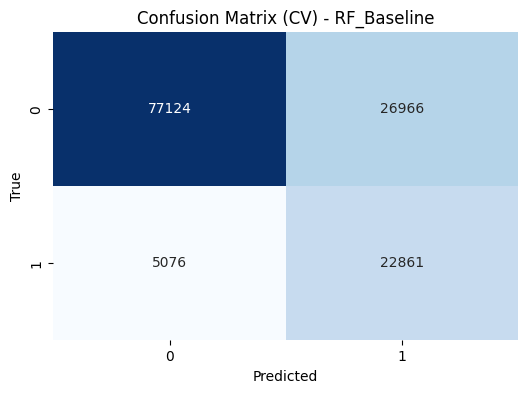

/tmp/ipython-input-1897970154.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


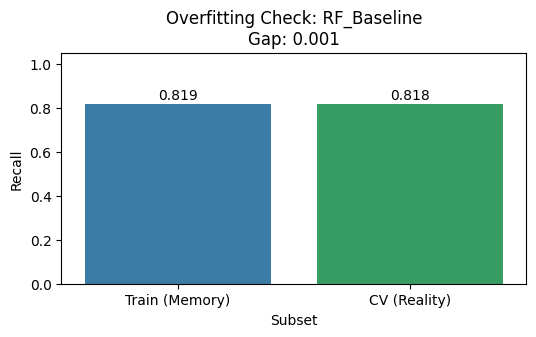

📈 Статичный график метрик (CV Data):


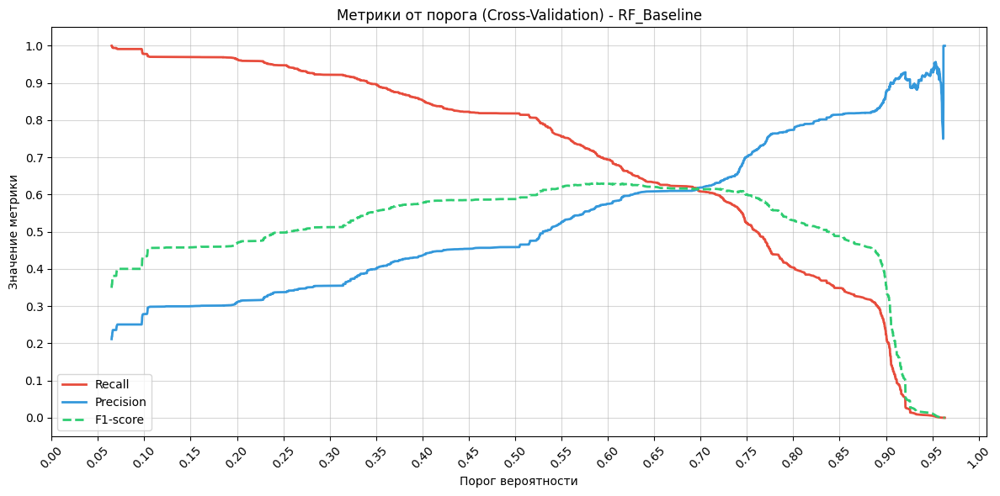

🔍 Важность признаков:


/tmp/ipython-input-1897970154.py:191: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


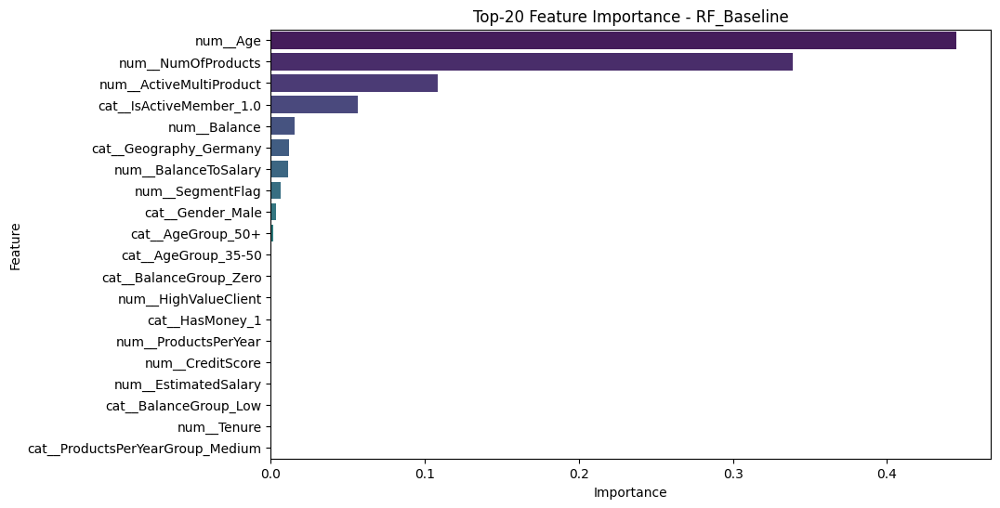


⚙️ АНАЛИЗ МЕТОДА: RF_SMOTE
n_iterations: 5
n_required_iterations: 5
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 243
n_resources: 1620
Fitting 3 folds for each of 243 candidates, totalling 729 fits
----------
iter: 1
n_candidates: 81
n_resources: 4860
Fitting 3 folds for each of 81 candidates, totalling 243 fits
----------
iter: 2
n_candidates: 27
n_resources: 14580
Fitting 3 folds for each of 27 candidates, totalling 81 fits
----------
iter: 3
n_candidates: 9
n_resources: 43740
Fitting 3 folds for each of 9 candidates, totalling 27 fits
----------
iter: 4
n_candidates: 3
n_resources: 131220
Fitting 3 folds for each of 3 candidates, totalling 9 fits
⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): 5717.84 сек. (95.30 мин.)
✅ Лучшие параметры: {'clf__bootstrap': True, 'clf__max_depth': 4, 'clf__max_features': None, 'clf__min_samples_leaf': 6, 'clf__min_samples_split': 7, 'clf__n_estimators': 169}
🔄 Генерация CV-пр

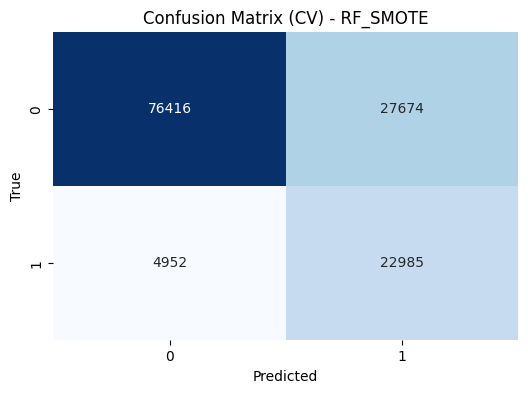

/tmp/ipython-input-1897970154.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


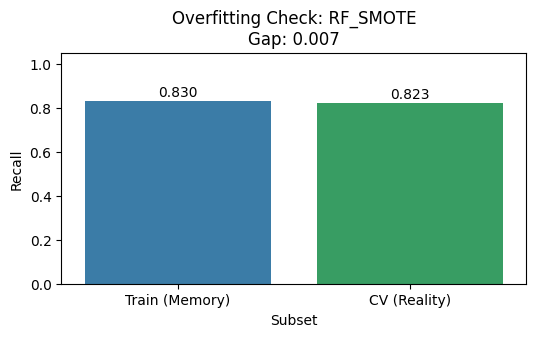

📈 Статичный график метрик (CV Data):


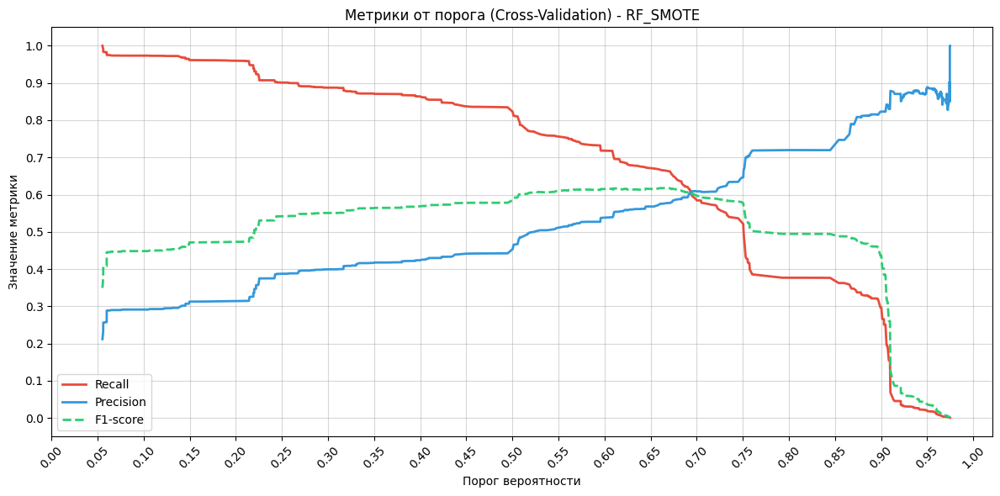

🔍 Важность признаков:


/tmp/ipython-input-1897970154.py:191: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


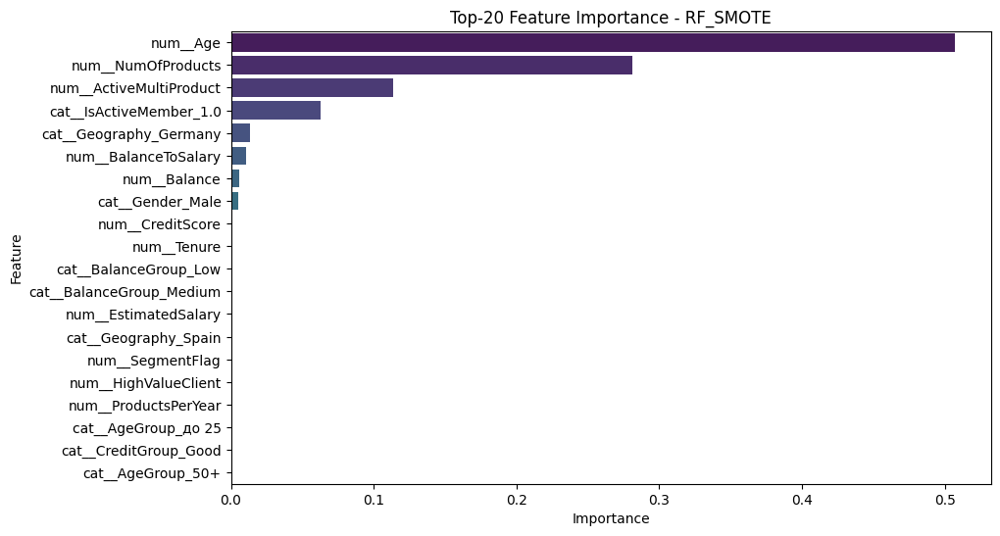


⚙️ АНАЛИЗ МЕТОДА: RF_Undersampling
n_iterations: 5
n_required_iterations: 5
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 243
n_resources: 1620
Fitting 3 folds for each of 243 candidates, totalling 729 fits
----------
iter: 1
n_candidates: 81
n_resources: 4860
Fitting 3 folds for each of 81 candidates, totalling 243 fits
----------
iter: 2
n_candidates: 27
n_resources: 14580
Fitting 3 folds for each of 27 candidates, totalling 81 fits
----------
iter: 3
n_candidates: 9
n_resources: 43740
Fitting 3 folds for each of 9 candidates, totalling 27 fits
----------
iter: 4
n_candidates: 3
n_resources: 131220
Fitting 3 folds for each of 3 candidates, totalling 9 fits
⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): 1666.86 сек. (27.78 мин.)
✅ Лучшие параметры: {'clf__bootstrap': False, 'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 8, 'clf__n_estimators': 185}
🔄 Ген

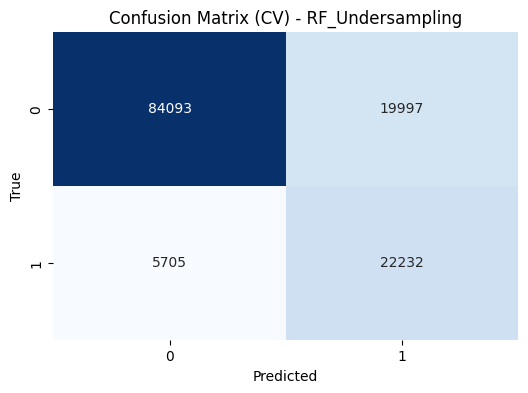

/tmp/ipython-input-1897970154.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


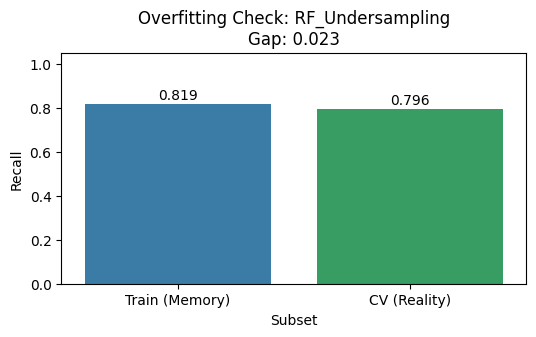

📈 Статичный график метрик (CV Data):


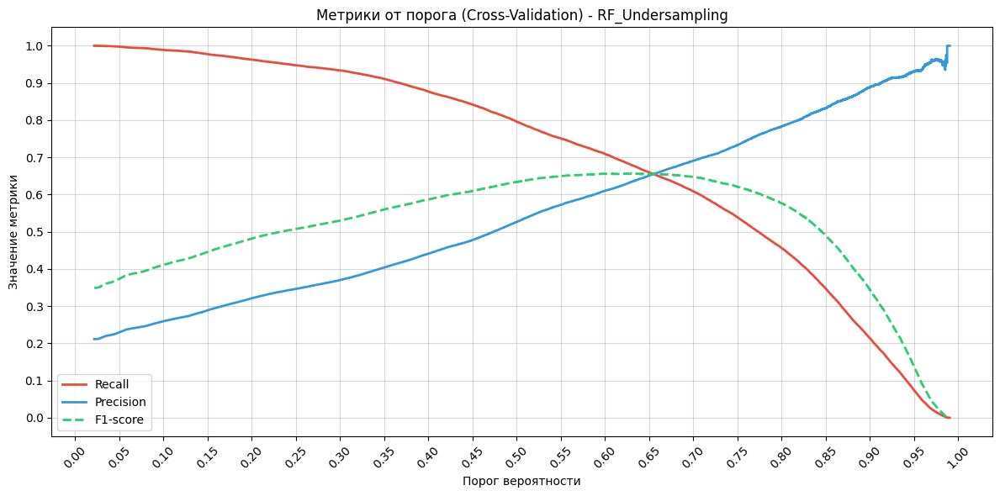

🔍 Важность признаков:


/tmp/ipython-input-1897970154.py:191: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


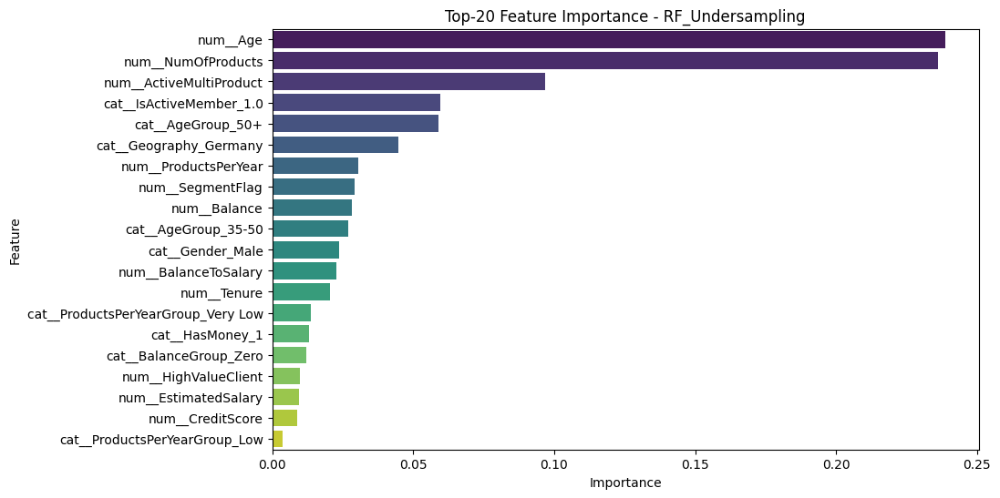


🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)


,Method,Time_Sec,Train_Recall,CV_Recall,CV_Precision,CV_AP,Gap
2,RF_Undersampling,1666.860000,0.818735,0.795791,0.526463,0.710513,0.022944
0,RF_Baseline,2999.590000,0.819165,0.818305,0.458807,0.680150,0.000859
1,RF_SMOTE,5717.840000,0.829545,0.822744,0.453720,0.642101,0.006801


In [ ]:
# 1. Установка библиотек
# !pip install -q imbalanced-learn tqdm plotly

# 2. Импорты
import time  # <--- ДОБАВЛЕНО ДЛЯ ТАЙМЕРА

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import HalvingRandomSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from tqdm.auto import tqdm


# ==============================================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ==============================================================================
def plot_static_threshold_curve(y_true, y_proba, title):
    """
    Статичный график метрик от порога.
    Строится на данных кросс-валидации внутри цикла.
    """
    prec, rec, thresholds = precision_recall_curve(y_true, y_proba)
    # Убираем последнюю точку для синхронизации размеров
    prec = prec[:-1]
    rec = rec[:-1]
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)

    plt.figure(figsize=(12, 6))
    plt.plot(thresholds, rec, label="Recall", color="#e74c3c", linewidth=2)
    plt.plot(thresholds, prec, label="Precision", color="#3498db", linewidth=2)
    plt.plot(thresholds, f1_scores, label="F1-score", color="#2ecc71", linewidth=2, linestyle="--")

    plt.title(f"Метрики от порога (Cross-Validation) - {title}")
    plt.xlabel("Порог вероятности")
    plt.ylabel("Значение метрики")
    # Сетка с шагом 0.05
    plt.xticks(np.arange(0.0, 1.01, 0.05), rotation=45)
    plt.yticks(np.arange(0.0, 1.01, 0.1))
    plt.grid(True, alpha=0.5, which="both")
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 3. НАСТРОЙКИ
# ==============================================================================
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rf_pipelines = {
    "RF_Baseline": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("clf", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]
    ),
    "RF_SMOTE": ImbPipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("smote", SMOTE(random_state=42, k_neighbors=5)),
            ("clf", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]
    ),
    "RF_Undersampling": ImbPipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("under", RandomUnderSampler(random_state=42)),
            ("clf", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]
    ),
}

# Параметры (Полный набор)
common_params = {
    "clf__n_estimators": randint(100, 500),
    "clf__max_depth": randint(4, 30),
    "clf__min_samples_leaf": randint(1, 10),
    "clf__min_samples_split": randint(2, 20),
    "clf__max_features": ["sqrt", 0.3, 0.5, 0.8, None],
    "clf__bootstrap": [True, False],
}

rf_param_dists = {
    "RF_Baseline": {**common_params, "clf__class_weight": ["balanced", "balanced_subsample"]},
    "RF_SMOTE": common_params,
    "RF_Undersampling": common_params,
}

# ==============================================================================
# 4. ЗАПУСК ОБУЧЕНИЯ (STRICTLY NO TEST LEAKAGE)
# ==============================================================================
best_models_storage = {}
cv_results_storage = {}  # Храним вероятности CV для финального графика
results_summary = []

print("🚀 Запуск Random Forest (Strict Train/CV Only)\n")

for method_name, pipeline in tqdm(rf_pipelines.items(), desc="Общий прогресс", unit="model"):
    tqdm.write(f"\n{'='*80}")
    tqdm.write(f"⚙️ АНАЛИЗ МЕТОДА: {method_name}")
    tqdm.write(f"{'='*80}")

    search = HalvingRandomSearchCV(
        pipeline,
        rf_param_dists[method_name],
        cv=cv_strategy,
        scoring="recall",
        n_candidates=243,
        min_resources=1620,
        factor=3,
        resource="n_samples",
        random_state=42,
        n_jobs=2,
        verbose=1,
    )

    try:
        # --- ДОБАВЛЕНО: ЗАПУСК ТАЙМЕРА ---
        start_time = time.time()

        # Обучаем на Train
        search.fit(X_train, y_train)

        # --- ДОБАВЛЕНО: ОСТАНОВКА ТАЙМЕРА И ВЫВОД ---
        end_time = time.time()
        training_duration = end_time - start_time
        tqdm.write(
            f"⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): {training_duration:.2f} сек. ({training_duration/60:.2f} мин.)"
        )

        best_models_storage[method_name] = search.best_estimator_
        tqdm.write(f"✅ Лучшие параметры: {search.best_params_}")

        # -------------------------------------------------------------
        # ГЕНЕРАЦИЯ CV ДАННЫХ (Эмуляция теста на Train)
        # -------------------------------------------------------------
        tqdm.write("🔄 Генерация CV-прогнозов для аналитики...")
        y_pred_cv = cross_val_predict(
            search.best_estimator_, X_train, y_train, cv=cv_strategy, n_jobs=2
        )
        y_proba_cv = cross_val_predict(
            search.best_estimator_,
            X_train,
            y_train,
            cv=cv_strategy,
            n_jobs=2,
            method="predict_proba",
        )[:, 1]

        # 1. ОТЧЕТ (CV)
        tqdm.write(f"\n📊 CLASSIFICATION REPORT (Cross-Validation) - {method_name}:")
        print(classification_report(y_train, y_pred_cv))

        # 2. МАТРИЦА ОШИБОК (CV)
        plt.figure(figsize=(6, 4))
        sns.heatmap(
            confusion_matrix(y_train, y_pred_cv), annot=True, fmt="d", cmap="Blues", cbar=False
        )
        plt.title(f"Confusion Matrix (CV) - {method_name}")
        plt.ylabel("True")
        plt.xlabel("Predicted")
        plt.show()

        # 3. ПРОВЕРКА НА ПЕРЕОБУЧЕНИЕ (Train vs CV)
        # Train Score (Память)
        y_pred_train_pure = search.best_estimator_.predict(X_train)
        train_recall = recall_score(y_train, y_pred_train_pure)
        # CV Score (Реальность)
        cv_recall = recall_score(y_train, y_pred_cv)

        gap = train_recall - cv_recall

        metrics_df = pd.DataFrame(
            {"Subset": ["Train (Memory)", "CV (Reality)"], "Recall": [train_recall, cv_recall]}
        )
        plt.figure(figsize=(6, 3))
        sns.barplot(data=metrics_df, x="Subset", y="Recall", palette=["#2980b9", "#27ae60"])
        plt.title(f"Overfitting Check: {method_name}\nGap: {gap:.3f}")
        plt.ylim(0, 1.05)
        for index, row in metrics_df.iterrows():
            plt.text(index, row.Recall + 0.02, f"{row.Recall:.3f}", ha="center")
        plt.show()

        # 4. СТАТИЧНЫЙ ГРАФИК ПОРОГОВ (CV)
        tqdm.write("📈 Статичный график метрик (CV Data):")
        plot_static_threshold_curve(y_train, y_proba_cv, method_name)

        # 5. ВАЖНОСТЬ ПРИЗНАКОВ
        tqdm.write("🔍 Важность признаков:")
        try:
            feature_names = search.best_estimator_.named_steps[
                "preprocessor"
            ].get_feature_names_out()
        except:
            # Fallback
            feature_names = [f"Feature_{i}" for i in range(X_train.shape[1])]

        importances = search.best_estimator_.named_steps["clf"].feature_importances_

        if len(feature_names) == len(importances):
            feat_imp = pd.DataFrame({"Feature": feature_names, "Importance": importances})
            feat_imp = feat_imp.sort_values(by="Importance", ascending=False).head(20)

            plt.figure(figsize=(10, 6))
            sns.barplot(data=feat_imp, x="Importance", y="Feature", palette="viridis")
            plt.title(f"Top-20 Feature Importance - {method_name}")
            plt.show()
        else:
            print(
                "⚠️ Не удалось сопоставить имена признаков (разная длина). Пропуск графика важности."
            )

        # Сохранение результатов (БЕЗ ТЕСТА)
        cv_results_storage[method_name] = (y_train, y_proba_cv)

        results_summary.append(
            {
                "Method": method_name,
                "Time_Sec": round(training_duration, 2),
                "Train_Recall": train_recall,
                "CV_Recall": cv_recall,
                "CV_Precision": precision_score(y_train, y_pred_cv),
                "CV_AP": average_precision_score(y_train, y_proba_cv),
                "Gap": gap,
            }
        )

    except Exception as e:
        tqdm.write(f"❌ ОШИБКА в {method_name}: {e}")
        import traceback

        traceback.print_exc()

print("\n" + "=" * 80)
print("🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)")
print("=" * 80)
if results_summary:
    final_df = pd.DataFrame(results_summary).sort_values(by="CV_AP", ascending=False)
    display(final_df.style.background_gradient(subset=["CV_Recall", "CV_AP"], cmap="Greens"))

In [ ]:
# ==============================================================================
# 5. ФИНАЛ: ИНТЕРАКТИВНЫЙ ГРАФИК (НА CV ДАННЫХ)
# ==============================================================================
import numpy as np
import plotly.graph_objects as go
from sklearn.metrics import precision_recall_curve

print("\n" + "=" * 80)
print("📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на CV данных)")
print("Наведи курсор, чтобы увидеть Recall, Precision и Порог для каждой модели.")

# Проверяем, есть ли данные кросс-валидации
if "cv_results_storage" not in globals() or not cv_results_storage:
    print("❌ Ошибка: Нет данных кросс-валидации. Сначала запустите ячейку с обучением моделей!")
else:
    print("✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...")

    fig = go.Figure()

    # Цвета для моделей
    colors = {
        "RF_Baseline": "#1f77b4",  # Синий
        "RF_SMOTE": "#2ca02c",  # Зеленый
        "RF_Undersampling": "#d62728",  # Красный
    }

    # Проходим по каждой модели
    for name, (y_true_cv, y_proba_cv) in cv_results_storage.items():
        # Считаем кривые
        precision, recall, thresholds = precision_recall_curve(y_true_cv, y_proba_cv)

        # Убираем последнюю точку у метрик, чтобы длины совпали с thresholds
        precision = precision[:-1]
        recall = recall[:-1]

        color = colors.get(name, "black")

        # 1. Линия RECALL (Сплошная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=recall,
                mode="lines",
                name=f"{name} - Recall",
                line=dict(color=color, width=3),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Recall: %{{y:.3f}}<extra></extra>",
            )
        )

        # 2. Линия PRECISION (Пунктирная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=precision,
                mode="lines",
                name=f"{name} - Precision",
                line=dict(color=color, width=2, dash="dot"),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Precision: %{{y:.3f}}<extra></extra>",
            )
        )

    # Настройка внешнего вида
    fig.update_layout(
        title="<b>Интерактивный выбор порога (на данных Cross-Validation)</b>",
        xaxis_title="Threshold (Порог вероятности)",
        yaxis_title="Значение метрики (Score)",
        hovermode="x unified",
        width=1000,
        height=700,
        template="plotly_white",
        # Настройка осей
        xaxis=dict(range=[0, 1], dtick=0.05, showgrid=True),
        yaxis=dict(range=[0, 1.05], dtick=0.1, showgrid=True),
        # Легенда
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    )

    fig.show()


📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на CV данных)
Наведи курсор, чтобы увидеть Recall, Precision и Порог для каждой модели.
✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...


⚙️ Preprocessor: Используем 10 признаков (10 Selected Features).
🚀 Запуск Random Forest (10 Features, Strict CV Only)



Общий прогресс:   0%|          | 0/3 [00:00<?, ?model/s]


⚙️ АНАЛИЗ МЕТОДА: RF_Baseline
n_iterations: 5
n_required_iterations: 5
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 243
n_resources: 1620
Fitting 3 folds for each of 243 candidates, totalling 729 fits
----------
iter: 1
n_candidates: 81
n_resources: 4860
Fitting 3 folds for each of 81 candidates, totalling 243 fits
----------
iter: 2
n_candidates: 27
n_resources: 14580
Fitting 3 folds for each of 27 candidates, totalling 81 fits
----------
iter: 3
n_candidates: 9
n_resources: 43740
Fitting 3 folds for each of 9 candidates, totalling 27 fits
----------
iter: 4
n_candidates: 3
n_resources: 131220
Fitting 3 folds for each of 3 candidates, totalling 9 fits
⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): 1673.82 сек. (27.90 мин.)
✅ Лучшие параметры: {'clf__bootstrap': True, 'clf__class_weight': 'balanced', 'clf__max_depth': 4, 'clf__max_features': 0.8, 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 15, 'clf__n

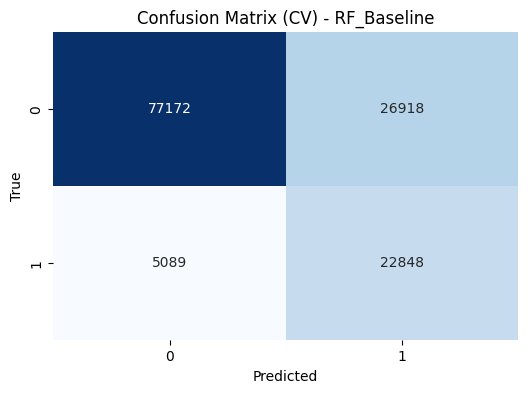

/tmp/ipython-input-977003404.py:211: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




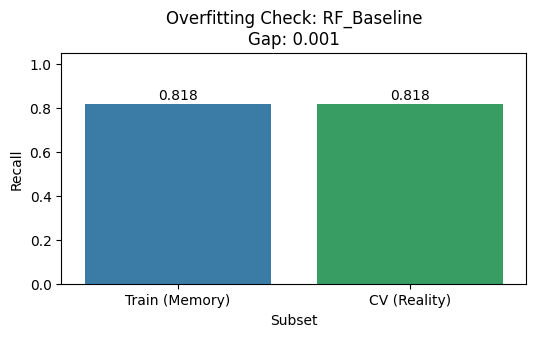

📈 Статичный график метрик (CV Data):


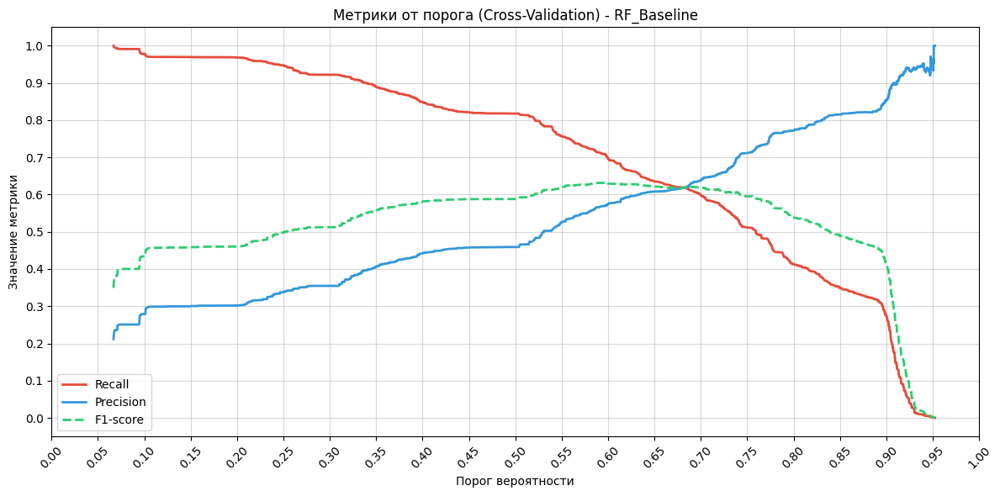

🔍 Важность признаков:


/tmp/ipython-input-977003404.py:237: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




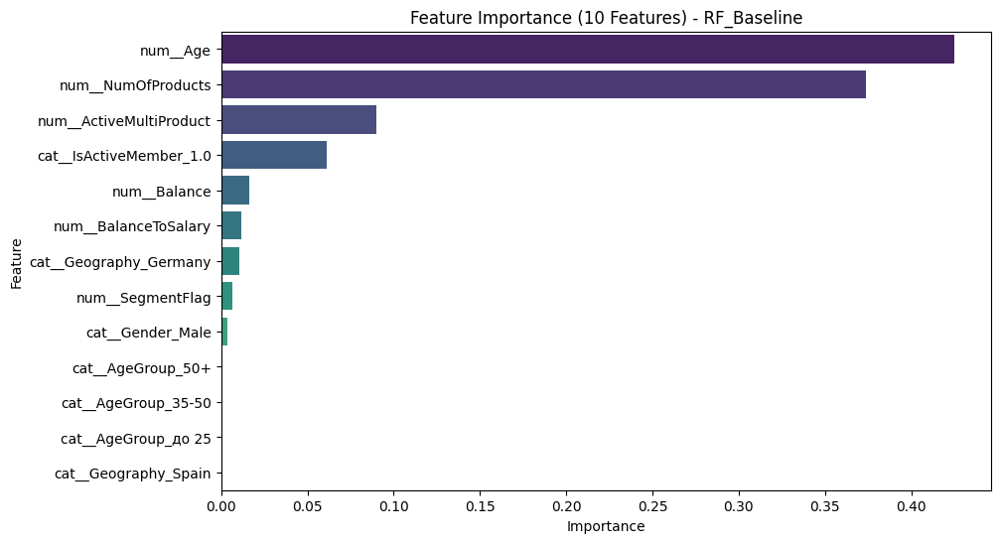


⚙️ АНАЛИЗ МЕТОДА: RF_SMOTE
n_iterations: 5
n_required_iterations: 5
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 243
n_resources: 1620
Fitting 3 folds for each of 243 candidates, totalling 729 fits
----------
iter: 1
n_candidates: 81
n_resources: 4860
Fitting 3 folds for each of 81 candidates, totalling 243 fits
----------
iter: 2
n_candidates: 27
n_resources: 14580
Fitting 3 folds for each of 27 candidates, totalling 81 fits
----------
iter: 3
n_candidates: 9
n_resources: 43740
Fitting 3 folds for each of 9 candidates, totalling 27 fits
----------
iter: 4
n_candidates: 3
n_resources: 131220
Fitting 3 folds for each of 3 candidates, totalling 9 fits
⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): 2443.16 сек. (40.72 мин.)
✅ Лучшие параметры: {'clf__bootstrap': False, 'clf__max_depth': 4, 'clf__max_features': 0.8, 'clf__min_samples_leaf': 8, 'clf__min_samples_split': 12, 'clf__n_estimators': 180}
🔄 Генерация CV-п

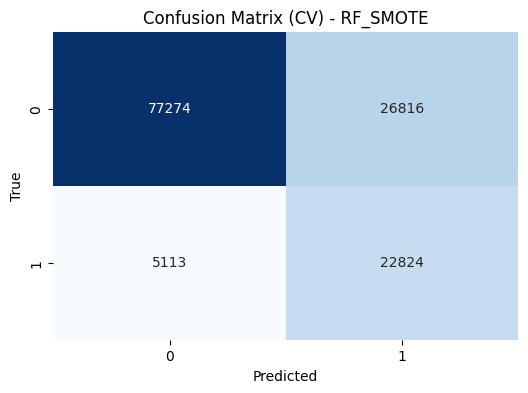

/tmp/ipython-input-977003404.py:211: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




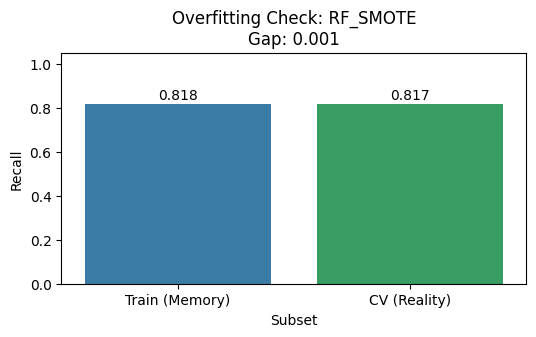

📈 Статичный график метрик (CV Data):


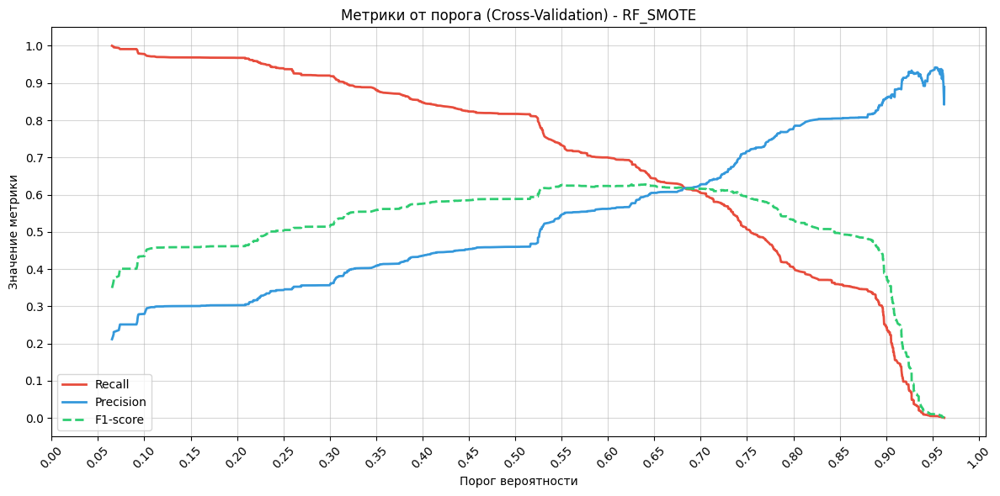

🔍 Важность признаков:


/tmp/ipython-input-977003404.py:237: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




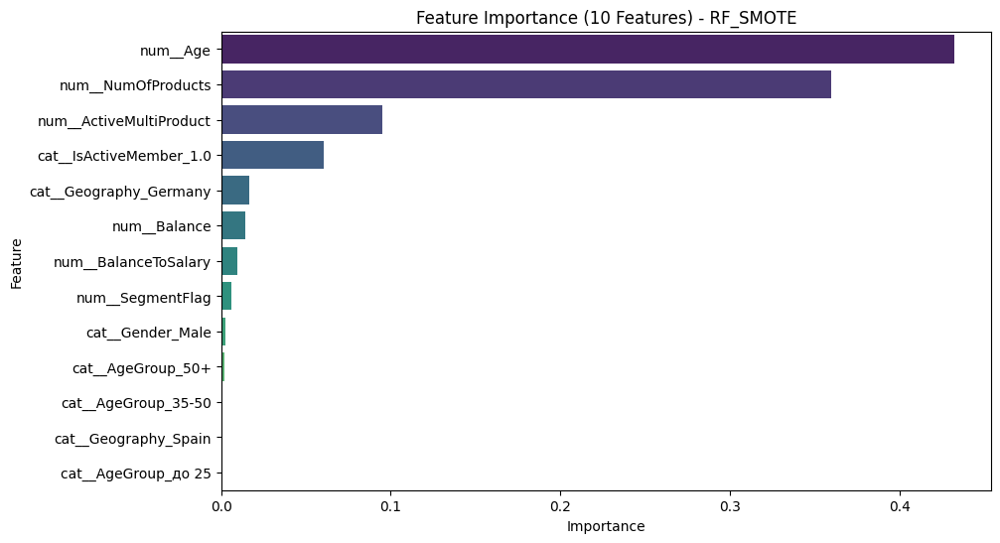


⚙️ АНАЛИЗ МЕТОДА: RF_Undersampling
n_iterations: 5
n_required_iterations: 5
n_possible_iterations: 5
min_resources_: 1620
max_resources_: 132027
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 243
n_resources: 1620
Fitting 3 folds for each of 243 candidates, totalling 729 fits
----------
iter: 1
n_candidates: 81
n_resources: 4860
Fitting 3 folds for each of 81 candidates, totalling 243 fits
----------
iter: 2
n_candidates: 27
n_resources: 14580
Fitting 3 folds for each of 27 candidates, totalling 81 fits
----------
iter: 3
n_candidates: 9
n_resources: 43740
Fitting 3 folds for each of 9 candidates, totalling 27 fits
----------
iter: 4
n_candidates: 3
n_resources: 131220
Fitting 3 folds for each of 3 candidates, totalling 9 fits
⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): 1208.53 сек. (20.14 мин.)
✅ Лучшие параметры: {'clf__bootstrap': True, 'clf__max_depth': 22, 'clf__max_features': None, 'clf__min_samples_leaf': 6, 'clf__min_samples_split': 8, 'clf__n_estimators': 190}
🔄 Генера

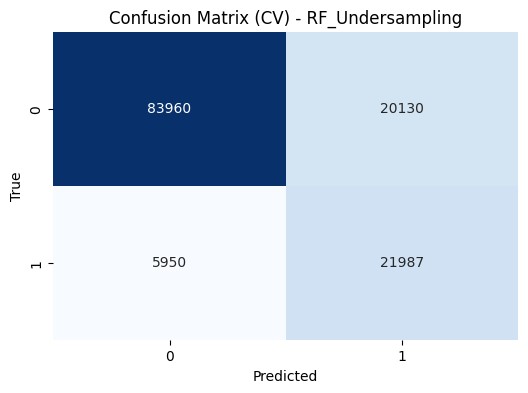

/tmp/ipython-input-977003404.py:211: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




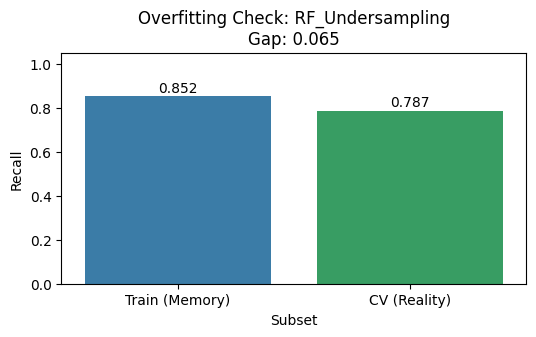

📈 Статичный график метрик (CV Data):


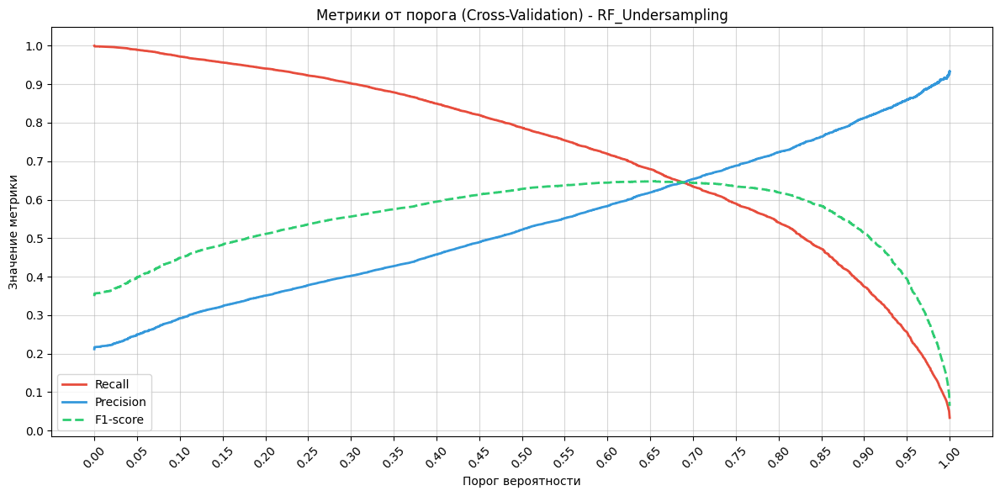

🔍 Важность признаков:


/tmp/ipython-input-977003404.py:237: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




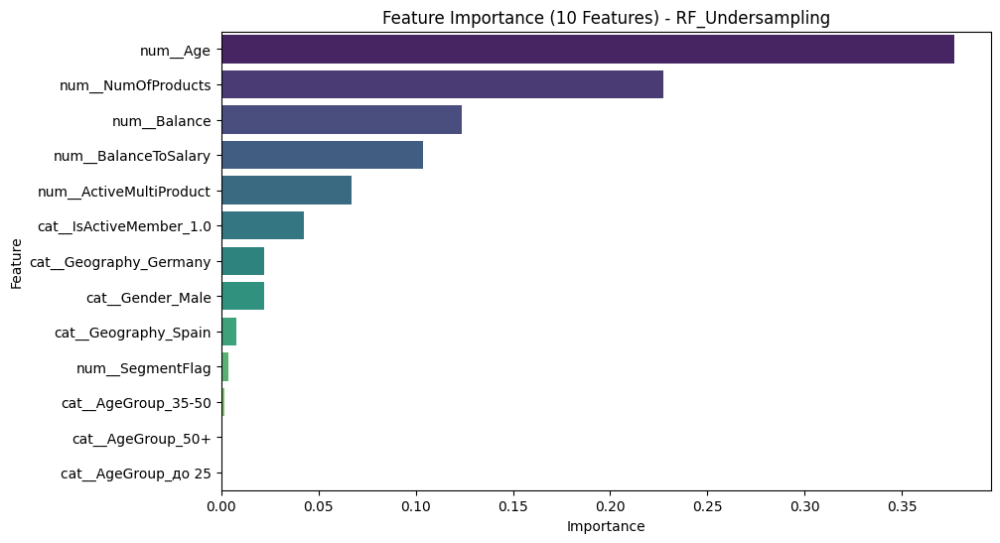


🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)


,Method,Time_Sec,Train_Recall,CV_Recall,CV_Precision,CV_AP,Gap
2,RF_Undersampling,1208.530000,0.851630,0.787021,0.522046,0.697527,0.064610
0,RF_Baseline,1673.820000,0.818377,0.817840,0.459109,0.684387,0.000537
1,RF_SMOTE,2443.160000,0.818377,0.816981,0.459790,0.677701,0.001396


In [ ]:
# 1. Установка библиотек
# !pip install -q imbalanced-learn tqdm plotly

# 2. Импорты
import time  # <--- ДОБАВЛЕН ИМПОРТ ВРЕМЕНИ

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import HalvingRandomSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from tqdm.auto import tqdm

# ==============================================================================
# 1. ПРЕПРОЦЕССОР (10 ИЗБРАННЫХ ПРИЗНАКОВ)
# ==============================================================================

# Числовые
rf_numeric_cols = [
    "Age",
    "NumOfProducts",
    "Balance",
    "BalanceToSalary",
    "ActiveMultiProduct",
    "SegmentFlag",
]

# Категориальные (включая бинарные и группы)
rf_cat_cols = ["IsActiveMember", "Geography", "Gender", "AgeGroup"]

numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
    ]
)

# remainder='drop' удаляет всё, что не вошло в списки выше
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, rf_numeric_cols),
        ("cat", categorical_transformer, rf_cat_cols),
    ],
    remainder="drop",
)

print(
    f"⚙️ Preprocessor: Используем {len(rf_numeric_cols) + len(rf_cat_cols)} признаков (10 Selected Features)."
)

# ==============================================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ (СТАТИЧНЫЕ ДЛЯ ЦИКЛА)
# ==============================================================================


def plot_static_threshold_curve(y_true, y_proba, title):
    """
    Статичный график метрик от порога.
    Строится на данных кросс-валидации внутри цикла.
    """
    prec, rec, thresholds = precision_recall_curve(y_true, y_proba)
    # Убираем последнюю точку для синхронизации размеров
    prec = prec[:-1]
    rec = rec[:-1]
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)

    plt.figure(figsize=(12, 6))
    plt.plot(thresholds, rec, label="Recall", color="#e74c3c", linewidth=2)
    plt.plot(thresholds, prec, label="Precision", color="#3498db", linewidth=2)
    plt.plot(thresholds, f1_scores, label="F1-score", color="#2ecc71", linewidth=2, linestyle="--")

    plt.title(f"Метрики от порога (Cross-Validation) - {title}")
    plt.xlabel("Порог вероятности")
    plt.ylabel("Значение метрики")

    # Сетка с шагом 0.05
    plt.xticks(np.arange(0.0, 1.01, 0.05), rotation=45)
    plt.yticks(np.arange(0.0, 1.01, 0.1))
    plt.grid(True, alpha=0.5, which="both")
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 3. НАСТРОЙКИ
# ==============================================================================

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rf_pipelines = {
    "RF_Baseline": Pipeline(
        steps=[
            ("preprocessor", rf_preprocessor),
            ("clf", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]
    ),
    "RF_SMOTE": ImbPipeline(
        steps=[
            ("preprocessor", rf_preprocessor),
            ("smote", SMOTE(random_state=42, k_neighbors=5)),
            ("clf", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]
    ),
    "RF_Undersampling": ImbPipeline(
        steps=[
            ("preprocessor", rf_preprocessor),
            ("under", RandomUnderSampler(random_state=42)),
            ("clf", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]
    ),
}

# Параметры (Полный набор)
common_params = {
    "clf__n_estimators": randint(100, 500),
    "clf__max_depth": randint(4, 30),
    "clf__min_samples_leaf": randint(1, 10),
    "clf__min_samples_split": randint(2, 20),
    "clf__max_features": ["sqrt", 0.3, 0.5, 0.8, None],
    "clf__bootstrap": [True, False],
}

rf_param_dists = {
    "RF_Baseline": {**common_params, "clf__class_weight": ["balanced", "balanced_subsample"]},
    "RF_SMOTE": common_params,
    "RF_Undersampling": common_params,
}

# ==============================================================================
# 4. ЗАПУСК ОБУЧЕНИЯ (STRICTLY NO TEST LEAKAGE)
# ==============================================================================

best_models_storage = {}
cv_results_storage = {}  # Храним вероятности CV для финального графика
results_summary = []

print("🚀 Запуск Random Forest (10 Features, Strict CV Only)\n")

for method_name, pipeline in tqdm(rf_pipelines.items(), desc="Общий прогресс", unit="model"):
    tqdm.write(f"\n{'='*80}")
    tqdm.write(f"⚙️ АНАЛИЗ МЕТОДА: {method_name}")
    tqdm.write(f"{'='*80}")

    search = HalvingRandomSearchCV(
        pipeline,
        rf_param_dists[method_name],
        cv=cv_strategy,
        scoring="recall",
        n_candidates=243,
        min_resources=1620,
        factor=3,
        resource="n_samples",
        random_state=42,
        n_jobs=2,
        verbose=1,
    )

    try:
        # --- ДОБАВЛЕНО: ЗАПУСК ТАЙМЕРА ---
        start_time = time.time()

        # Обучаем на Train
        search.fit(X_train, y_train)

        # --- ДОБАВЛЕНО: ОСТАНОВКА ТАЙМЕРА ---
        end_time = time.time()
        training_duration = end_time - start_time
        tqdm.write(
            f"⏱️ ВРЕМЯ ОБУЧЕНИЯ (Fit): {training_duration:.2f} сек. ({training_duration/60:.2f} мин.)"
        )

        best_models_storage[method_name] = search.best_estimator_
        tqdm.write(f"✅ Лучшие параметры: {search.best_params_}")

        # -------------------------------------------------------------
        # ГЕНЕРАЦИЯ CV ДАННЫХ (Эмуляция теста на Train)
        # -------------------------------------------------------------
        tqdm.write("🔄 Генерация CV-прогнозов для аналитики...")
        y_pred_cv = cross_val_predict(
            search.best_estimator_, X_train, y_train, cv=cv_strategy, n_jobs=2
        )
        y_proba_cv = cross_val_predict(
            search.best_estimator_,
            X_train,
            y_train,
            cv=cv_strategy,
            n_jobs=2,
            method="predict_proba",
        )[:, 1]

        # 1. ОТЧЕТ (CV)
        tqdm.write(f"\n📊 CLASSIFICATION REPORT (CV) - {method_name}:")
        print(classification_report(y_train, y_pred_cv))

        # 2. МАТРИЦА ОШИБОК (CV)
        plt.figure(figsize=(6, 4))
        sns.heatmap(
            confusion_matrix(y_train, y_pred_cv), annot=True, fmt="d", cmap="Blues", cbar=False
        )
        plt.title(f"Confusion Matrix (CV) - {method_name}")
        plt.ylabel("True")
        plt.xlabel("Predicted")
        plt.show()

        # 3. ПРОВЕРКА НА ПЕРЕОБУЧЕНИЕ (Train vs CV)
        # Train Score (Память)
        y_pred_train_pure = search.best_estimator_.predict(X_train)
        train_recall = recall_score(y_train, y_pred_train_pure)
        # CV Score (Реальность)
        cv_recall = recall_score(y_train, y_pred_cv)

        gap = train_recall - cv_recall

        metrics_df = pd.DataFrame(
            {"Subset": ["Train (Memory)", "CV (Reality)"], "Recall": [train_recall, cv_recall]}
        )
        plt.figure(figsize=(6, 3))
        sns.barplot(data=metrics_df, x="Subset", y="Recall", palette=["#2980b9", "#27ae60"])
        plt.title(f"Overfitting Check: {method_name}\nGap: {gap:.3f}")
        plt.ylim(0, 1.05)
        for index, row in metrics_df.iterrows():
            plt.text(index, row.Recall + 0.02, f"{row.Recall:.3f}", ha="center")
        plt.show()

        # 4. СТАТИЧНЫЙ ГРАФИК ПОРОГОВ (CV)
        tqdm.write("📈 Статичный график метрик (CV Data):")
        plot_static_threshold_curve(y_train, y_proba_cv, method_name)

        # 5. ВАЖНОСТЬ ПРИЗНАКОВ
        tqdm.write("🔍 Важность признаков:")
        try:
            feature_names = search.best_estimator_.named_steps[
                "preprocessor"
            ].get_feature_names_out()
        except:
            # Fallback
            feature_names = rf_numeric_cols + rf_cat_cols

        importances = search.best_estimator_.named_steps["clf"].feature_importances_

        if len(feature_names) == len(importances):
            feat_imp = pd.DataFrame({"Feature": feature_names, "Importance": importances})
            feat_imp = feat_imp.sort_values(by="Importance", ascending=False)

            plt.figure(figsize=(10, 6))
            sns.barplot(data=feat_imp, x="Importance", y="Feature", palette="viridis")
            plt.title(f"Feature Importance (10 Features) - {method_name}")
            plt.show()
        else:
            print("⚠️ Не удалось сопоставить имена признаков.")

        # Сохранение результатов (БЕЗ ТЕСТА)
        cv_results_storage[method_name] = (y_train, y_proba_cv)

        results_summary.append(
            {
                "Method": method_name,
                "Time_Sec": round(training_duration, 2),  # <--- ДОБАВЛЕНО В ИТОГОВУЮ ТАБЛИЦУ
                "Train_Recall": train_recall,
                "CV_Recall": cv_recall,
                "CV_Precision": precision_score(y_train, y_pred_cv),
                "CV_AP": average_precision_score(y_train, y_proba_cv),
                "Gap": gap,
            }
        )

    except Exception as e:
        tqdm.write(f"❌ ОШИБКА в {method_name}: {e}")
        import traceback

        traceback.print_exc()

# ==============================================================================
# 5. ИТОГОВАЯ ТАБЛИЦА (CV)
# ==============================================================================
print("\n" + "=" * 80)
print("🏆 ИТОГОВАЯ ТАБЛИЦА (По результатам Кросс-Валидации)")
print("=" * 80)

if results_summary:
    final_df = pd.DataFrame(results_summary).sort_values(by="CV_AP", ascending=False)
    # Показываем Time_Sec в таблице
    display(final_df.style.background_gradient(subset=["CV_Recall", "CV_AP"], cmap="Greens"))

In [ ]:
# Импорты для построения графика
import plotly.graph_objects as go
from sklearn.metrics import precision_recall_curve

print("\n" + "=" * 80)
print("📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на CV данных)")
print("Наведи курсор, чтобы увидеть Recall, Precision и Порог для каждой модели.")

# Проверяем, есть ли данные кросс-валидации
if "cv_results_storage" not in globals() or not cv_results_storage:
    print("❌ Ошибка: Нет данных кросс-валидации. Сначала запустите ячейку с обучением моделей!")
else:
    print("✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...")

    fig = go.Figure()

    # Цвета для моделей
    colors = {
        "RF_Baseline": "#1f77b4",  # Синий
        "RF_SMOTE": "#2ca02c",  # Зеленый
        "RF_Undersampling": "#d62728",  # Красный
    }

    # Проходим по каждой модели
    for name, (y_true_cv, y_proba_cv) in cv_results_storage.items():
        # Считаем кривые
        precision, recall, thresholds = precision_recall_curve(y_true_cv, y_proba_cv)

        # Убираем последнюю точку у метрик (она всегда 1.0 или 0.0), чтобы длины совпали с thresholds
        precision = precision[:-1]
        recall = recall[:-1]

        color = colors.get(name, "black")  # Если имя другое, будет черным

        # 1. Линия RECALL (Сплошная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=recall,
                mode="lines",
                name=f"{name} - Recall",
                line=dict(color=color, width=3),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Recall: %{{y:.3f}}<extra></extra>",
            )
        )

        # 2. Линия PRECISION (Пунктирная)
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=precision,
                mode="lines",
                name=f"{name} - Precision",
                line=dict(color=color, width=2, dash="dot"),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Precision: %{{y:.3f}}<extra></extra>",
            )
        )

    # Настройка внешнего вида
    fig.update_layout(
        title="<b>Интерактивный выбор порога (на данных Cross-Validation)</b>",
        xaxis_title="Threshold (Порог вероятности)",
        yaxis_title="Значение метрики (Score)",
        hovermode="x unified",  # Единый курсор-линейка
        width=1000,
        height=700,
        template="plotly_white",
        # Настройка осей
        xaxis=dict(
            range=[0, 1],
            dtick=0.05,  # Шаг сетки по X (0.05)
            showgrid=True,
        ),
        yaxis=dict(
            range=[0, 1.05],
            dtick=0.1,  # Шаг сетки по Y (0.1)
            showgrid=True,
        ),
        # Легенда
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    )

    fig.show()


📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на CV данных)
Наведи курсор, чтобы увидеть Recall, Precision и Порог для каждой модели.
✅ Данные CV найдены. Строим график зависимостей от ПОРОГА...


# Multi-Layer Perceptron

Trial 30 Complete [00h 01m 47s]
val_recall: 0.7342281937599182

Best val_recall So Far: 0.8039373755455017
Total elapsed time: 00h 20m 59s
🏋️ Финальное обучение лучшей модели NN_Undersampling...

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.

Epoch 11: ReduceLROnPlateau reducing learning rate to 0.0024999999441206455.
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step
✅ NN_Undersampling завершен. (Recall: 0.6999, AP: 0.7187)

🏁 ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ (RECALL OPTIMIZED)

🏆 СВОДНАЯ ТАБЛИЦА:


,Method,Test_AP,Train_Recall,Test_Recall,Gap
1,NN_SMOTE,0.724938,0.686402,0.676260,0.010142
2,NN_Undersampling,0.718664,0.706518,0.699885,0.006633
0,NN_Weighted,0.716960,0.782117,0.778494,0.003623



📊 ОТЧЕТ ДЛЯ МЕТОДА: NN_Weighted
✅ Лучшие параметры: L=2, D=0.4, LR=0.01

📄 Classification Report (Test):
              precision    recall  f1-score   support

           0       0.93      0.83      0.88     26023
           1       0.55      0.78      0.65      6984

    accuracy                           0.82     33007
   macro avg       0.74      0.80      0.76     33007
weighted avg       0.85      0.82      0.83     33007



/tmp/ipython-input-1077230763.py:138: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Train', 'Test'], y=[result_data['recall_train'], result_data['recall_test']],


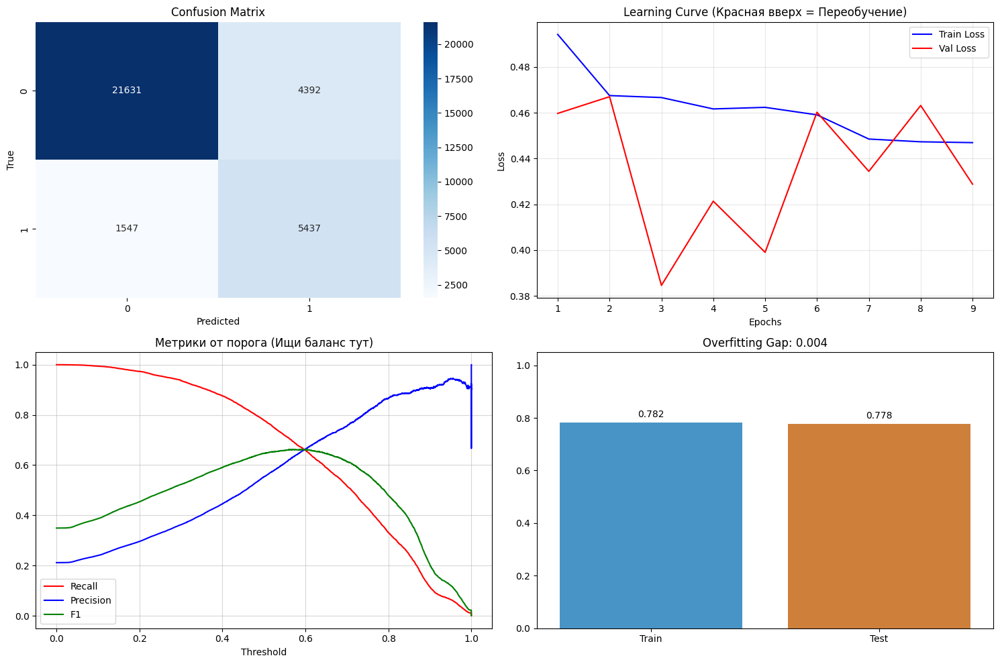


📊 ОТЧЕТ ДЛЯ МЕТОДА: NN_SMOTE
✅ Лучшие параметры: L=4, D=0.4, LR=0.01

📄 Classification Report (Test):
              precision    recall  f1-score   support

           0       0.91      0.90      0.91     26023
           1       0.64      0.68      0.66      6984

    accuracy                           0.85     33007
   macro avg       0.78      0.79      0.78     33007
weighted avg       0.86      0.85      0.85     33007



/tmp/ipython-input-1077230763.py:138: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Train', 'Test'], y=[result_data['recall_train'], result_data['recall_test']],


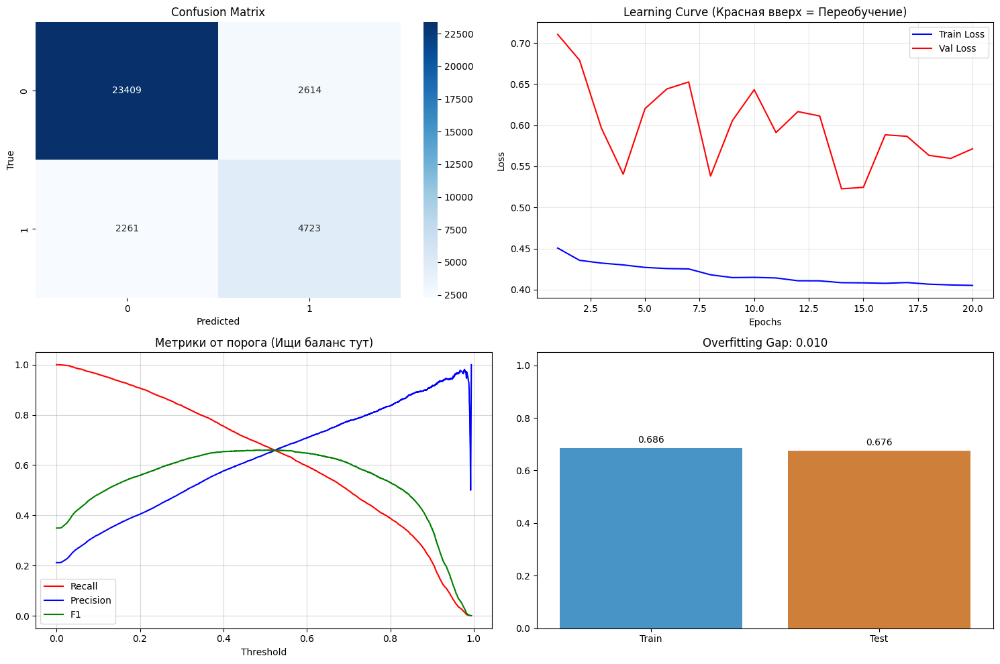


📊 ОТЧЕТ ДЛЯ МЕТОДА: NN_Undersampling
✅ Лучшие параметры: L=4, D=0.30000000000000004, LR=0.01

📄 Classification Report (Test):
              precision    recall  f1-score   support

           0       0.92      0.88      0.90     26023
           1       0.62      0.70      0.66      6984

    accuracy                           0.85     33007
   macro avg       0.77      0.79      0.78     33007
weighted avg       0.85      0.85      0.85     33007



/tmp/ipython-input-1077230763.py:138: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Train', 'Test'], y=[result_data['recall_train'], result_data['recall_test']],


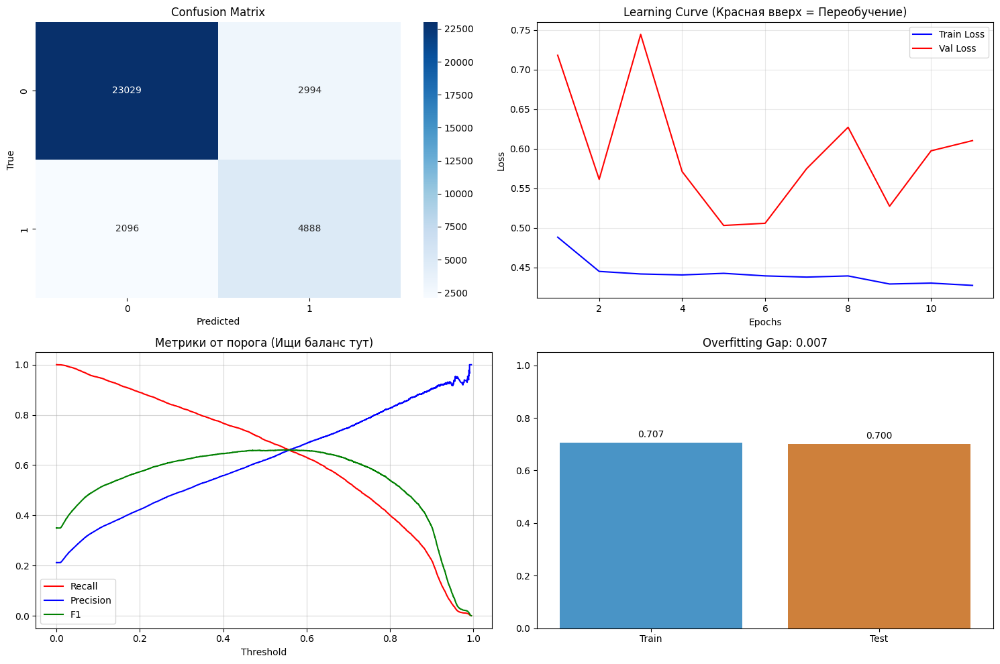

In [ ]:
# 1. Установка
!pip install -q imbalanced-learn keras-tuner

# 2. Импорты
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.utils import class_weight
from tensorflow import keras
from tensorflow.keras import layers
from tqdm.auto import tqdm

# ==============================================================================
# 1. ПОДГОТОВКА ДАННЫХ
# ==============================================================================
print("⚙️ Подготовка данных...")

X_train_proc = preprocessor.fit_transform(X_train, y_train)
X_test_proc = preprocessor.transform(X_test)

if hasattr(X_train_proc, "toarray"):
    X_train_proc = X_train_proc.toarray()
    X_test_proc = X_test_proc.toarray()

print(f"✅ Размерность входа: {X_train_proc.shape[1]} признаков")

# Варианты данных
data_variants = {}

# 1. Weighted
class_weights_vals = class_weight.compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
weights_dict = dict(enumerate(class_weights_vals))

data_variants["NN_Weighted"] = {"X": X_train_proc, "y": y_train, "cw": weights_dict}

# 2. SMOTE
print("   SMOTE generation...")
smote = SMOTE(random_state=42, k_neighbors=5)
X_smote, y_smote = smote.fit_resample(X_train_proc, y_train)
data_variants["NN_SMOTE"] = {"X": X_smote, "y": y_smote, "cw": None}

# 3. Undersampling
print("   Undersampling generation...")
under = RandomUnderSampler(random_state=42)
X_under, y_under = under.fit_resample(X_train_proc, y_train)
data_variants["NN_Undersampling"] = {"X": X_under, "y": y_under, "cw": None}


# ==============================================================================
# 2. МОДЕЛЬ (Target: Recall)
# ==============================================================================
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train_proc.shape[1],)))

    # УСИЛЕННАЯ АРХИТЕКТУРА:
    # Ищем от 1 до 4 слоев, разрешаем много нейронов (до 384)
    for i in range(hp.Int("num_layers", 1, 4)):
        model.add(
            layers.Dense(
                units=hp.Int(f"units_{i}", min_value=64, max_value=384, step=32), activation="relu"
            )
        )
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(hp.Float("dropout", 0.1, 0.4, step=0.1)))

    model.add(layers.Dense(1, activation="sigmoid"))

    lr = hp.Choice("learning_rate", values=[1e-2, 1e-3, 5e-4])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        # ГЛАВНОЕ: Мы вернули Recall как цель оптимизации
        metrics=[keras.metrics.Recall(name="recall")],
    )
    return model


# ==============================================================================
# 3. ФУНКЦИИ ГРАФИКОВ
# ==============================================================================
def plot_full_report(result_data):
    name = result_data["name"]

    print(f"\n{'='*80}")
    print(f"📊 ОТЧЕТ ДЛЯ МЕТОДА: {name}")
    print(f"{'='*80}")

    print(f"✅ Лучшие параметры: {result_data['best_params']}")
    print("\n📄 Classification Report (Test):")
    print(result_data["report"])

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # 1. Confusion Matrix
    sns.heatmap(result_data["cm"], annot=True, fmt="d", cmap="Blues", ax=axes[0, 0])
    axes[0, 0].set_title("Confusion Matrix")
    axes[0, 0].set_ylabel("True")
    axes[0, 0].set_xlabel("Predicted")

    # 2. Learning Curve
    loss = result_data["history"].history["loss"]
    val_loss = result_data["history"].history["val_loss"]
    epochs = range(1, len(loss) + 1)

    axes[0, 1].plot(epochs, loss, "b-", label="Train Loss")
    axes[0, 1].plot(epochs, val_loss, "r-", label="Val Loss")
    axes[0, 1].set_title("Learning Curve (Красная вверх = Переобучение)")
    axes[0, 1].set_xlabel("Epochs")
    axes[0, 1].set_ylabel("Loss")
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # 3. Threshold Metrics
    prec, rec, thresholds = precision_recall_curve(y_test, result_data["y_proba"])
    f1 = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)

    axes[1, 0].plot(thresholds, rec[:-1], "r", label="Recall")
    axes[1, 0].plot(thresholds, prec[:-1], "b", label="Precision")
    axes[1, 0].plot(thresholds, f1, "g", label="F1")
    axes[1, 0].set_title("Метрики от порога (Ищи баланс тут)")
    axes[1, 0].set_xlabel("Threshold")
    axes[1, 0].grid(True, alpha=0.5)
    axes[1, 0].legend()

    # 4. Overfitting Gap
    gap = result_data["recall_train"] - result_data["recall_test"]
    sns.barplot(
        x=["Train", "Test"],
        y=[result_data["recall_train"], result_data["recall_test"]],
        palette=["#3498db", "#e67e22"],
        ax=axes[1, 1],
    )
    axes[1, 1].set_title(f"Overfitting Gap: {gap:.3f}")
    axes[1, 1].set_ylim(0, 1.05)
    for i, v in enumerate([result_data["recall_train"], result_data["recall_test"]]):
        axes[1, 1].text(i, v + 0.02, f"{v:.3f}", ha="center")

    plt.tight_layout()
    plt.show()


# ==============================================================================
# 4. ЗАПУСК (HIGH QUALITY MODE - RECALL OPTIMIZED)
# ==============================================================================
final_results_storage = []
summary_table = []

print("\n🚀 ЗАПУСК: ИЩЕМ МАКСИМАЛЬНЫЙ RECALL (Wait time: ~30-40 mins)...")

for name, data in data_variants.items():
    print(f"\n⏳ Обучение метода: {name} ...")

    keras.backend.clear_session()

    # Callback: Умное уменьшение скорости обучения
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=0.00001, verbose=1
    )

    # Callback: Остановка, если не учится
    stop_early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6)

    # Настройка поиска
    tuner = kt.Hyperband(
        build_model,
        objective=kt.Objective("val_recall", direction="max"),  # <--- ЦЕЛЬ: Максимум Recall
        max_epochs=25,
        factor=3,
        directory="tuning_recall_opt",
        project_name=name,
        overwrite=True,
    )

    # 1. Поиск архитектуры
    tuner.search(
        data["X"],
        data["y"],
        epochs=25,
        validation_split=0.2,
        class_weight=data["cw"],
        callbacks=[stop_early, reduce_lr],
        verbose=1,
    )

    best_hps = tuner.get_best_hyperparameters()[0]

    # 2. Финальное обучение
    print(f"🏋️ Финальное обучение лучшей модели {name}...")
    model = tuner.hypermodel.build(best_hps)
    history = model.fit(
        data["X"],
        data["y"],
        epochs=50,
        validation_split=0.2,
        class_weight=data["cw"],
        callbacks=[stop_early, reduce_lr],
        verbose=0,
    )

    # 3. Сбор результатов
    y_pred_proba = model.predict(X_test_proc).flatten()
    y_pred_test = (y_pred_proba >= 0.5).astype(int)

    y_pred_train_raw = model.predict(X_train_proc).flatten()
    y_pred_train = (y_pred_train_raw >= 0.5).astype(int)

    rec_test = recall_score(y_test, y_pred_test)
    rec_train = recall_score(y_train, y_pred_train)
    ap_test = average_precision_score(y_test, y_pred_proba)

    result_data = {
        "name": name,
        "best_params": f"L={best_hps.get('num_layers')}, D={best_hps.get('dropout')}, LR={best_hps.get('learning_rate')}",
        "report": classification_report(y_test, y_pred_test),
        "cm": confusion_matrix(y_test, y_pred_test),
        "history": history,
        "y_proba": y_pred_proba,
        "recall_train": rec_train,
        "recall_test": rec_test,
        "ap": ap_test,
    }

    final_results_storage.append(result_data)
    summary_table.append(
        {
            "Method": name,
            "Test_AP": ap_test,
            "Train_Recall": rec_train,
            "Test_Recall": rec_test,
            "Gap": rec_train - rec_test,
        }
    )

    print(f"✅ {name} завершен. (Recall: {rec_test:.4f}, AP: {ap_test:.4f})")

# ==============================================================================
# 5. ФИНАЛ
# ==============================================================================
print("\n" + "=" * 80)
print("🏁 ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ (RECALL OPTIMIZED)")
print("=" * 80)

summary_df = pd.DataFrame(summary_table).sort_values(by="Test_AP", ascending=False)
print("\n🏆 СВОДНАЯ ТАБЛИЦА:")
display(summary_df.style.background_gradient(subset=["Test_AP"], cmap="Greens"))

for res in final_results_storage:
    plot_full_report(res)

Trial 30 Complete [00h 00m 26s]
val_recall: 0.8235504627227783

Best val_recall So Far: 0.9708303213119507
Total elapsed time: 00h 08m 17s
🏋️ Финальное обучение...

Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 18: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 20: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 24: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 30: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 32: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
826/826 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
✅ NN_Undersampling завершен. (Val AP: 0.7184)

🏁 РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА (VALIDATION DATA ONLY)

📊 ОТЧЕТ: NN_Weighted
✅ Параметры: L=2, D=0.2, LR=0.0005

📄 Report (Validation):
              precision    recall  f1-score   support

           0       0.92      0.86      0.89     2081

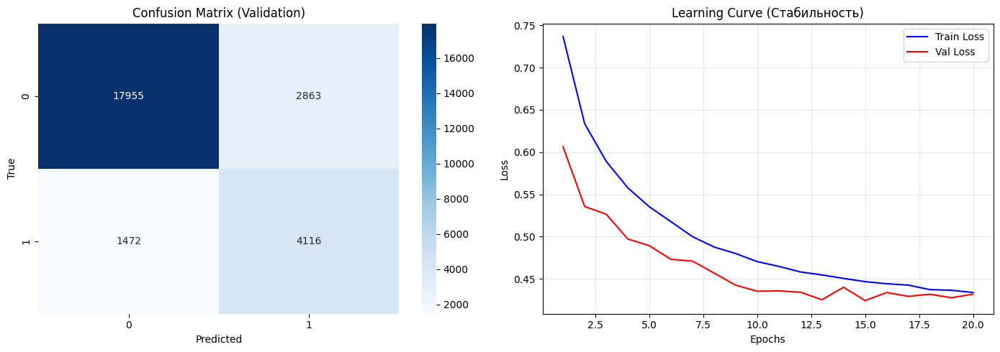

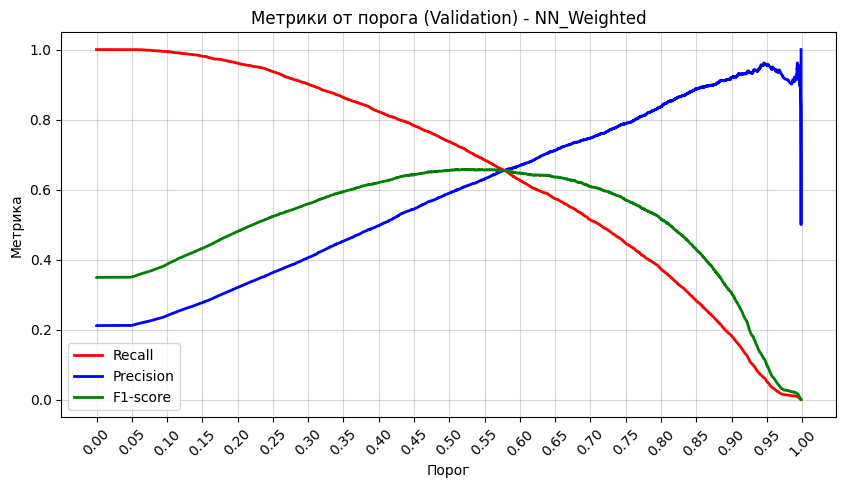

/tmp/ipython-input-3764174760.py:175: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


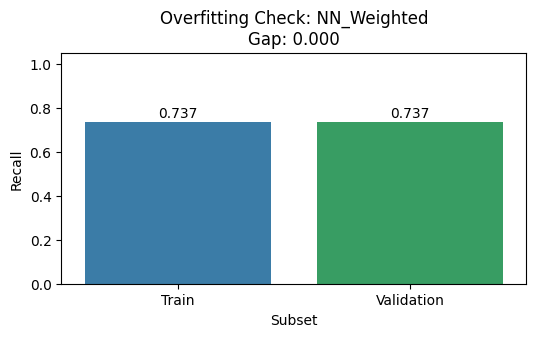


📊 ОТЧЕТ: NN_SMOTE
✅ Параметры: L=2, D=0.4, LR=0.001

📄 Report (Validation):
              precision    recall  f1-score   support

           0       0.93      0.82      0.87     20818
           1       0.54      0.79      0.64      5588

    accuracy                           0.81     26406
   macro avg       0.74      0.80      0.76     26406
weighted avg       0.85      0.81      0.82     26406



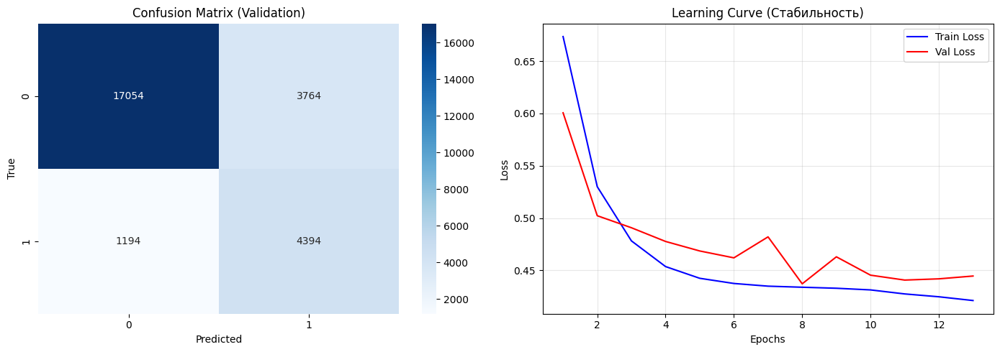

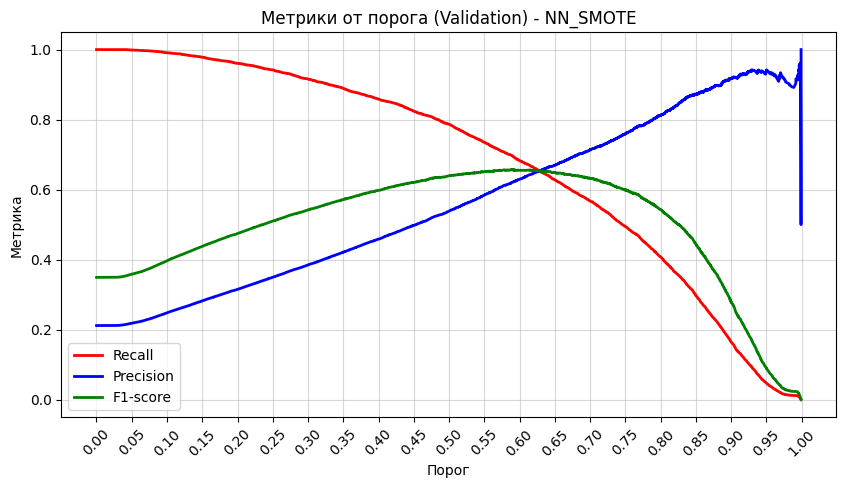

/tmp/ipython-input-3764174760.py:175: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


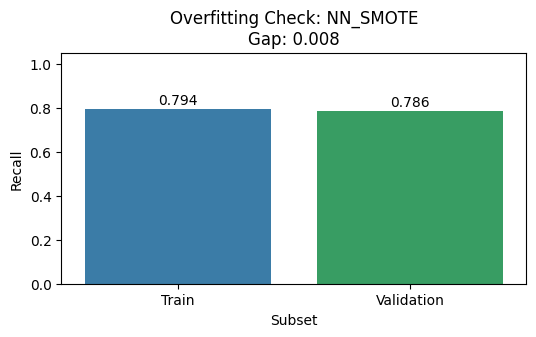


📊 ОТЧЕТ: NN_Undersampling
✅ Параметры: L=2, D=0.4, LR=0.001

📄 Report (Validation):
              precision    recall  f1-score   support

           0       0.94      0.81      0.87     20818
           1       0.53      0.80      0.64      5588

    accuracy                           0.81     26406
   macro avg       0.73      0.80      0.75     26406
weighted avg       0.85      0.81      0.82     26406



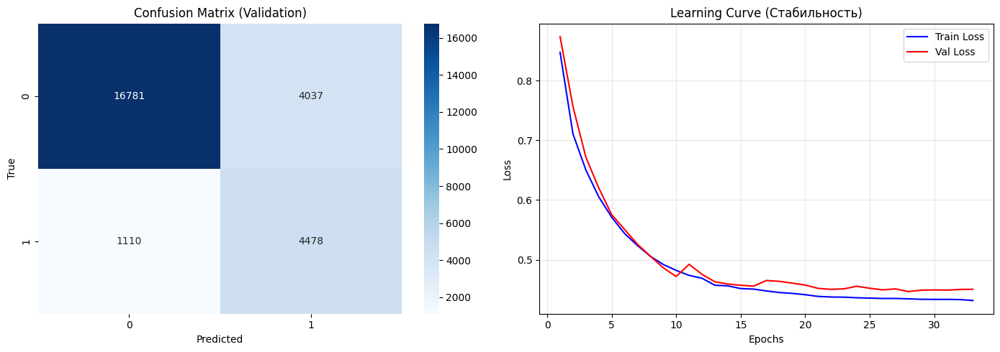

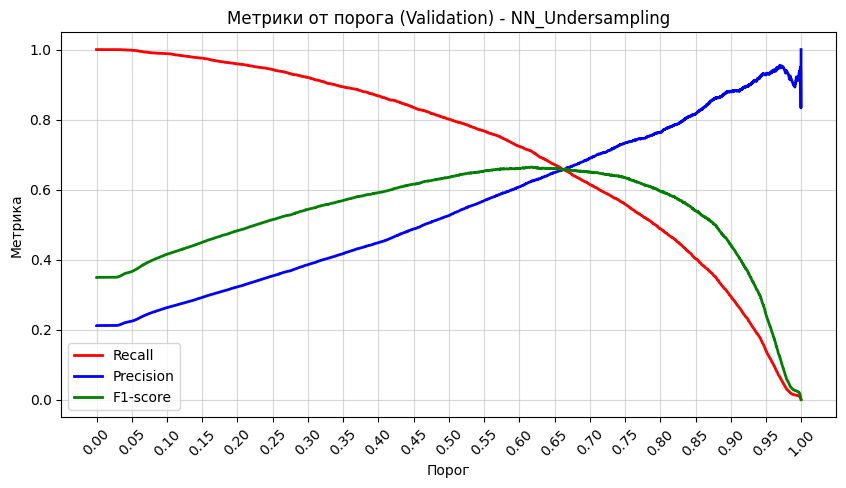

/tmp/ipython-input-3764174760.py:175: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Subset', y='Recall', palette=['#2980b9', '#27ae60'])


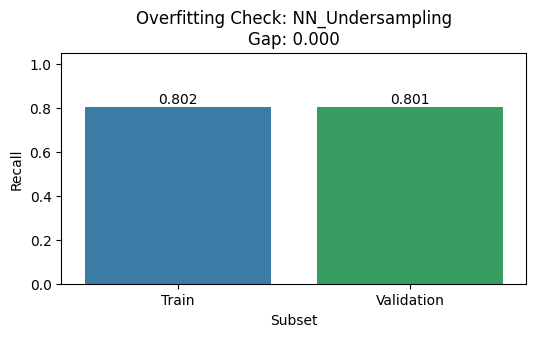


📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на Валидации)
Наведи курсор, чтобы увидеть Recall, Precision и Threshold для каждой модели.


In [ ]:
# 1. Установка
!pip install -q imbalanced-learn keras-tuner plotly

# 2. Импорты
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
import tensorflow as tf
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from tensorflow import keras
from tqdm.auto import tqdm

# ==============================================================================
# 1. ПОДГОТОВКА ДАННЫХ (ТОЛЬКО TRAIN)
# ==============================================================================
print("⚙️ Подготовка данных (X_train)...")

# Применяем препроцессинг только к Train
X_train_proc = preprocessor.fit_transform(X_train, y_train)

# Преобразуем в dense array для Keras
if hasattr(X_train_proc, "toarray"):
    X_train_proc = X_train_proc.toarray()

# -------------------------------------------------------------------------
# ВАЖНО: СОЗДАЕМ ВАЛИДАЦИОННУЮ ВЫБОРКУ ИЗ TRAIN
# Тест мы не трогаем. Мы отрезаем кусочек от Train, чтобы проверять модели.
# -------------------------------------------------------------------------
X_t, X_v, y_t, y_v = train_test_split(
    X_train_proc, y_train, test_size=0.2, stratify=y_train, random_state=42
)

print("✅ Данные разделены:")
print(f"   Обучение (Train subset): {X_t.shape[0]} строк")
print(f"   Валидация (Validation):  {X_v.shape[0]} строк (На этом строим графики)")
print("   Тест: НЕ ИСПОЛЬЗУЕТСЯ")

# Готовим варианты данных (SMOTE применяем ТОЛЬКО к X_t, валидацию не трогаем!)
data_variants = {}

# 1. Weighted (Веса)
class_weights_vals = class_weight.compute_class_weight(
    class_weight="balanced", classes=np.unique(y_t), y=y_t
)
weights_dict = dict(enumerate(class_weights_vals))

data_variants["NN_Weighted"] = {
    "X_train": X_t,
    "y_train": y_t,
    "X_val": X_v,
    "y_val": y_v,
    "cw": weights_dict,
}

# 2. SMOTE (Синтетика только на трейне!)
print("   Генерация SMOTE (только на подвыборке обучения)...")
smote = SMOTE(random_state=42, k_neighbors=5)
X_t_smote, y_t_smote = smote.fit_resample(X_t, y_t)

data_variants["NN_SMOTE"] = {
    "X_train": X_t_smote,
    "y_train": y_t_smote,
    "X_val": X_v,
    "y_val": y_v,  # Валидация чистая, без SMOTE
    "cw": None,
}

# 3. Undersampling
print("   Генерация Undersampling...")
under = RandomUnderSampler(random_state=42)
X_t_under, y_t_under = under.fit_resample(X_t, y_t)

data_variants["NN_Undersampling"] = {
    "X_train": X_t_under,
    "y_train": y_t_under,
    "X_val": X_v,
    "y_val": y_v,
    "cw": None,
}


# ==============================================================================
# 2. МОДЕЛЬ (STABILIZED ARCHITECTURE)
# ==============================================================================
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train_proc.shape[1],)))

    # АРХИТЕКТУРА ДЛЯ СТАБИЛЬНОСТИ
    # Уменьшил шаг дропаута и добавил регуляризацию, чтобы убрать "сердцебиение"
    for i in range(hp.Int("num_layers", 1, 3)):  # До 3 слоев (4 было лишним)
        model.add(
            layers.Dense(
                units=hp.Int(f"units_{i}", min_value=64, max_value=256, step=64),
                activation="relu",
                kernel_regularizer=keras.regularizers.l2(0.001),  # L2 помогает от скачков
            )
        )
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(hp.Float("dropout", 0.2, 0.5, step=0.1)))

    model.add(layers.Dense(1, activation="sigmoid"))

    # Оптимизатор AdamW (лучше сходится) + подбор скорости
    lr = hp.Choice("learning_rate", values=[1e-3, 5e-4, 1e-4])

    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="pr_auc", curve="PR")],
    )
    return model


# ==============================================================================
# 3. ФУНКЦИИ ГРАФИКОВ (НА ВАЛИДАЦИИ)
# ==============================================================================
def plot_static_threshold_curve(y_true, y_proba, title):
    prec, rec, thresholds = precision_recall_curve(y_true, y_proba)
    prec = prec[:-1]
    rec = rec[:-1]
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)

    plt.figure(figsize=(10, 5))
    plt.plot(thresholds, rec, label="Recall", color="red", linewidth=2)
    plt.plot(thresholds, prec, label="Precision", color="blue", linewidth=2)
    plt.plot(thresholds, f1_scores, label="F1-score", color="green", linewidth=2)

    plt.title(f"Метрики от порога (Validation) - {title}")
    plt.xlabel("Порог")
    plt.ylabel("Метрика")
    plt.xticks(np.arange(0.0, 1.01, 0.05), rotation=45)
    plt.grid(True, alpha=0.5)
    plt.legend(loc="lower left")
    plt.show()


def plot_full_report(result_data):
    name = result_data["name"]
    print(f"\n{'='*80}")
    print(f"📊 ОТЧЕТ: {name}")
    print(f"{'='*80}")
    print(f"✅ Параметры: {result_data['best_params']}")
    print("\n📄 Report (Validation):")
    print(result_data["report"])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Матрица ошибок
    sns.heatmap(result_data["cm"], annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title("Confusion Matrix (Validation)")
    axes[0].set_ylabel("True")
    axes[0].set_xlabel("Predicted")

    # 2. Learning Curve (История обучения)
    loss = result_data["history"].history["loss"]
    val_loss = result_data["history"].history["val_loss"]
    epochs = range(1, len(loss) + 1)

    axes[1].plot(epochs, loss, "b-", label="Train Loss")
    axes[1].plot(epochs, val_loss, "r-", label="Val Loss")
    axes[1].set_title("Learning Curve (Стабильность)")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # 3. График порогов (отдельно, чтобы был крупным)
    plot_static_threshold_curve(result_data["y_val"], result_data["y_proba"], name)

    # 4. Проверка на переобучение (Bar chart)
    gap = result_data["recall_train"] - result_data["recall_val"]
    metrics_df = pd.DataFrame(
        {
            "Subset": ["Train", "Validation"],
            "Recall": [result_data["recall_train"], result_data["recall_val"]],
        }
    )
    plt.figure(figsize=(6, 3))
    sns.barplot(data=metrics_df, x="Subset", y="Recall", palette=["#2980b9", "#27ae60"])
    plt.title(f"Overfitting Check: {name}\nGap: {gap:.3f}")
    plt.ylim(0, 1.05)
    for index, row in metrics_df.iterrows():
        plt.text(index, row.Recall + 0.02, f"{row.Recall:.3f}", ha="center")
    plt.show()


# ==============================================================================
# 4. ЗАПУСК (OPTIMIZED & CLEAN)
# ==============================================================================
final_results_storage = []  # Для интерактивного графика
val_predictions_storage = {}  # Словарик для Plotly

print("\n🚀 ЗАПУСК NEURAL NETWORKS (NO TEST LEAKAGE)...")

for name, data in data_variants.items():
    print(f"\n⏳ Обучение метода: {name} ...")

    keras.backend.clear_session()

    # --- СТРАТЕГИЯ СТАБИЛИЗАЦИИ ---
    # Уменьшаем LR если плато, останавливаем если не учится
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
    )
    stop_early = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )

    tuner = kt.Hyperband(
        build_model,
        objective=kt.Objective("val_recall", direction="max"),
        max_epochs=20,  # Снизил с 25 до 20 для скорости
        factor=3,
        directory="tuning_optimized",
        project_name=name,
        overwrite=True,
    )

    # 1. Поиск (Используем явно переданную валидацию!)
    tuner.search(
        data["X_train"],
        data["y_train"],
        validation_data=(data["X_val"], data["y_val"]),  # Явная валидация
        epochs=20,
        batch_size=512,  # Большой батч = меньше шума, быстрее обучение
        class_weight=data["cw"],
        callbacks=[stop_early, reduce_lr],
        verbose=1,
    )

    best_hps = tuner.get_best_hyperparameters()[0]
    # Добавляем большой батч в лучшие параметры, чтобы модель училась быстрее
    best_hps.values["batch_size"] = 512

    # 2. Финальное обучение
    print("🏋️ Финальное обучение...")
    model = tuner.hypermodel.build(best_hps)

    history = model.fit(
        data["X_train"],
        data["y_train"],
        validation_data=(data["X_val"], data["y_val"]),
        epochs=40,  # Даем запас, но early stopping остановит раньше
        batch_size=512,  # УСКОРЕНИЕ
        class_weight=data["cw"],
        callbacks=[stop_early, reduce_lr],
        verbose=0,
    )

    # 3. Сбор результатов (НА ВАЛИДАЦИИ)
    y_proba_val = model.predict(data["X_val"]).flatten()
    y_pred_val = (y_proba_val >= 0.5).astype(int)

    # Предсказание на Train для проверки переобучения
    y_pred_train_raw = model.predict(data["X_train"]).flatten()
    y_pred_train = (y_pred_train_raw >= 0.5).astype(int)

    rec_val = recall_score(data["y_val"], y_pred_val)
    rec_train = recall_score(data["y_train"], y_pred_train)
    ap_val = average_precision_score(data["y_val"], y_proba_val)

    # Сохраняем для финального графика
    val_predictions_storage[name] = (data["y_val"], y_proba_val)

    result_data = {
        "name": name,
        "best_params": f"L={best_hps.get('num_layers')}, D={best_hps.get('dropout')}, LR={best_hps.get('learning_rate')}",
        "report": classification_report(data["y_val"], y_pred_val),
        "cm": confusion_matrix(data["y_val"], y_pred_val),
        "history": history,
        "y_val": data["y_val"],
        "y_proba": y_proba_val,
        "recall_train": rec_train,
        "recall_val": rec_val,
        "ap": ap_val,
    }

    final_results_storage.append(result_data)
    print(f"✅ {name} завершен. (Val AP: {ap_val:.4f})")

# ==============================================================================
# 5. ВЫВОД РЕЗУЛЬТАТОВ (ОТДЕЛЬНЫМ БЛОКОМ)
# ==============================================================================
print("\n" + "=" * 80)
print("🏁 РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА (VALIDATION DATA ONLY)")
print("=" * 80)

# Рисуем детальные графики
for res in final_results_storage:
    plot_full_report(res)

print("\n" + "=" * 80)
print("📊 ФИНАЛЬНЫЙ ИНТЕРАКТИВНЫЙ ГРАФИК (Сравнение на Валидации)")
print("Наведи курсор, чтобы увидеть Recall, Precision и Threshold для каждой модели.")

if val_predictions_storage:
    fig = go.Figure()

    colors = {
        "NN_Weighted": "#8e44ad",  # Фиолетовый
        "NN_SMOTE": "#d35400",  # Оранжевый
        "NN_Undersampling": "#16a085",  # Бирюзовый
    }

    for name, (y_true_v, y_proba_v) in val_predictions_storage.items():
        precision, recall, thresholds = precision_recall_curve(y_true_v, y_proba_v)

        # Выравнивание длин массивов для графика
        precision = precision[:-1]
        recall = recall[:-1]

        color = colors.get(name, "black")

        # Линия Recall
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=recall,
                mode="lines",
                name=f"{name} - Recall",
                line=dict(color=color, width=3),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Recall: %{{y:.3f}}<extra></extra>",
            )
        )

        # Линия Precision
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=precision,
                mode="lines",
                name=f"{name} - Precision",
                line=dict(color=color, width=2, dash="dot"),
                hovertemplate=f"<b>{name}</b><br>Threshold: %{{x:.3f}}<br>Precision: %{{y:.3f}}<extra></extra>",
            )
        )

    fig.update_layout(
        title="<b>Интерактивный выбор порога (на Валидационной выборке)</b>",
        xaxis_title="Threshold (Порог вероятности)",
        yaxis_title="Значение метрики",
        hovermode="x unified",
        width=1000,
        height=700,
        template="plotly_white",
        xaxis=dict(range=[0, 1], dtick=0.05, showgrid=True),
        yaxis=dict(range=[0, 1.05], dtick=0.1, showgrid=True),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    )
    fig.show()